# Sleep prediction: feature engineering and models (iteration 2)

This notebook continues from the exploration in [`02_exploratory_data_analysis.ipynb`](02_exploratory_data_analysis.ipynb). It only uses what the EDA concluded: the features chosen there, and the decisions about missing values and outliers, now applied to **all** nights. The steps are:

1. Prepare the table
2. Feature engineering: apply the EDA decisions
3. Feature selection: test the chosen features on the validation nights
4. Final models and SHAP

## Setup

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans

# One seed for everything random, so the results are the same every run.
SEED = 0

DATA_DIR = Path("../data/raw/pmdata")
participant_folders = sorted(DATA_DIR.glob("p[0-9][0-9]"))
if not participant_folders:
    raise FileNotFoundError(f"No participant folders found in {DATA_DIR.resolve()}")

## 1. Prepare the table
The same preparation as in the EDA notebook, where each step is explained (the cleaning itself comes from the first notebook). Only the gender and A/B person are added from the participant overview.

In [2]:
sleep_columns = {
    "logId": "sleep_id",
    "dateOfSleep": "sleep_date",
    "startTime": "start_time",
    "endTime": "end_time",
    "minutesAsleep": "minutes_asleep",
}

sleep_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/sleep.json", convert_dates=False)
    main_sleep = records.loc[records["mainSleep"].eq(True), list(sleep_columns)].copy()
    main_sleep["participant_id"] = folder.name
    sleep_tables.append(main_sleep)

sleep = pd.concat(sleep_tables, ignore_index=True).rename(columns=sleep_columns)
for column in ["sleep_date", "start_time", "end_time"]:
    sleep[column] = pd.to_datetime(sleep[column], errors="coerce", format="mixed")
sleep["minutes_asleep"] = pd.to_numeric(sleep["minutes_asleep"], errors="coerce")

# Remove exact duplicates, then average each night with the two calendar nights before it.
sleep_clean = sleep.drop_duplicates(ignore_index=True)
sleep_clean = sleep_clean.sort_values(["participant_id", "sleep_date"]).reset_index(drop=True)
sleep_clean["avg_sleep_last_3_nights"] = (
    sleep_clean.groupby("participant_id")
    .rolling("3D", on="sleep_date")["minutes_asleep"]
    .mean()
    .to_numpy()
)

# The activity window runs from the recorded wake-up time to 21:00.
prediction_days = sleep_clean[["participant_id", "sleep_date", "end_time"]].rename(columns={
    "sleep_date": "date",
    "end_time": "wake_up_time",
})
prediction_days["prediction_time"] = prediction_days["date"] + pd.Timedelta(hours=21)
prediction_days = prediction_days.loc[
    prediction_days["wake_up_time"].notna()
    & (prediction_days["wake_up_time"] < prediction_days["prediction_time"])
].copy()

In [3]:
exercise_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/exercise.json", convert_dates=False)
    records["participant_id"] = folder.name
    exercise_tables.append(records)
exercise_records = pd.concat(exercise_tables, ignore_index=True)

# Expand the activity breakdown into separate columns.
levels = pd.json_normalize(
    exercise_records.to_dict("records"),
    record_path="activityLevel",
    meta=["participant_id", "logId", "activityName", "startTime", "duration"]
).drop_duplicates()
exercise_sessions = levels.pivot(
    index=["participant_id", "logId", "activityName", "startTime", "duration"],
    columns="name",
    values="minutes"
).reset_index()
exercise_sessions.columns.name = None
exercise_sessions = exercise_sessions.rename(columns={
    "logId": "session_id",
    "activityName": "activity_type",
    "startTime": "start_time",
    "lightly": "lightly_active_minutes",
    "fairly": "moderately_active_minutes",
    "very": "very_active_minutes"
})
exercise_sessions["start_time"] = pd.to_datetime(exercise_sessions["start_time"])
duration_ms = pd.to_numeric(exercise_sessions["duration"])
exercise_sessions["end_time"] = exercise_sessions["start_time"] + pd.to_timedelta(duration_ms, unit="ms")

# Minute-level steps taken between waking up and 21:00.
step_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/steps.json", convert_dates=False)
    records["participant_id"] = folder.name
    step_tables.append(records.drop_duplicates())
all_steps = pd.concat(step_tables, ignore_index=True)
all_steps["dateTime"] = pd.to_datetime(all_steps["dateTime"])
all_steps["date"] = all_steps["dateTime"].dt.normalize()

steps_in_window = all_steps.merge(prediction_days, on=["participant_id", "date"])
steps_in_window = steps_in_window.loc[
    (steps_in_window["dateTime"] >= steps_in_window["wake_up_time"])
    & (steps_in_window["dateTime"] < steps_in_window["prediction_time"])
]
window_steps = (
    steps_in_window.groupby(["participant_id", "date"])["value"]
    .sum().rename("steps").reset_index()
)

# Sessions that started after waking up and ended by 21:00.
sessions = exercise_sessions.assign(date=exercise_sessions["start_time"].dt.normalize())
sessions = sessions.merge(prediction_days, on=["participant_id", "date"])
sessions = sessions.loc[
    (sessions["start_time"] >= sessions["wake_up_time"])
    & (sessions["end_time"] <= sessions["prediction_time"])
]
minute_columns = ["lightly_active_minutes", "moderately_active_minutes", "very_active_minutes"]
window_sessions = (
    sessions.groupby(["participant_id", "date"])
    .agg(session_count=("session_id", "size"), **{c: (c, "sum") for c in minute_columns})
    .reset_index()
)

last_session = sessions.sort_values("end_time").groupby(["participant_id", "date"]).tail(1)
last_session = last_session.assign(
    min_since_last_activity=(
        last_session["prediction_time"] - last_session["end_time"]
    ).dt.total_seconds() / 60
)[["participant_id", "date", "activity_type", "min_since_last_activity"]]
last_session = last_session.rename(columns={"activity_type": "last_activity"})

daily_activity = prediction_days
for table in [window_steps, window_sessions, last_session]:
    daily_activity = daily_activity.merge(
        table, on=["participant_id", "date"], how="left", validate="one_to_one"
    )
session_columns = ["session_count"] + minute_columns
daily_activity[session_columns] = daily_activity[session_columns].fillna(0).astype(int)
daily_activity["last_activity"] = daily_activity["last_activity"].fillna("None")

In [4]:
previous_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "start_time": "previous_bedtime",
    "minutes_asleep": "previous_sleep_minutes",
}).drop(columns=["sleep_id", "end_time"])

following_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "minutes_asleep": "next_sleep_minutes",
})[["participant_id", "date", "next_sleep_minutes"]]
# Match sleep ending on Wednesday to Tuesday's activity.
following_sleep["date"] = following_sleep["date"] - pd.Timedelta(days=1)

combined_data = (
    daily_activity
    .merge(previous_sleep, on=["participant_id", "date"], how="left", validate="one_to_one")
    .merge(following_sleep, on=["participant_id", "date"], how="left", validate="one_to_one")
)

combined_data = combined_data.loc[combined_data["participant_id"] != "p12"]
combined_data = combined_data.dropna(subset=["next_sleep_minutes"])
combined_data = combined_data.loc[combined_data["steps"].notna()].reset_index(drop=True)

def clock_hours(times):
    """Hours from midnight, with evening times (18:00 or later) counted as negative."""
    hours = times.dt.hour + times.dt.minute / 60
    return hours.where(hours < 18, hours - 24)

# Find the same short-night groups as the first notebook and remove group 3.
nights = sleep_clean.assign(
    date=sleep_clean["sleep_date"] - pd.Timedelta(days=1),
    start_hour=clock_hours(sleep_clean["start_time"]),
    end_hour=clock_hours(sleep_clean["end_time"]),
)
nights["end_hour"] = nights["end_hour"].where(nights["end_hour"] >= nights["start_hour"], nights["end_hour"] + 24)
short_nights = (
    combined_data.loc[
        combined_data["next_sleep_minutes"].between(60, 240),
        ["participant_id", "date", "next_sleep_minutes"]
    ]
    .merge(nights[["participant_id", "date", "start_hour", "end_hour"]], on=["participant_id", "date"])
)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED)
short_nights["group"] = kmeans.fit_predict(short_nights[["start_hour", "end_hour"]])
group_order = short_nights.groupby("group")["start_hour"].median().sort_values().index
short_nights["group"] = short_nights["group"].map({group: number for number, group in enumerate(group_order, start=1)})
group_3_keys = short_nights.loc[short_nights["group"] == 3].set_index(["participant_id", "date"]).index
combined_keys = combined_data.set_index(["participant_id", "date"]).index
combined_data = combined_data.loc[~combined_keys.isin(group_3_keys)].reset_index(drop=True)

In [5]:
candidates = combined_data[["participant_id", "date"]].copy()

wake_up = combined_data["wake_up_time"]
candidates["wake_up_hour"] = wake_up.dt.hour + wake_up.dt.minute / 60
bedtime = combined_data["previous_bedtime"]
bedtime_hour = bedtime.dt.hour + bedtime.dt.minute / 60
candidates["previous_bedtime_hour"] = bedtime_hour.where(bedtime_hour < 12, bedtime_hour - 24)

ready_columns = [
    "previous_sleep_minutes", "avg_sleep_last_3_nights", "steps", "session_count",
    *minute_columns, "last_activity", "min_since_last_activity", "next_sleep_minutes",
]
candidates[ready_columns] = combined_data[ready_columns]

# On days without a session, count the whole time from wake-up to 21:00.
minutes_awake = (combined_data["prediction_time"] - combined_data["wake_up_time"]).dt.total_seconds() / 60
candidates["min_since_last_activity"] = candidates["min_since_last_activity"].fillna(minutes_awake)

candidates["weekday"] = candidates["date"].dt.day_name()
candidates["weekend_night"] = candidates["date"].dt.dayofweek.isin([4, 5]).astype(int)

In [6]:
wellness_features = ["stress", "fatigue", "mood", "sleep_quality"]

wellness_tables = []
for folder in participant_folders:
    records = pd.read_csv(folder / "pmsys/wellness.csv")
    records["participant_id"] = folder.name
    wellness_tables.append(records)
wellness = pd.concat(wellness_tables, ignore_index=True)
wellness["reported_at"] = pd.to_datetime(wellness["effective_time_frame"], utc=True, errors="coerce")

wellness_clean = wellness.copy()
wellness_clean["date"] = wellness_clean["reported_at"].dt.tz_localize(None).dt.normalize()
for participant, date in [("p03", "2020-02-02"), ("p13", "2019-12-21")]:
    reports = wellness_clean.loc[
        wellness_clean["participant_id"].eq(participant)
        & wellness_clean["date"].eq(pd.Timestamp(date))
    ]
    wellness_clean.loc[reports["reported_at"].idxmin(), "date"] -= pd.Timedelta(days=1)

valid_wellness_scores = (
    wellness_clean[wellness_features].ge(1) & wellness_clean[wellness_features].le(5)
).all(axis=1)
wellness_clean = (
    wellness_clean.loc[valid_wellness_scores]
    .sort_values(["participant_id", "date", "reported_at"])
    .drop_duplicates(["participant_id", "date"], keep="first")
)
wellness_inputs = wellness_clean.set_index(["participant_id", "date"])[wellness_features].rename(
    columns={"sleep_quality": "previous_sleep_quality"}
)

candidates = candidates.join(wellness_inputs, on=["participant_id", "date"], validate="one_to_one")
wellness_nights = candidates[["participant_id", "date"]].loc[candidates["stress"].notna()]

In [7]:
nutrition_tables = []
for folder in participant_folders:
    report_file = folder / "googledocs/reporting.csv"
    if report_file.is_file():
        records = pd.read_csv(report_file)
        records["participant_id"] = folder.name
        nutrition_tables.append(records)

nutrition_reports = pd.concat(nutrition_tables, ignore_index=True)
nutrition_reports["report_date"] = pd.to_datetime(nutrition_reports["date"], format="%d/%m/%Y", errors="coerce")
nutrition_reports["submitted_at"] = pd.to_datetime(
    nutrition_reports["timestamp"], format="%d/%m/%Y %H:%M:%S", errors="coerce"
)
nutrition_answer_columns = [
    "participant_id", "date", "meals", "weight", "glasses_of_fluid", "alcohol_consumed"
]
nutrition_day_keys = ["participant_id", "report_date"]

# Only the reports that describe a night with a wellness report.
nutrition_diagnostics = nutrition_reports.merge(
    wellness_nights.rename(columns={"date": "report_date"}),
    on=nutrition_day_keys, how="inner", validate="many_to_one",
)
nutrition_diagnostics["gap_days"] = (
    nutrition_diagnostics["submitted_at"].dt.normalize() - nutrition_diagnostics["report_date"]
).dt.days

# Remove identical copies, keeping the earliest one submitted on or after its date.
nutrition_diagnostics["valid_date_order"] = nutrition_diagnostics["gap_days"].ge(0)
nutrition_deduplicated = (
    nutrition_diagnostics.sort_values(["valid_date_order", "submitted_at"], ascending=[False, True], kind="stable")
    .drop_duplicates(nutrition_answer_columns, keep="first")
    .sort_values(["participant_id", "report_date", "submitted_at"])
    .copy()
)

# Reports submitted before their date: move them when the proposed date is free, otherwise remove them.
early_nutrition_reports = nutrition_deduplicated.loc[nutrition_deduplicated["gap_days"].lt(0)]
date_comparison = early_nutrition_reports[["participant_id", "report_date", "submitted_at", "gap_days"]].copy()
date_comparison["proposed_date"] = date_comparison["report_date"] - pd.DateOffset(months=1)
one_day_early = date_comparison["gap_days"].eq(-1)
date_comparison.loc[one_day_early, "proposed_date"] = date_comparison.loc[one_day_early, "submitted_at"].dt.normalize()

reported_dates = set(zip(nutrition_reports["participant_id"], nutrition_reports["report_date"]))
iteration_2_dates = set(zip(wellness_nights["participant_id"], wellness_nights["date"]))
move_report = pd.Series([
    (person, day) not in reported_dates and (person, day) in iteration_2_dates
    for person, day in zip(date_comparison["participant_id"], date_comparison["proposed_date"])
], index=date_comparison.index)

nutrition_clean = nutrition_deduplicated.copy()
nutrition_clean.loc[date_comparison.index[move_report], "report_date"] = date_comparison.loc[move_report, "proposed_date"]
nutrition_clean = nutrition_clean.drop(index=date_comparison.index[~move_report])

# p14, 17–20 November: separate meal reports, added up into one report per day.
p14_meal_days = nutrition_clean["participant_id"].eq("p14") & nutrition_clean["report_date"].between(
    "2019-11-17", "2019-11-20"
)
p14_meal_reports = nutrition_clean.loc[p14_meal_days].sort_values("submitted_at").copy()
p14_meal_reports["meals"] = p14_meal_reports.groupby(nutrition_day_keys)["meals"].transform(", ".join)
p14_meal_reports["glasses_of_fluid"] = p14_meal_reports.groupby(nutrition_day_keys)["glasses_of_fluid"].transform("sum")
nutrition_clean = pd.concat([
    nutrition_clean.loc[~p14_meal_days],
    p14_meal_reports.drop_duplicates(nutrition_day_keys, keep="last"),
]).sort_values(["participant_id", "report_date", "submitted_at"])

# Other same-day pairs: the earlier submission describes the previous day.
nutrition_multiple_reports = nutrition_clean.loc[nutrition_clean.duplicated(nutrition_day_keys, keep=False)]
same_day_reports = nutrition_multiple_reports.groupby(nutrition_day_keys).filter(
    lambda reports: reports["submitted_at"].dt.normalize().nunique() == 1
)
reports_to_move = same_day_reports.groupby(nutrition_day_keys).head(1)
nutrition_clean.loc[reports_to_move.index, "report_date"] = reports_to_move["report_date"] - pd.Timedelta(days=1)
nutrition_clean = nutrition_clean.sort_values(["participant_id", "report_date", "submitted_at"])

# Remaining conflicts: keep the first report, the next-day correction, or move a month-late report.
conflicting_reports = nutrition_clean.loc[nutrition_clean.duplicated(nutrition_day_keys, keep=False)]
first_report_nights = {
    ("p13", "2019-11-22"), ("p13", "2019-11-23"),
    ("p05", "2020-02-03"), ("p06", "2019-12-13"),
    ("p06", "2020-02-02"), ("p08", "2019-12-22"),
    ("p10", "2020-01-16"), ("p04", "2020-02-29"),
}
selected_reports = []
for (person, day), reports in conflicting_reports.groupby(nutrition_day_keys):
    if (person, day.strftime("%Y-%m-%d")) in first_report_nights:
        selected = reports.head(1).copy()
    elif reports["submitted_at"].iloc[1].normalize() == day + pd.Timedelta(days=1):
        selected = reports.tail(1).copy()
    else:
        selected = reports.copy()
        selected.loc[reports.index[1], "report_date"] = day + pd.DateOffset(months=1)
    selected_reports.append(selected[nutrition_clean.columns])
nutrition_clean = pd.concat([
    nutrition_clean.loc[~nutrition_clean.index.isin(conflicting_reports.index)],
    *selected_reports,
]).sort_values(["participant_id", "report_date", "submitted_at"])

nutrition_keys = pd.MultiIndex.from_frame(nutrition_clean[nutrition_day_keys])
wellness_keys = pd.MultiIndex.from_frame(wellness_nights)

nutrition_inputs = nutrition_clean.drop(columns="date").rename(columns={"report_date": "date"}).set_index(["participant_id", "date"])
meal_lists = nutrition_inputs["meals"].str.split(", ")
nutrition_inputs = pd.DataFrame({
    "meal_count": meal_lists.apply(lambda meals: len(set(meals))),
    "had_breakfast": meal_lists.apply(lambda meals: "Breakfast" in meals).astype(int),
    # "Evening" is the Norwegian evening meal (kveldsmat), a separate, later meal than "Dinner" (middag).
    "had_evening_meal": meal_lists.apply(lambda meals: "Evening" in meals).astype(int),
    "glasses_of_fluid": nutrition_inputs["glasses_of_fluid"],
    "drank_alcohol": nutrition_inputs["alcohol_consumed"].map({"Yes": 1, "No": 0}),
})

# Nutrition was cleaned for the wellness nights only, so it is matched to those nights.
has_wellness = candidates["stress"].notna()
candidates = candidates.join(nutrition_inputs, on=["participant_id", "date"], validate="one_to_one")
candidates.loc[~has_wellness, nutrition_inputs.columns] = np.nan

In [8]:
# Extra morning-report answers: readiness (0-10), soreness (1-5) and self-reported hours slept.
extra_wellness = wellness_clean.set_index(["participant_id", "date"])[["readiness", "soreness", "sleep_duration_h"]]
extra_wellness = extra_wellness.rename(columns={"sleep_duration_h": "reported_sleep_hours"})
extra_wellness["soreness"] = extra_wellness["soreness"].where(extra_wellness["soreness"].between(1, 5))
extra_wellness["reported_sleep_hours"] = extra_wellness["reported_sleep_hours"].where(
    extra_wellness["reported_sleep_hours"].gt(0)
)
candidates = candidates.join(extra_wellness, on=["participant_id", "date"], validate="one_to_one")

# Details of the previous night, known as soon as the participant wakes up.
detail_rows = []
for folder in participant_folders:
    for record in json.load(open(folder / "fitbit/sleep.json")):
        if record.get("mainSleep") and record.get("type") == "stages":
            stages = record["levels"]["summary"]
            detail_rows.append({
                "participant_id": folder.name,
                "sleep_id": record["logId"],
                "previous_deep_minutes": stages["deep"]["minutes"],
                "previous_rem_minutes": stages["rem"]["minutes"],
                "previous_awake_minutes": stages["wake"]["minutes"],
                "previous_efficiency": record["efficiency"],
            })
sleep_details = pd.DataFrame(detail_rows).drop_duplicates(["participant_id", "sleep_id"])

score_tables = []
for folder in participant_folders:
    records = pd.read_csv(folder / "fitbit/sleep_score.csv")
    records["participant_id"] = folder.name
    score_tables.append(records)
sleep_scores = pd.concat(score_tables, ignore_index=True).rename(columns={
    "sleep_log_entry_id": "sleep_id",
    "overall_score": "previous_sleep_score",
    "restlessness": "previous_restlessness",
})[["participant_id", "sleep_id", "previous_sleep_score", "previous_restlessness", "resting_heart_rate"]]
sleep_scores = sleep_scores.drop_duplicates(["participant_id", "sleep_id"])

previous_details = (
    sleep_clean[["participant_id", "sleep_date", "sleep_id"]].rename(columns={"sleep_date": "date"})
    .merge(sleep_details, on=["participant_id", "sleep_id"], how="left", validate="one_to_one")
    .merge(sleep_scores, on=["participant_id", "sleep_id"], how="left", validate="one_to_one")
    .drop(columns="sleep_id")
)
candidates = candidates.merge(previous_details, on=["participant_id", "date"], how="left", validate="one_to_one")

# Calories burned between waking up and 21:00, like the steps.
calorie_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/calories.json", convert_dates=False)
    records["participant_id"] = folder.name
    calorie_tables.append(records.drop_duplicates())
all_calories = pd.concat(calorie_tables, ignore_index=True)
all_calories["dateTime"] = pd.to_datetime(all_calories["dateTime"])
all_calories["value"] = pd.to_numeric(all_calories["value"], errors="coerce")
all_calories["date"] = all_calories["dateTime"].dt.normalize()
calories_in_window = all_calories.merge(prediction_days, on=["participant_id", "date"])
calories_in_window = calories_in_window.loc[
    (calories_in_window["dateTime"] >= calories_in_window["wake_up_time"])
    & (calories_in_window["dateTime"] < calories_in_window["prediction_time"])
]
window_calories = calories_in_window.groupby(["participant_id", "date"])["value"].sum().rename("calories")
candidates = candidates.join(window_calories, on=["participant_id", "date"], validate="one_to_one")

In [9]:
# Gender and A/B person (morning or evening type); one gender entry has a hidden space after it.
participant_overview = pd.read_excel(DATA_DIR / "participant-overview.xlsx", header=1).set_index("Participant ID")
candidates["gender"] = candidates["participant_id"].map(participant_overview["Gender"].str.strip())
candidates["ab_type"] = candidates["participant_id"].map(participant_overview["A or B person"])
print(f"Prepared nights: {len(candidates):,}")

Prepared nights: 1,745


In [10]:
candidates.head()

,participant_id,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,...,previous_deep_minutes,previous_rem_minutes,previous_awake_minutes,previous_efficiency,previous_sleep_score,previous_restlessness,resting_heart_rate,calories,gender,ab_type
0,p01,2019-11-02,7.316667,0.150000,378,378.000000,11063.0,1,0,11,...,36.0,83.0,52.0,97.0,79.0,0.078978,53.0,2541.18,male,A
1,p01,2019-11-03,7.566667,0.533333,378,378.000000,13045.0,0,0,0,...,38.0,51.0,44.0,96.0,71.0,0.093491,52.0,2588.02,male,A
2,p01,2019-11-04,6.583333,-0.083333,361,372.333333,7373.0,0,0,0,...,37.0,35.0,38.0,96.0,68.0,0.064851,53.0,2291.62,male,A
3,p01,2019-11-05,6.416667,0.366667,326,355.000000,9574.0,1,13,0,...,27.0,39.0,36.0,99.0,73.0,0.093185,54.0,2495.25,male,A
4,p01,2019-11-06,6.483333,0.416667,341,342.666667,5189.0,0,0,0,...,66.0,38.0,23.0,99.0,67.0,0.064472,52.0,1978.05,male,A


## 2. Feature engineering
### Drop p15
p15 has no nights with a daily report, so there are no earlier values of their own to fill the gaps with (EDA, step 2).

In [11]:
candidates = candidates.loc[candidates["participant_id"] != "p15"].reset_index(drop=True)
print(f"Nights without p15: {len(candidates):,}")

Nights without p15: 1,604


### Nights under 3 hours
Nights shorter than 3 hours are hard outliers (EDA, step 5). If the participant's morning report says they slept 3 hours or more, the reported hours replace the Fitbit value; otherwise the night is dropped. This is done on the sleep records themselves, before the three-night average is calculated again, so the average is built from the corrected nights. The morning report describes the night that ended that morning.

In [12]:
HARD_LIMIT = 180  # minutes

corrected_sleep = sleep_clean[["participant_id", "sleep_date", "minutes_asleep"]].copy()
reported_hours = extra_wellness["reported_sleep_hours"].reindex(
    pd.MultiIndex.from_frame(corrected_sleep[["participant_id", "sleep_date"]])
).to_numpy()
short = corrected_sleep["minutes_asleep"] < HARD_LIMIT
fixable = short & (reported_hours >= 3)
corrected_sleep.loc[fixable, "minutes_asleep"] = reported_hours[fixable] * 60
corrected_sleep = corrected_sleep.loc[~(short & ~fixable)]
print(f"Short nights replaced by the report: {fixable.sum()}; dropped: {(short & ~fixable).sum()}")

# Three-night average again: each night with the two calendar nights before it.
corrected_sleep = corrected_sleep.sort_values(["participant_id", "sleep_date"]).reset_index(drop=True)
corrected_sleep["avg_sleep_last_3_nights"] = (
    corrected_sleep.groupby("participant_id").rolling("3D", on="sleep_date")["minutes_asleep"].mean().to_numpy()
)
sleep_lookup = corrected_sleep.set_index(["participant_id", "sleep_date"])

# The average up to this morning, and the following night (which ends the next day) as the target.
today = pd.MultiIndex.from_arrays([candidates["participant_id"], candidates["date"]])
tomorrow = pd.MultiIndex.from_arrays([candidates["participant_id"], candidates["date"] + pd.Timedelta(days=1)])
candidates["avg_sleep_last_3_nights"] = sleep_lookup["avg_sleep_last_3_nights"].reindex(today).to_numpy()
candidates["next_sleep_minutes"] = sleep_lookup["minutes_asleep"].reindex(tomorrow).to_numpy()

rows_before = len(candidates)
candidates = candidates.dropna(subset=["next_sleep_minutes", "avg_sleep_last_3_nights"]).reset_index(drop=True)
print(f"Nights dropped because their target or average was a dropped short night: {rows_before - len(candidates)}")
print(f"Nights remaining: {len(candidates):,}")

Short nights replaced by the report: 21; dropped: 10
Nights dropped because their target or average was a dropped short night: 10
Nights remaining: 1,594


### Training, validation and test nights
Now that p15 and the short nights are dropped, the nights are split by date per participant: the first 60% for training, the next 20% for validation and the last 20% for the final test. The validation nights are used to compare the feature groups in feature selection, so the test nights stay untouched until the very end. Because a few nights were dropped, the boundaries move slightly compared with the EDA: 4 of the test nights were also looked at in the EDA, which is too few to matter.

In [13]:
candidates = candidates.sort_values(["participant_id", "date"]).reset_index(drop=True)
night_number = candidates.groupby("participant_id").cumcount()
nights_per_person = candidates.groupby("participant_id")["date"].transform("size")
candidates["split"] = np.select(
    [night_number < (nights_per_person * 0.6).astype(int), night_number < (nights_per_person * 0.8).astype(int)],
    ["train", "validation"],
    default="test",
)
# Nights per participant in each part: every participant gets 60/20/20 of their own nights.
split_counts = candidates.groupby(["participant_id", "split"]).size().unstack()[["train", "validation", "test"]]
split_counts["total"] = split_counts.sum(axis=1)
split_counts.loc["All participants"] = split_counts.sum()
split_counts

split,train,validation,test,total
participant_id,,,,
p01,88,30,30,148
p02,81,27,28,136
p03,31,11,11,53
p04,82,27,28,137
p05,64,21,22,107
p06,87,29,29,145
p07,81,27,28,136
p08,76,25,26,127
p09,69,23,24,116


### What is missing in the chosen features
Before filling anything, I want to see which of the features chosen in the EDA still have gaps, how many nights, and whose nights they are.

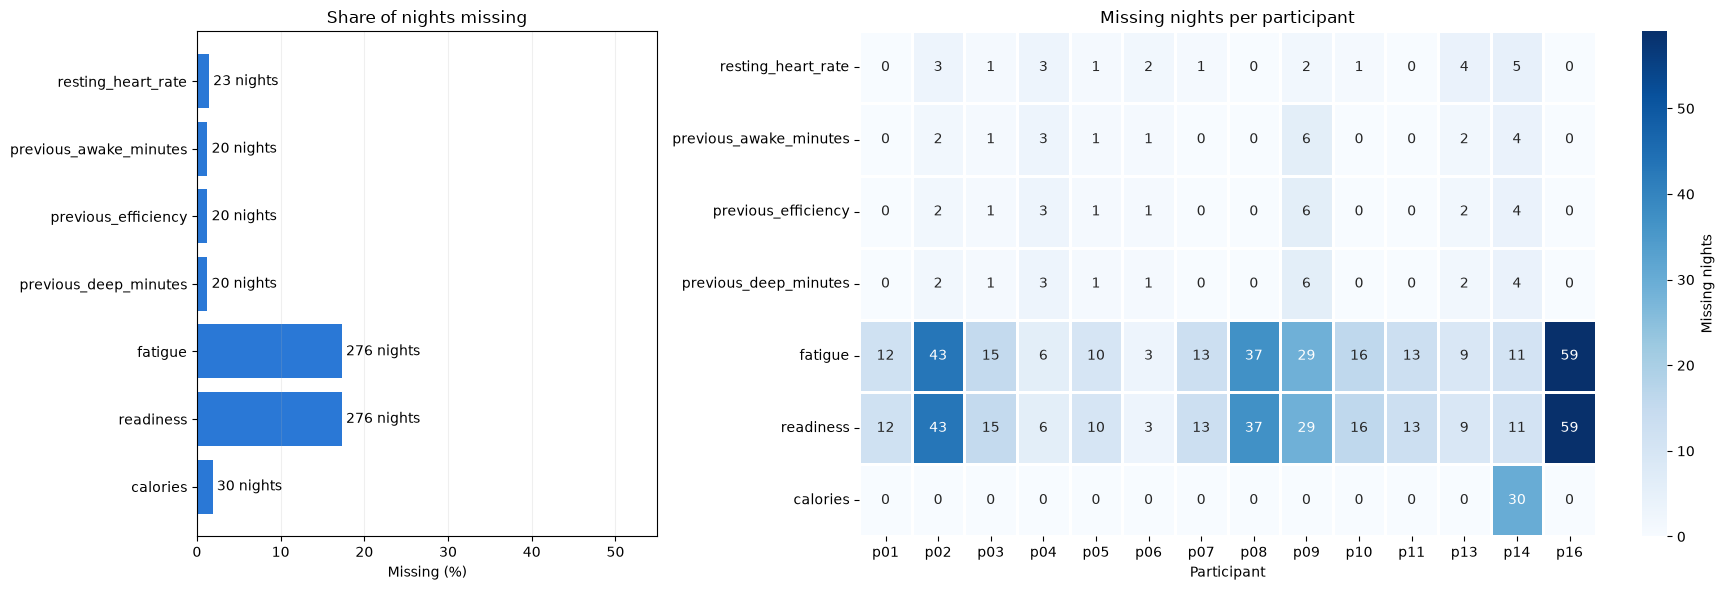

,Missing nights,Missing (%),Participants with gaps (nights)
resting_heart_rate,23,1.4,"p02 (3), p03 (1), p04 (3), p05 (1), p06 (2), p07 (1), p09 (2), p10 (1), p13 (4), p14 (5)"
previous_awake_minutes,20,1.3,"p02 (2), p03 (1), p04 (3), p05 (1), p06 (1), p09 (6), p13 (2), p14 (4)"
previous_efficiency,20,1.3,"p02 (2), p03 (1), p04 (3), p05 (1), p06 (1), p09 (6), p13 (2), p14 (4)"
previous_deep_minutes,20,1.3,"p02 (2), p03 (1), p04 (3), p05 (1), p06 (1), p09 (6), p13 (2), p14 (4)"
fatigue,276,17.3,"p01 (12), p02 (43), p03 (15), p04 (6), p05 (10), p06 (3), p07 (13), p08 (37), p09 (29), p10 (16), p11 (13), p13 (9), p14 (11), p16 (59)"
readiness,276,17.3,"p01 (12), p02 (43), p03 (15), p04 (6), p05 (10), p06 (3), p07 (13), p08 (37), p09 (29), p10 (16), p11 (13), p13 (9), p14 (11), p16 (59)"
calories,30,1.9,p14 (30)


In [14]:
features = [
    "avg_sleep_last_3_nights", "weekend_night", "weekday", "resting_heart_rate", "gender", "ab_type", "wake_up_hour",
    "previous_awake_minutes", "previous_efficiency", "previous_deep_minutes", "fatigue", "readiness", "calories",
]
gaps = candidates[features].isna()
gaps = gaps.loc[:, gaps.any()]

missing_summary = pd.DataFrame({
    "Missing nights": gaps.sum(),
    "Missing (%)": (gaps.mean() * 100).round(1),
    "Participants with gaps (nights)": [
        ", ".join(f"{person} ({n})" for person, n in gaps[column].groupby(candidates["participant_id"]).sum().items() if n)
        for column in gaps.columns
    ],
})
# Left: how much of each feature is missing. Right: whose nights the gaps belong to.
per_person = gaps.groupby(candidates["participant_id"]).sum().T
fig, (left, right) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 2]})
bars = left.barh(gaps.columns[::-1], gaps.mean()[::-1] * 100, color="#2a78d6")
left.bar_label(bars, labels=[f"{n} nights" for n in gaps.sum()[::-1]], padding=3)
left.set(title="Share of nights missing", xlabel="Missing (%)", xlim=(0, 55))
left.grid(axis="x", alpha=0.2)
sns.heatmap(per_person, annot=True, fmt="d", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Missing nights"}, ax=right)
right.set(title="Missing nights per participant", xlabel="Participant", ylabel="")
plt.tight_layout()
plt.show()

with pd.option_context("display.max_colwidth", None):
    display(missing_summary)

Fatigue and readiness have by far the most missing values, close to a fifth of all nights.

Perhaps looking at using a smaller model, maybe a KNN or linear regression, might bring me a way to predict or figure out what those values are. By looking at the heat map during the EDA part, most of the time those features relate to features from the same report. But things like past week average, last night's entry also do seem to have relatively high correlation. For both fatigue and readiness I use the participant's own average of that score over the past week, together with last night's sleep score and sleep efficiency. Yesterday's answer is left out, because when the report is missing it is often missing several days in a row.

### Fill fatigue and readiness
I fill the missing fatigue and readiness answers in two ways, so that feature selection can compare them on the sleep prediction itself:
- **Simple:** the participant's own average of all their earlier answers.
- **KNN:** per participant, the average answer on their 5 most similar training nights, where similar means a similar past-week average of that score, sleep score and sleep efficiency.

A yes/no column `report_missing` marks the nights that had no report, because those nights slept differently in the EDA.

In [15]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

# The number of similar nights KNN averages; change it to try other values (see the k comparison below).
K = 5


def fill_score(table, score, k=K):
    """Fill the gaps in one score per participant: their earlier average (simple) and their k most similar training nights (KNN)."""
    by_person = table.groupby("participant_id")
    training_average = table.loc[table["split"] == "train", score].mean()
    earlier = by_person[score].transform(lambda values: values.expanding().mean().shift(1)).fillna(training_average)
    past_week = pd.Series(by_person.rolling("7D", on="date", closed="left")[score].mean().to_numpy(), index=table.index)
    inputs = pd.DataFrame({"past_week": past_week.fillna(earlier),
                           "sleep_score": table["previous_sleep_score"], "efficiency": table["previous_efficiency"]})

    simple = table[score].fillna(earlier)
    knn_filled = simple.copy()
    for person, rows in table.groupby("participant_id"):
        x = inputs.loc[rows.index].fillna(inputs.loc[rows.index].mean())
        known = rows[score].notna() & rows["split"].eq("train")
        missing = rows[score].isna()
        if known.sum() >= k and missing.any():
            scaler = StandardScaler().fit(x[known])
            knn = KNeighborsRegressor(n_neighbors=k).fit(scaler.transform(x[known]), rows.loc[known, score])
            knn_filled[missing[missing].index] = knn.predict(scaler.transform(x[missing]))
    return simple, knn_filled


candidates = candidates.sort_values(["participant_id", "date"]).reset_index(drop=True)

Before filling the real gaps, I test both methods on answers we do know. Each participant's known answers on the training nights are split into 5 random groups, and each group is hidden in turn: it is filled with both methods while the other 80% stay visible. This way every known night gets one guess, and I measure how far each guess is from the real answer.

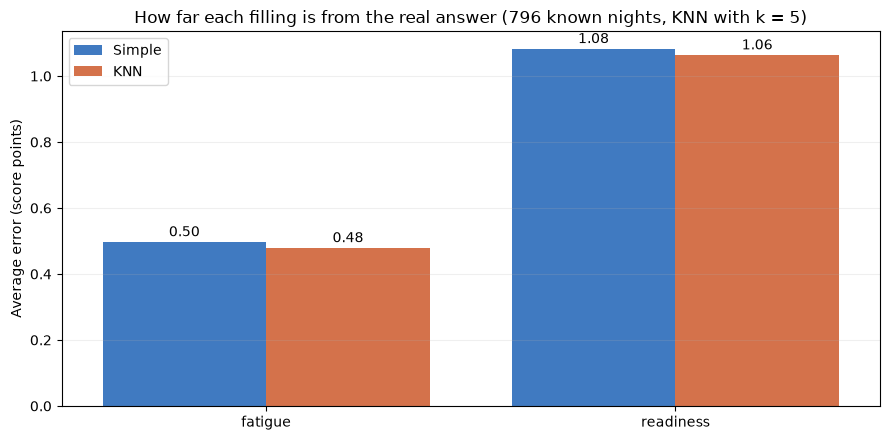

In [16]:
known_training = candidates.loc[candidates["split"].eq("train") & candidates["fatigue"].notna()]
# Split each participant's known nights into 5 random groups; every group is hidden once.
fold = known_training.groupby("participant_id")["date"].transform(
    lambda dates: np.random.default_rng(SEED).permutation(len(dates)) % 5
)


def hidden_guesses(score, k=K):
    """Hide each group of known nights in turn and keep both methods' guesses for the hidden nights."""
    simple_guess = pd.Series(np.nan, index=known_training.index)
    knn_guess = pd.Series(np.nan, index=known_training.index)
    for group in range(5):
        hidden = fold.index[fold == group]
        test_table = candidates.copy()
        test_table.loc[hidden, ["fatigue", "readiness"]] = np.nan
        simple, knn_filled = fill_score(test_table, score, k=k)
        simple_guess[hidden], knn_guess[hidden] = simple[hidden], knn_filled[hidden]
    return simple_guess, knn_guess


guesses = {score: hidden_guesses(score) for score in ["fatigue", "readiness"]}
check = pd.DataFrame([
    {"Score": score, "Method": method, "Average error": (guess - known_training[score]).abs().mean()}
    for score, (simple, knn_filled) in guesses.items() for method, guess in [("Simple", simple), ("KNN", knn_filled)]
])

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=check, x="Score", y="Average error", hue="Method", palette=["#2a78d6", "#eb6834"], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)
ax.set(title=f"How far each filling is from the real answer ({len(known_training)} known nights, KNN with k = {K})",
       xlabel="", ylabel="Average error (score points)")
ax.legend(title="", loc="upper left")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

To see how the two methods behave over a longer period, I follow their guesses over time on all known training nights, next to the real answers, for the four participants with the most known nights.

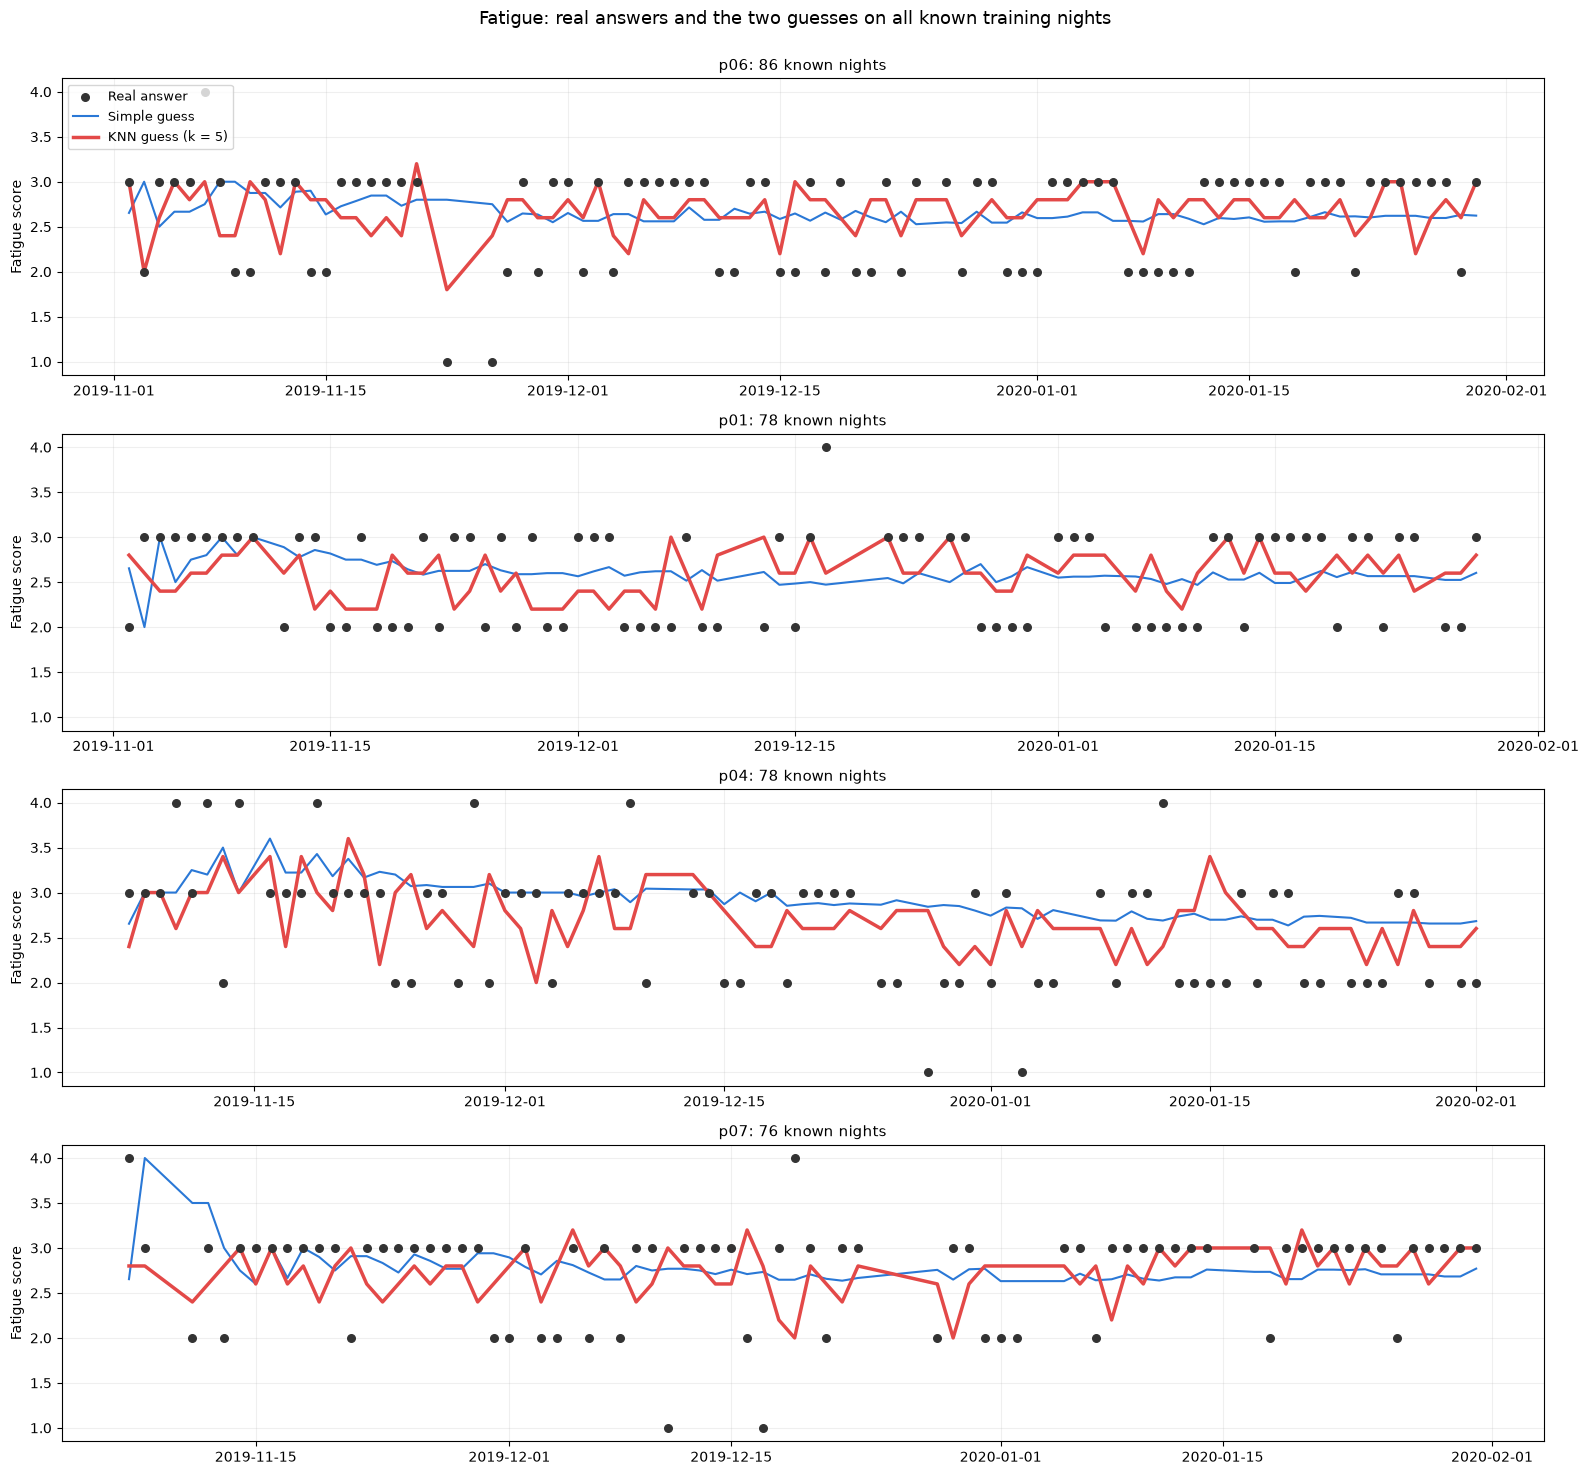

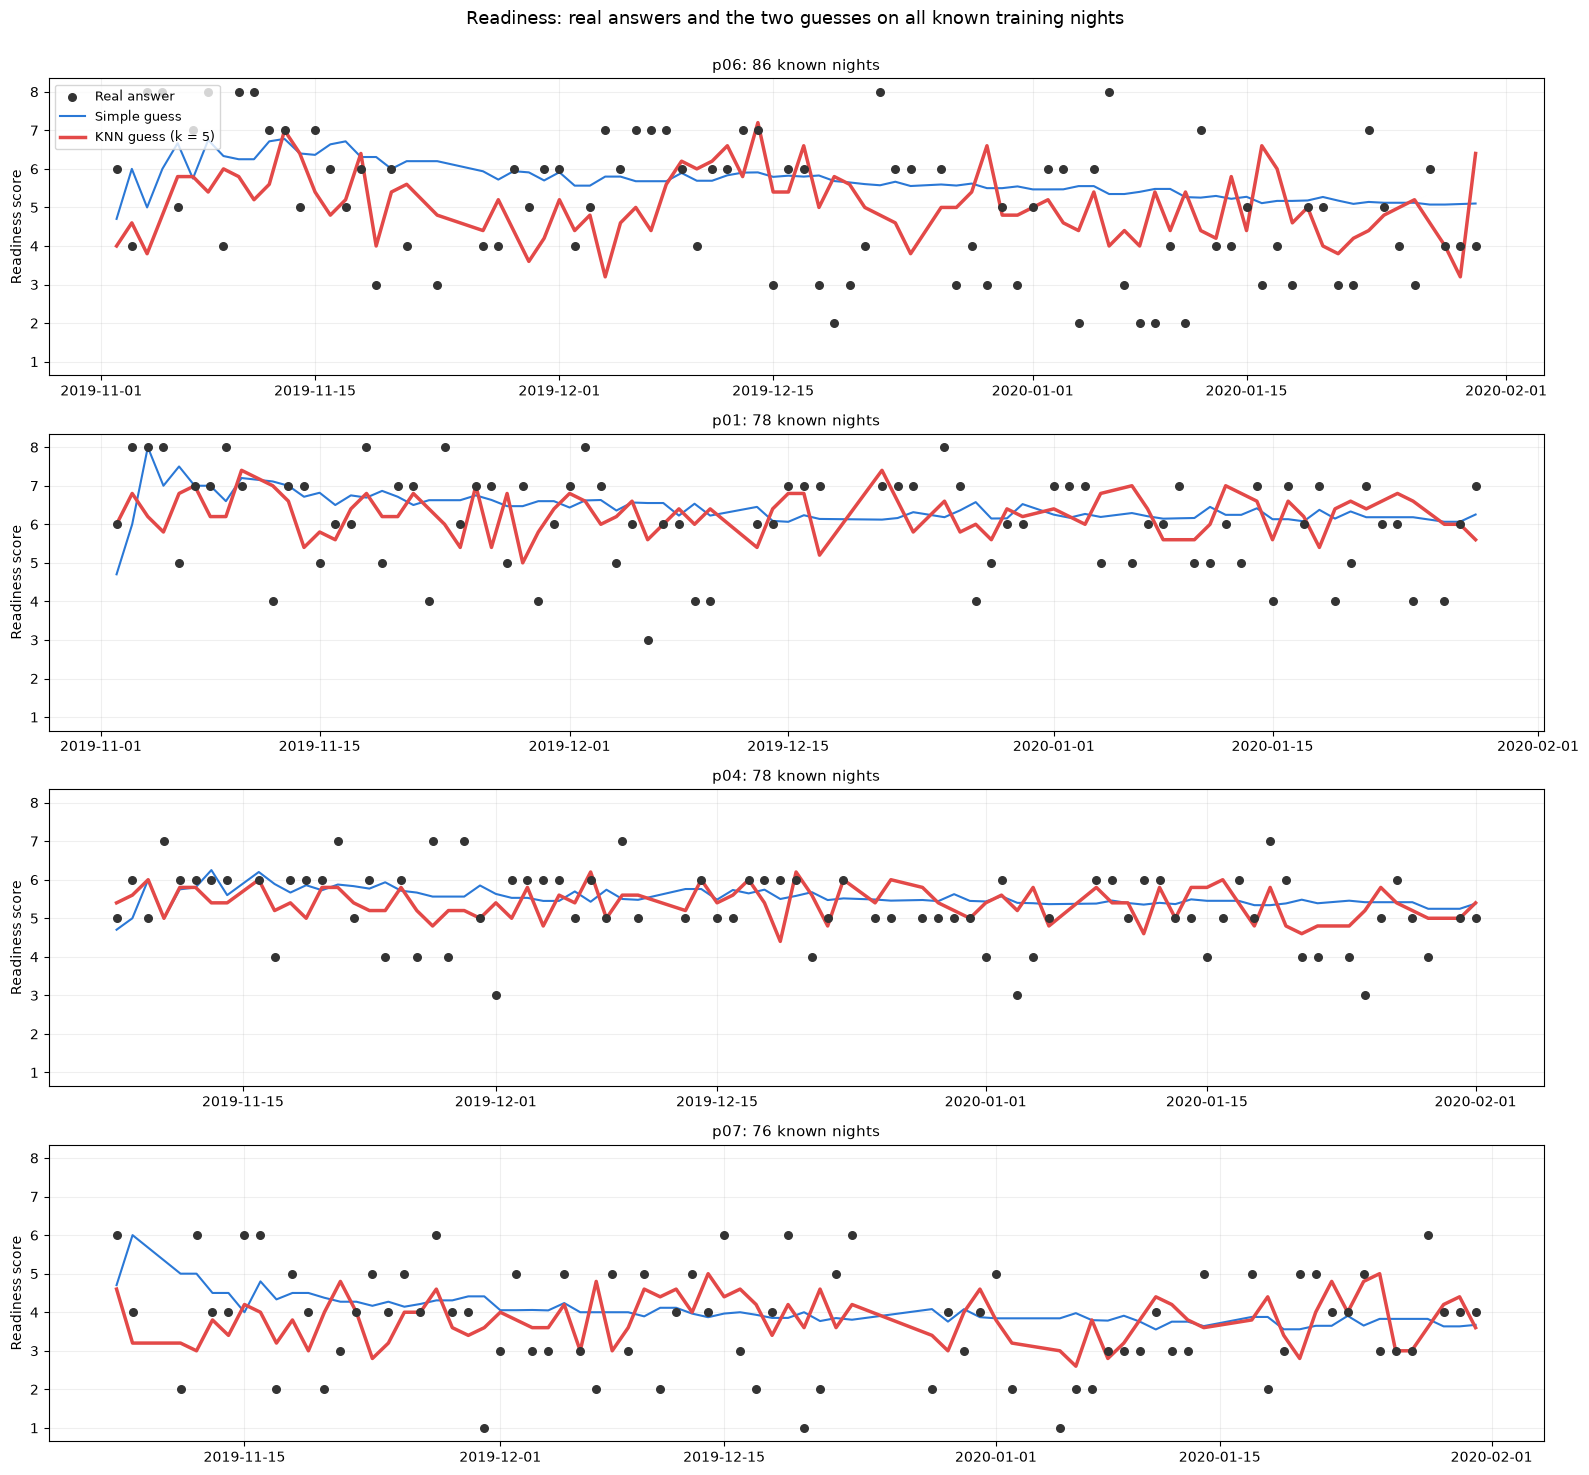

In [17]:
people = known_training["participant_id"].value_counts().index[:4]

for score in ["fatigue", "readiness"]:
    simple, knn_filled = guesses[score]
    fig, axes = plt.subplots(4, 1, figsize=(16, 15), sharey=True)
    for ax, person in zip(axes, people):
        nights_of_person = known_training.loc[known_training["participant_id"] == person].sort_values("date")
        ax.scatter(nights_of_person["date"], nights_of_person[score], s=30, color="#333333", zorder=3, label="Real answer")
        ax.plot(nights_of_person["date"], simple[nights_of_person.index], color="#2a78d6", linewidth=1.5, label="Simple guess")
        ax.plot(nights_of_person["date"], knn_filled[nights_of_person.index], color="#e34948", linewidth=2.5, label=f"KNN guess (k = {K})")
        ax.set_title(f"{person}: {len(nights_of_person)} known nights", fontsize=11)
        ax.set_ylabel(f"{score.capitalize()} score")
        ax.grid(alpha=0.2)
    axes[0].legend(loc="upper left", fontsize=9)
    fig.suptitle(f"{score.capitalize()}: real answers and the two guesses on all known training nights", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

KNN uses the 5 most similar nights, but that number (k) is a choice. I try several values of k with the same hiding in turns, so every known night is guessed once for each k, and compare their average error, with the simple method as a reference.

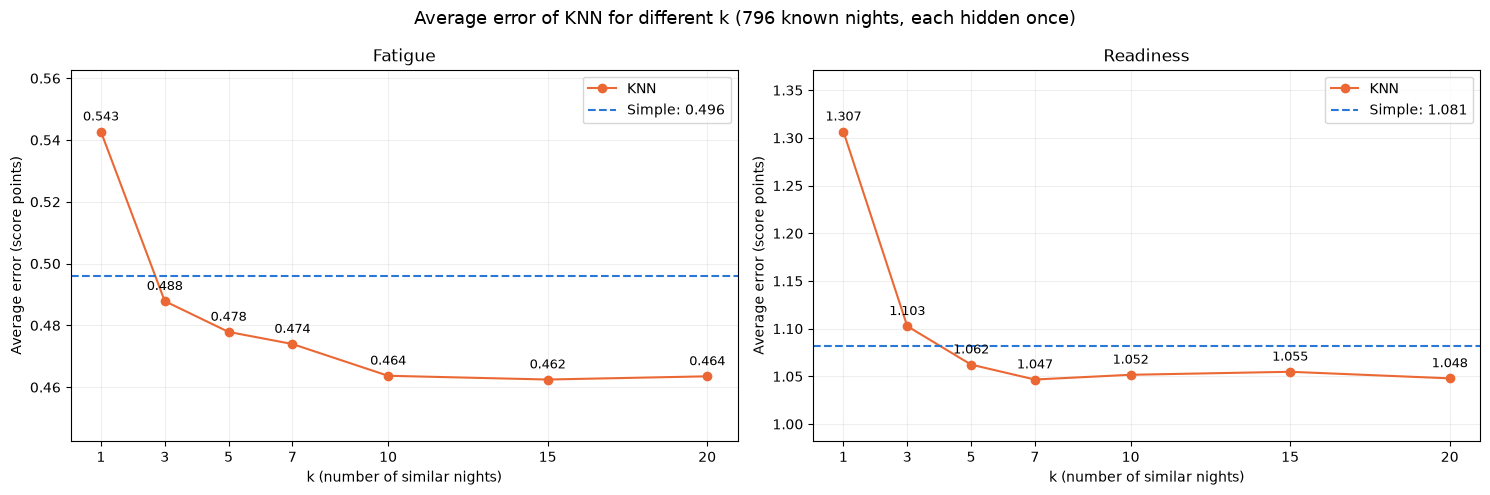

In [18]:
k_values = [1, 3, 5, 7, 10, 15, 20]
knn_by_k = {score: {k: hidden_guesses(score, k=k)[1] for k in k_values} for score in ["fatigue", "readiness"]}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, score in zip(axes, ["fatigue", "readiness"]):
    errors_by_k = pd.Series({k: (guess - known_training[score]).abs().mean() for k, guess in knn_by_k[score].items()})
    ax.plot(errors_by_k.index, errors_by_k.values, color="#eb6834", marker="o", label="KNN")
    for k, error in errors_by_k.items():
        ax.annotate(f"{error:.3f}", (k, error), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
    simple_error = (guesses[score][0] - known_training[score]).abs().mean()
    ax.axhline(simple_error, color="#2a78d6", linestyle="--", label=f"Simple: {simple_error:.3f}")
    ax.set(title=score.capitalize(), xlabel="k (number of similar nights)", ylabel="Average error (score points)")
    ax.set_xticks(k_values)
    ax.margins(y=0.25)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
fig.suptitle(f"Average error of KNN for different k ({len(known_training)} known nights, each hidden once)", fontsize=13)
plt.tight_layout()
plt.show()

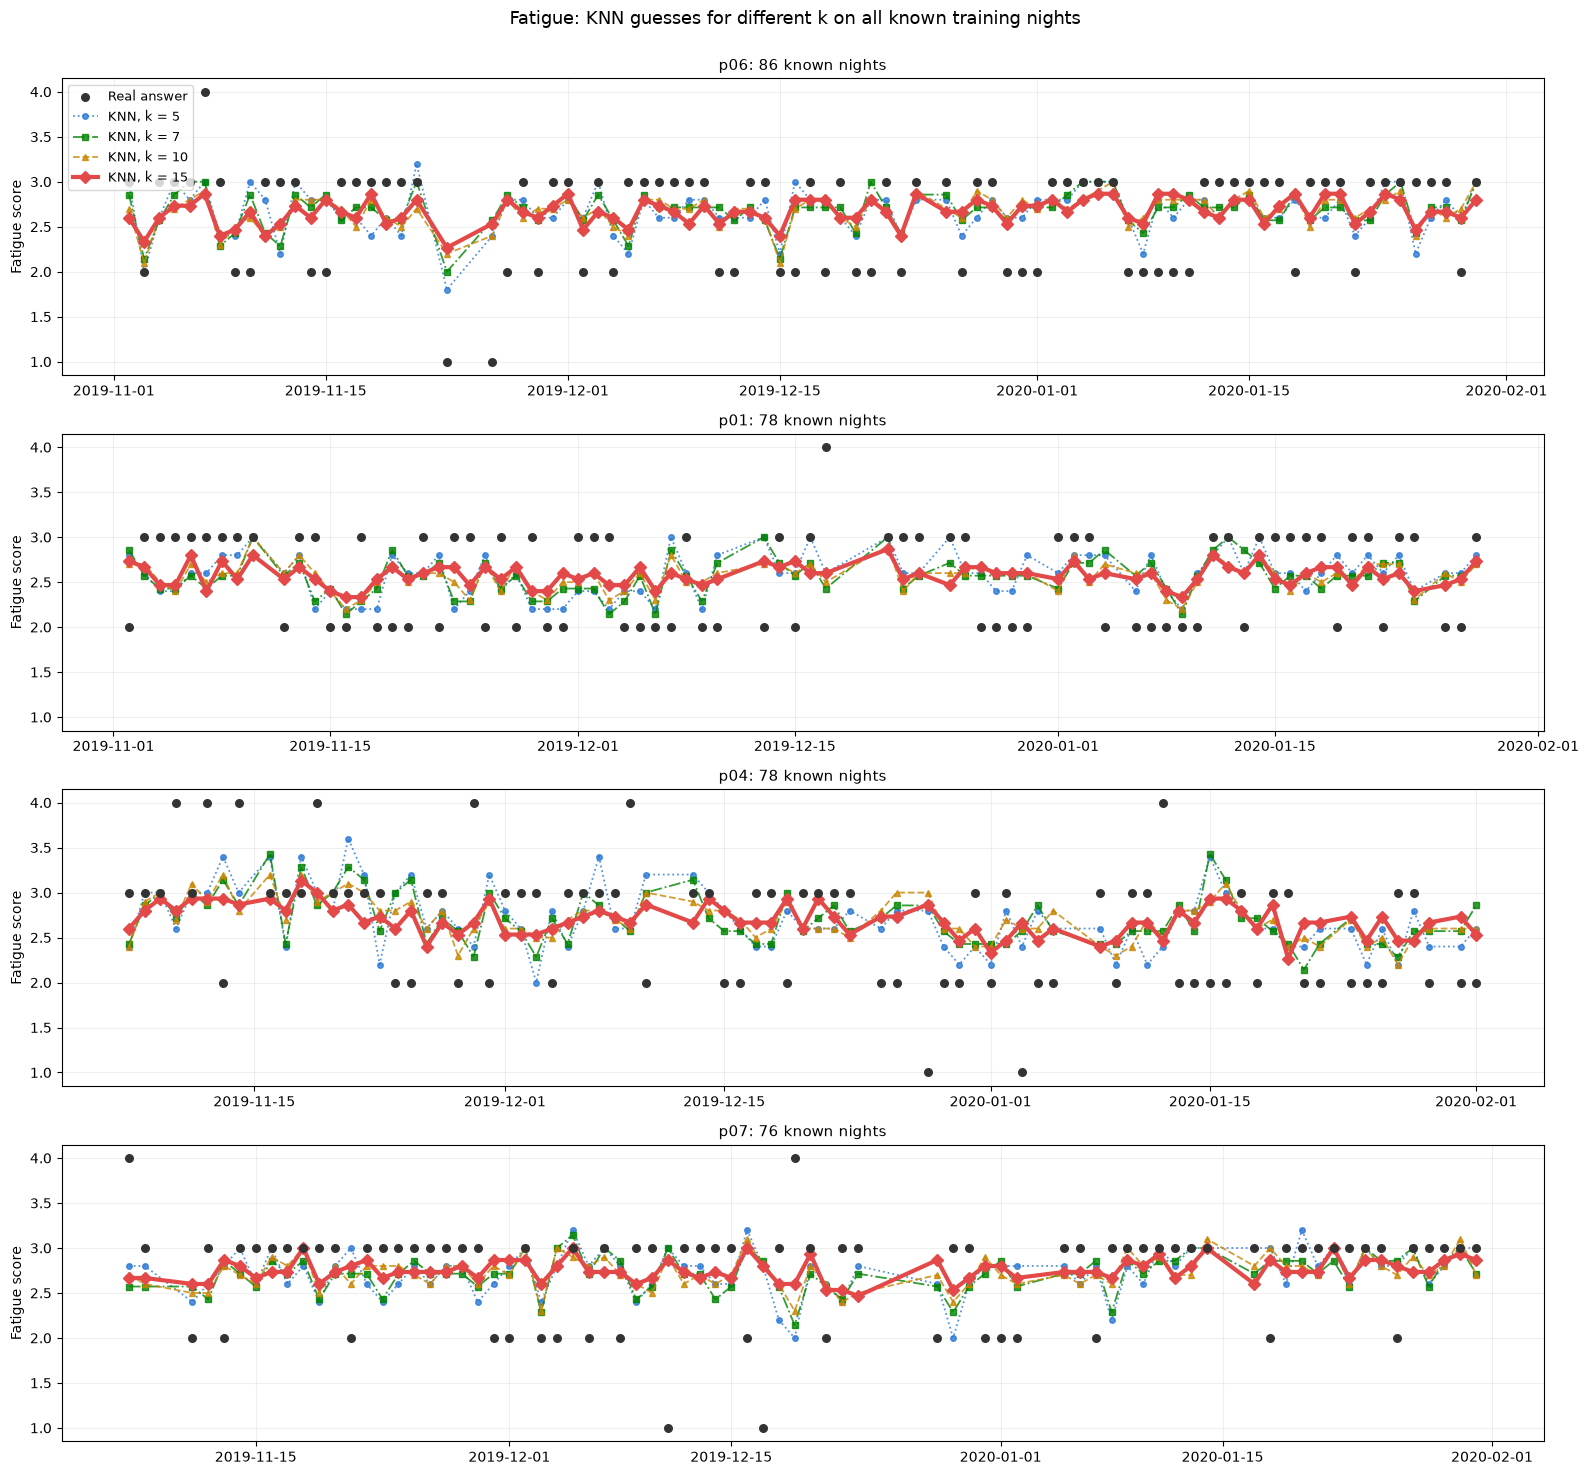

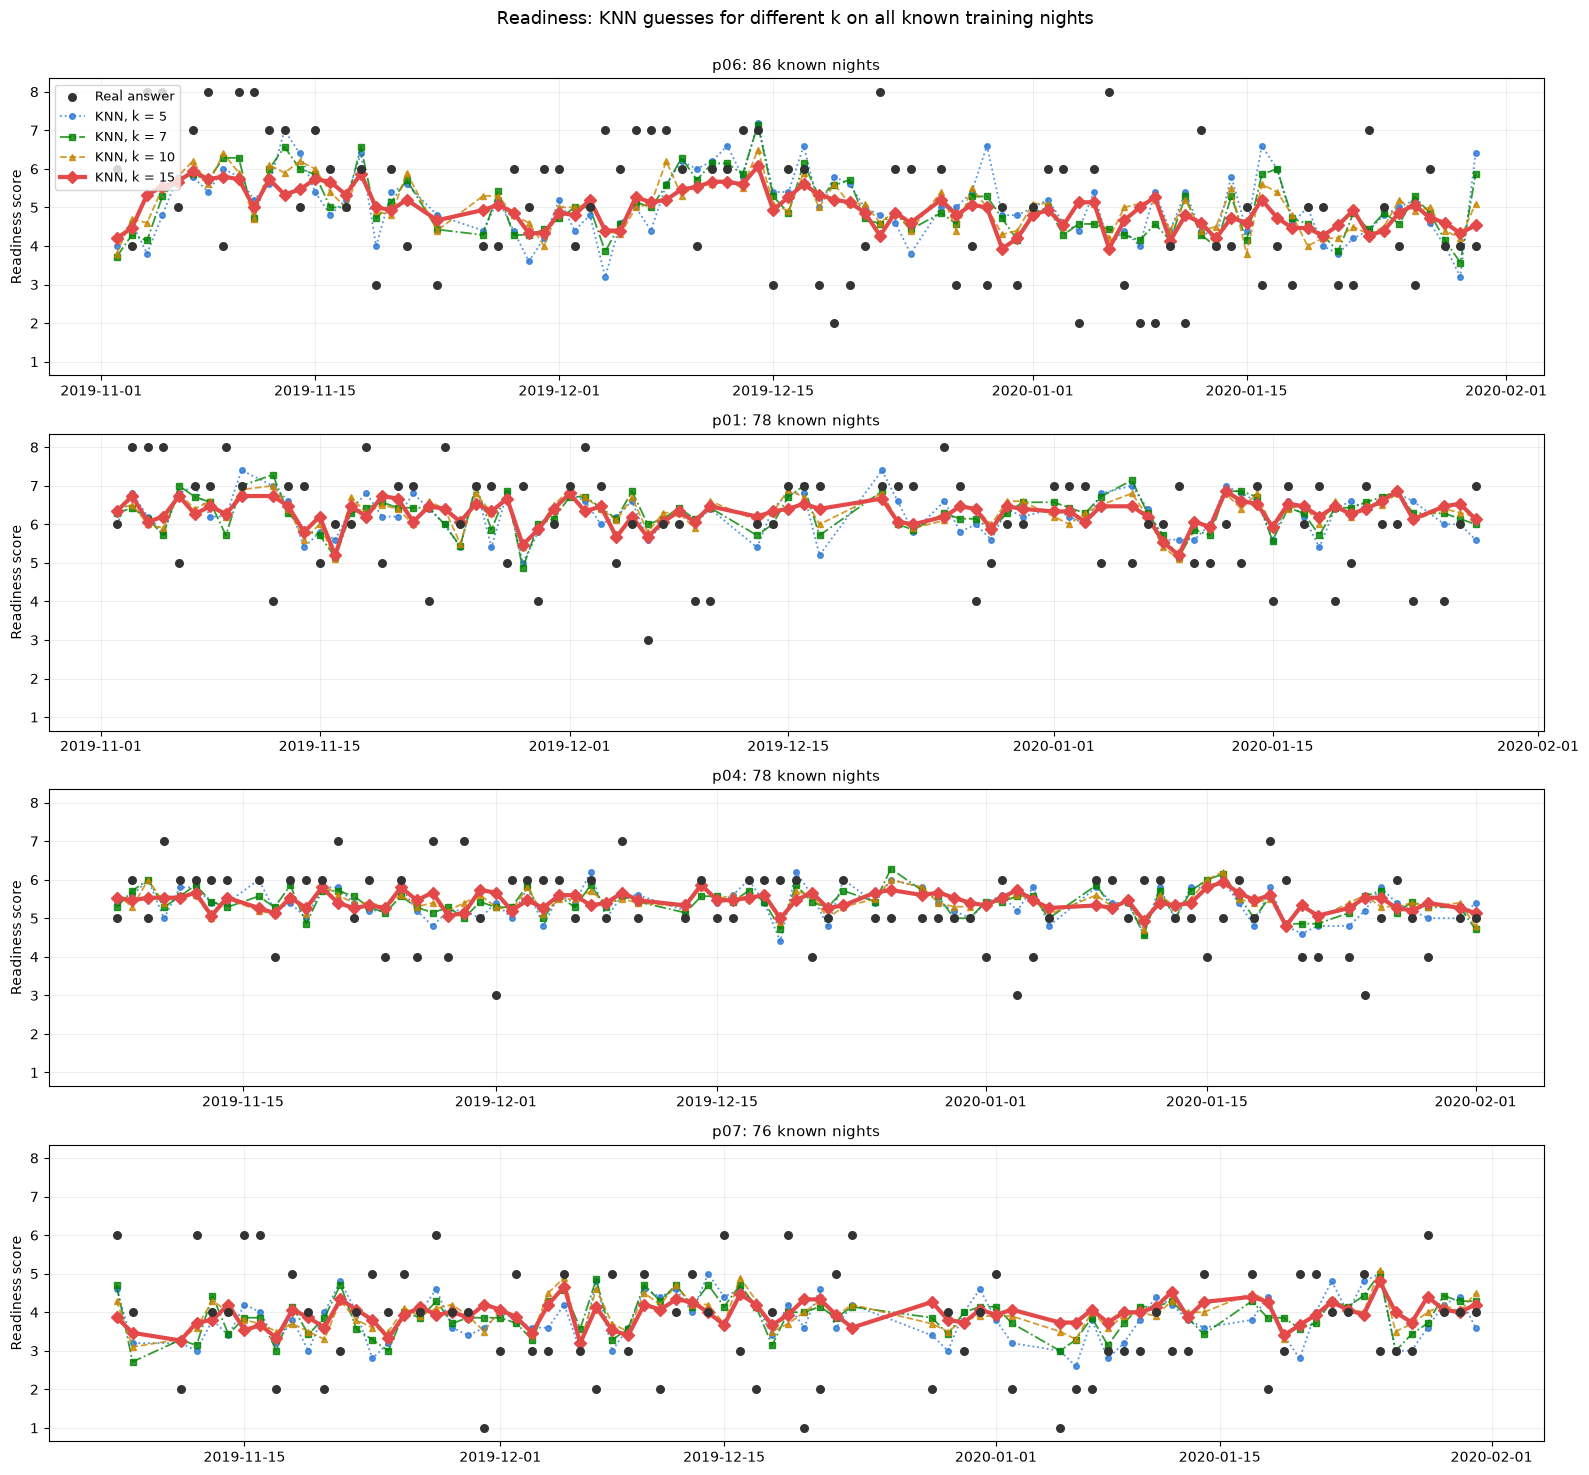

In [19]:
# Each k gets its own colour and line style; the best k from the comparison (15) is drawn thick and solid.
compared_k = {
    5: {"color": "#2a78d6", "linestyle": ":", "marker": "o", "linewidth": 1.3, "markersize": 4, "alpha": 0.8},
    7: {"color": "#008300", "linestyle": "-.", "marker": "s", "linewidth": 1.3, "markersize": 4, "alpha": 0.8},
    10: {"color": "#c98500", "linestyle": "--", "marker": "^", "linewidth": 1.3, "markersize": 4, "alpha": 0.8},
    15: {"color": "#e34948", "linestyle": "-", "marker": "D", "linewidth": 3, "markersize": 6, "alpha": 1},
}

for score in ["fatigue", "readiness"]:
    fig, axes = plt.subplots(4, 1, figsize=(16, 15), sharey=True)
    for ax, person in zip(axes, people):
        nights_of_person = known_training.loc[known_training["participant_id"] == person].sort_values("date")
        ax.scatter(nights_of_person["date"], nights_of_person[score], s=30, color="#333333", zorder=3, label="Real answer")
        for k, line_style in compared_k.items():
            ax.plot(nights_of_person["date"], knn_by_k[score][k][nights_of_person.index], label=f"KNN, k = {k}", **line_style)
        ax.set_title(f"{person}: {len(nights_of_person)} known nights", fontsize=11)
        ax.set_ylabel(f"{score.capitalize()} score")
        ax.grid(alpha=0.2)
    axes[0].legend(loc="upper left", fontsize=9)
    fig.suptitle(f"{score.capitalize()}: KNN guesses for different k on all known training nights", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

The best value seems to be a k value of 10. It doesn't seem to overfit, nor does it underfit, so it seems to be performing decently. It's not the best for either feature, but it seems to be the best balance out of both features.

Now the real gaps are filled with KNN (k = 10). A yes/no column `report_missing` marks the nights that had no report, because those nights slept on average 10 mins longer as shown in the EDA.

In [20]:
candidates["report_missing"] = candidates["fatigue"].isna().astype(int)
for score in ["fatigue", "readiness"]:
    candidates[f"{score}_simple"], candidates[f"{score}_knn"] = fill_score(candidates, score, k=10)

filled = candidates["report_missing"].eq(1)
pd.DataFrame({
    "Average where known": [candidates.loc[~filled, s].mean() for s in ["fatigue", "readiness"]],
    "Filled, simple": [candidates.loc[filled, f"{s}_simple"].mean() for s in ["fatigue", "readiness"]],
    "Filled, KNN": [candidates.loc[filled, f"{s}_knn"].mean() for s in ["fatigue", "readiness"]],
}, index=["fatigue", "readiness"]).round(2)

,Average where known,"Filled, simple","Filled, KNN"
fatigue,2.69,2.72,2.76
readiness,4.83,4.68,4.65


In [21]:
candidates.head()

,participant_id,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,...,resting_heart_rate,calories,gender,ab_type,split,report_missing,fatigue_simple,fatigue_knn,readiness_simple,readiness_knn
0,p01,2019-11-02,7.316667,0.150000,378,378.000000,11063.0,1,0,11,...,53.0,2541.18,male,A,train,0,2.0,2.0,6.0,6.0
1,p01,2019-11-03,7.566667,0.533333,378,378.000000,13045.0,0,0,0,...,52.0,2588.02,male,A,train,0,3.0,3.0,8.0,8.0
2,p01,2019-11-04,6.583333,-0.083333,361,372.333333,7373.0,0,0,0,...,53.0,2291.62,male,A,train,0,3.0,3.0,8.0,8.0
3,p01,2019-11-05,6.416667,0.366667,326,355.000000,9574.0,1,13,0,...,54.0,2495.25,male,A,train,0,3.0,3.0,8.0,8.0
4,p01,2019-11-06,6.483333,0.416667,341,342.666667,5189.0,0,0,0,...,52.0,1978.05,male,A,train,0,3.0,3.0,5.0,5.0


In [22]:
model_data = candidates[[
    "participant_id", "date", "split",
    "avg_sleep_last_3_nights", "previous_awake_minutes", "previous_efficiency", "previous_deep_minutes",
    "resting_heart_rate", "gender", "ab_type", "wake_up_hour", "weekend_night", "calories",
]].copy()
# The real answer where it is known, the KNN guess (k = 10) where the report is missing.
model_data["fatigue"] = candidates["fatigue_knn"]
model_data["readiness"] = candidates["readiness_knn"]
model_data["report_missing"] = candidates["report_missing"]
model_data["weekday_number"] = model_data["date"].dt.dayofweek
model_data["next_sleep_minutes"] = candidates["next_sleep_minutes"]
model_data.head()

,participant_id,date,split,avg_sleep_last_3_nights,previous_awake_minutes,previous_efficiency,previous_deep_minutes,resting_heart_rate,gender,ab_type,wake_up_hour,weekend_night,calories,fatigue,readiness,report_missing,weekday_number,next_sleep_minutes
0,p01,2019-11-02,train,378.000000,52.0,97.0,36.0,53.0,male,A,7.316667,1,2541.18,2.0,6.0,0,5,378.0
1,p01,2019-11-03,train,378.000000,44.0,96.0,38.0,52.0,male,A,7.566667,0,2588.02,3.0,8.0,0,6,361.0
2,p01,2019-11-04,train,372.333333,38.0,96.0,37.0,53.0,male,A,6.583333,0,2291.62,3.0,8.0,0,0,326.0
3,p01,2019-11-05,train,355.000000,36.0,99.0,27.0,54.0,male,A,6.416667,0,2495.25,3.0,8.0,0,1,341.0
4,p01,2019-11-06,train,342.666667,23.0,99.0,66.0,52.0,male,A,6.483333,0,1978.05,3.0,5.0,0,2,312.0


Before filling them, I check whether these small gaps fall on the same nights.

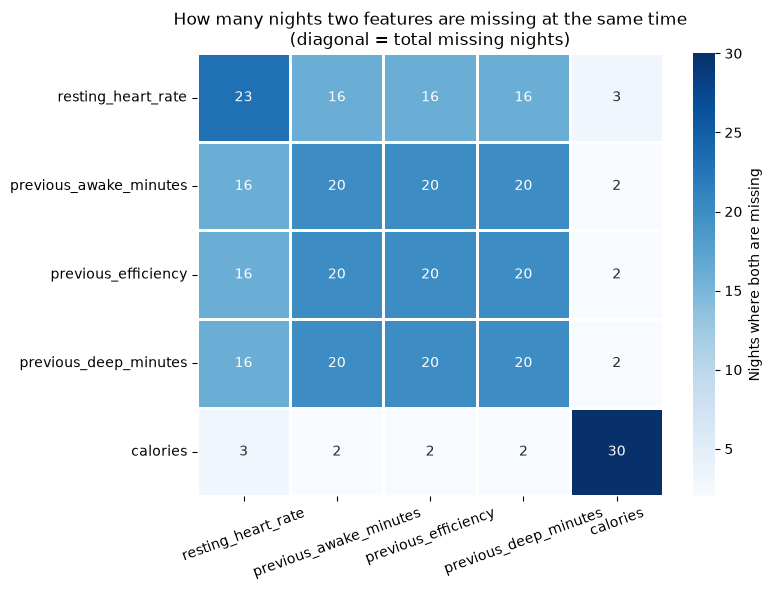

In [23]:
small_gaps = ["resting_heart_rate", "previous_awake_minutes", "previous_efficiency", "previous_deep_minutes", "calories"]
gap_nights = model_data[small_gaps].isna().astype(int)
# Nights where both the row and the column are missing; the diagonal is each feature's total.
both_missing = gap_nights.T @ gap_nights

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(both_missing, annot=True, fmt="d", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Nights where both are missing"}, ax=ax)
ax.set(title="How many nights two features are missing at the same time\n(diagonal = total missing nights)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

### Fill the small Fitbit gaps
Those features are only missing on 1–2% of the nights, and mostly overlap eachother so the way they are filled would barely make any difference. I will fill them with the participant's own average of their earlier nights, as planned in the EDA. A participant's first nights, before any earlier value exists, get that participant's average over their training nights.

In [24]:
small_gaps = ["resting_heart_rate", "previous_awake_minutes", "previous_efficiency", "previous_deep_minutes", "calories"]
missing_before = model_data[small_gaps].isna().sum()

for column in small_gaps:
    by_person = model_data.groupby("participant_id")[column]
    earlier = by_person.transform(lambda values: values.expanding().mean().shift(1))
    training_average = model_data[column].where(model_data["split"].eq("train")).groupby(model_data["participant_id"]).transform("mean")
    model_data[column] = model_data[column].fillna(earlier).fillna(training_average)

pd.DataFrame({"Missing before": missing_before, "Missing after": model_data[small_gaps].isna().sum()})

,Missing before,Missing after
resting_heart_rate,23,0
previous_awake_minutes,20,0
previous_efficiency,20,0
previous_deep_minutes,20,0
calories,30,0


### Encode gender and A/B person
The models need numbers, and both have only two options, so each becomes one yes/no column: `is_female` (1 = female) and `is_evening_type` (1 = B, the evening type). How to encode the weekday is decided separately.

In [25]:
model_data["is_female"] = model_data["gender"].str.lower().eq("female").astype(int)
model_data["is_evening_type"] = model_data["ab_type"].eq("B").astype(int)
model_data = model_data.drop(columns=["gender", "ab_type"])

model_data.head(10)

,participant_id,date,split,avg_sleep_last_3_nights,previous_awake_minutes,previous_efficiency,previous_deep_minutes,resting_heart_rate,wake_up_hour,weekend_night,calories,fatigue,readiness,report_missing,weekday_number,next_sleep_minutes,is_female,is_evening_type
0,p01,2019-11-02,train,378.000000,52.0,97.0,36.0,53.0,7.316667,1,2541.18,2.0,6.0,0,5,378.0,0,0
1,p01,2019-11-03,train,378.000000,44.0,96.0,38.0,52.0,7.566667,0,2588.02,3.0,8.0,0,6,361.0,0,0
2,p01,2019-11-04,train,372.333333,38.0,96.0,37.0,53.0,6.583333,0,2291.62,3.0,8.0,0,0,326.0,0,0
3,p01,2019-11-05,train,355.000000,36.0,99.0,27.0,54.0,6.416667,0,2495.25,3.0,8.0,0,1,341.0,0,0
4,p01,2019-11-06,train,342.666667,23.0,99.0,66.0,52.0,6.483333,0,1978.05,3.0,5.0,0,2,312.0,0,0
5,p01,2019-11-07,train,326.333333,54.0,97.0,44.0,54.0,5.866667,0,2106.78,3.0,7.0,0,3,360.0,0,0
6,p01,2019-11-08,train,337.666667,32.0,100.0,34.0,53.0,6.350000,1,2555.53,3.0,7.0,0,4,344.0,0,0
7,p01,2019-11-09,train,338.666667,47.0,99.0,36.0,53.0,7.033333,1,2905.42,3.0,8.0,0,5,382.0,0,0
8,p01,2019-11-10,train,362.000000,40.0,99.0,52.0,53.0,7.300000,0,2956.74,3.0,7.0,0,6,318.0,0,0
9,p01,2019-11-11,train,348.000000,38.0,97.0,38.0,52.0,6.083333,0,2344.66,2.5,6.3,1,0,378.0,0,0


Next I wish to test and find out which weekday encoding might be best. I will try:
- **No weekday at all**, as a reference.
- **Numerical:** Monday = 0 … Sunday = 6.
- **Weekend yes/no:** Friday or Saturday night.
- **One-hot:** one yes/no column per day.
- **Cyclical:** the sine and cosine of the day, so Sunday sits next to Monday.

The same random forest is trained on the training nights for each version and compared on the validation nights.

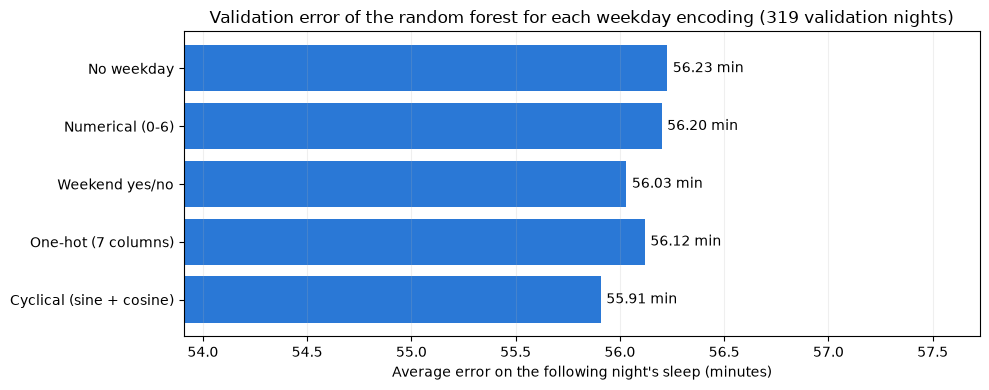

In [26]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Every version uses the same features; only the weekday columns change.
base_features = [
    "avg_sleep_last_3_nights", "previous_awake_minutes", "previous_efficiency", "previous_deep_minutes",
    "resting_heart_rate", "is_female", "is_evening_type", "wake_up_hour",
    "fatigue", "readiness", "report_missing", "calories",
]
day = model_data["weekday_number"]
weekday_versions = {
    "No weekday": pd.DataFrame(index=model_data.index),
    "Numerical (0-6)": model_data[["weekday_number"]],
    "Weekend yes/no": model_data[["weekend_night"]],
    "One-hot (7 columns)": pd.get_dummies(day, prefix="day").astype(int),
    "Cyclical (sine + cosine)": pd.DataFrame({"day_sin": np.sin(2 * np.pi * day / 7), "day_cos": np.cos(2 * np.pi * day / 7)}),
}
train = model_data["split"].eq("train")
validation = model_data["split"].eq("validation")
target = model_data["next_sleep_minutes"]

weekday_errors, weekday_predictions, weekday_forests = {}, {}, {}
for name, weekday_columns in weekday_versions.items():
    inputs = pd.concat([model_data[base_features], weekday_columns], axis=1)
    # The limited random forest from the first notebook.
    forest = RandomForestRegressor(n_estimators=30, min_samples_leaf=40, random_state=SEED, n_jobs=-1)
    forest.fit(inputs[train], target[train])
    weekday_forests[name] = forest
    weekday_predictions[name] = forest.predict(inputs[validation])
    weekday_errors[name] = mean_absolute_error(target[validation], weekday_predictions[name])
weekday_errors = pd.Series(weekday_errors)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(weekday_errors.index[::-1], weekday_errors.values[::-1], color="#2a78d6")
ax.bar_label(bars, fmt="%.2f min", padding=4)
# The axis does not start at 0, so the differences between the versions are visible.
ax.set_xlim(weekday_errors.min() - 2, weekday_errors.max() + 1.5)
ax.set(title=f"Validation error of the random forest for each weekday encoding ({validation.sum()} validation nights)",
       xlabel="Average error on the following night's sleep (minutes)")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import r2_score


def scores(predictions, nights=validation):
    """MAE, RMSE, R² and the share of nights within 30 and 60 minutes, per version (validation nights unless told otherwise)."""
    real = target[nights].to_numpy()
    rows = {}
    for name, predicted in predictions.items():
        miss = np.abs(real - predicted)
        rows[name] = {
            "MAE (min)": miss.mean(),
            "RMSE (min)": np.sqrt((miss ** 2).mean()),
            "R²": r2_score(real, predicted),
            "Within 30 min (%)": (miss <= 30).mean() * 100,
            "Within 60 min (%)": (miss <= 60).mean() * 100,
        }
    return pd.DataFrame(rows).T


weekday_scores = scores(weekday_predictions)
display(weekday_scores.round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
No weekday,56.227,75.371,0.060,36.677,63.009
Numerical (0-6),56.200,75.247,0.063,36.364,63.009
Weekend yes/no,56.031,75.144,0.066,36.050,62.696
One-hot (7 columns),56.119,75.284,0.062,36.991,63.009
Cyclical (sine + cosine),55.908,74.849,0.073,35.737,64.263


Cyclical (sine + cosine) has the lowest error, though all versions are very close to each other. Next, I want to see the error per weekday: does any version pick up the Friday spike and the start-of-week dip from the EDA?

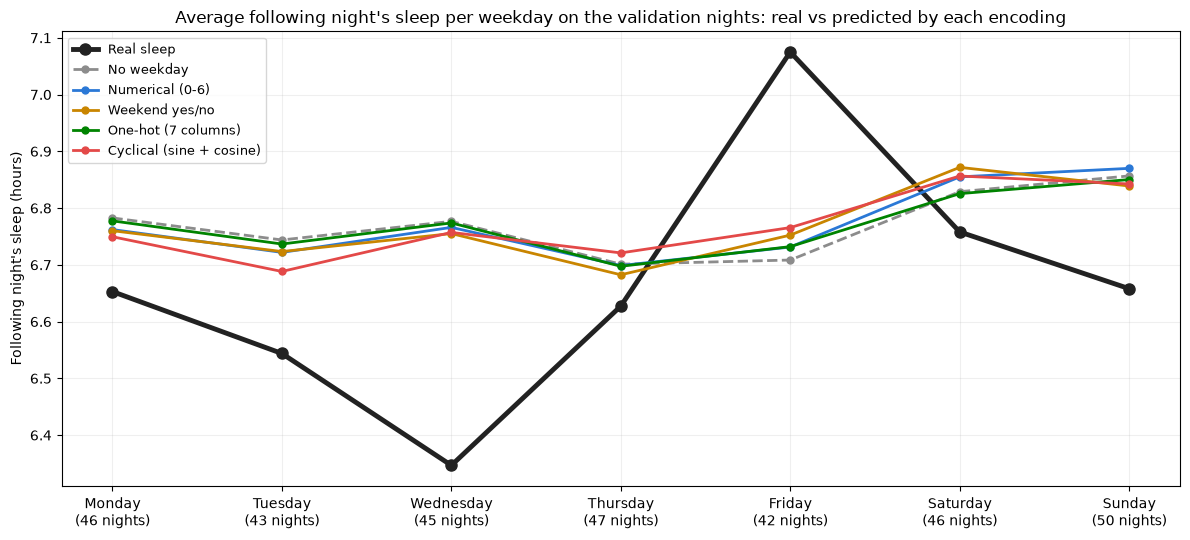

In [28]:
# Average real sleep and average prediction per weekday, on the validation nights.
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
validation_days = day[validation].to_numpy()
pattern = pd.DataFrame({"Real sleep": target[validation].to_numpy()} | weekday_predictions)
pattern = pattern.groupby(validation_days).mean() / 60
pattern.index = weekday_names

styles = {
    "No weekday": {"color": "#8c8c8c", "linestyle": "--"},
    "Numerical (0-6)": {"color": "#2a78d6"},
    "Weekend yes/no": {"color": "#c98500"},
    "One-hot (7 columns)": {"color": "#008300"},
    "Cyclical (sine + cosine)": {"color": "#e34948"},
}
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(pattern.index, pattern["Real sleep"], color="#222222", linewidth=3.5, marker="o", markersize=8, label="Real sleep")
for name, style in styles.items():
    ax.plot(pattern.index, pattern[name], linewidth=2, marker="o", markersize=5, label=name, **style)
nights_per_day = pd.Series(validation_days).value_counts().sort_index()
ax.set_xticks(range(7), [f"{name}\n({n} nights)" for name, n in zip(weekday_names, nights_per_day)])
ax.set(title="Average following night's sleep per weekday on the validation nights: real vs predicted by each encoding",
       ylabel="Following night's sleep (hours)")
ax.grid(alpha=0.2)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

All the models seem to ignore the weekly pattern: their predictions barely change from day to day. The real Wednesday nights have a big dip, which I need to look into. With only about 45 validation nights per weekday, an average can easily move 10–15 minutes by chance, and the EDA did not show a Wednesday dip, so it is most likely chance in these particular nights. Next, I want to see which features actually drive the predictions.

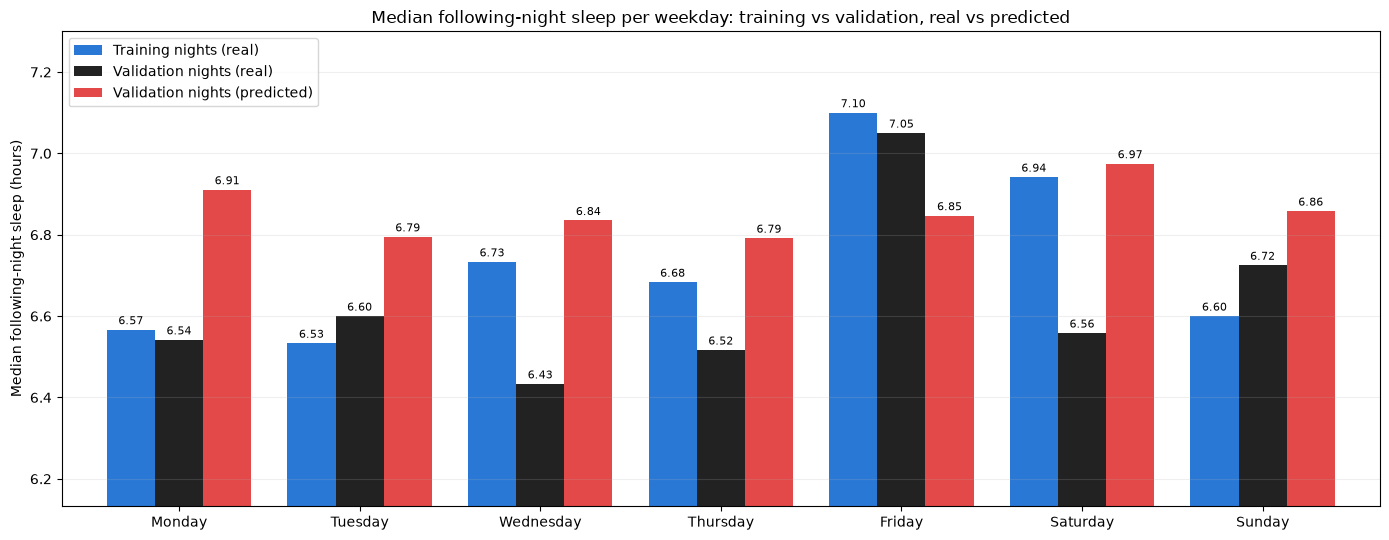

In [29]:
# Median following-night sleep per weekday: what the model trained on, what really happened
# on the validation nights, and what the model (cyclical weekday) guessed for them.
weekday_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
    "Validation nights (predicted)": pd.Series(weekday_predictions["Cyclical (sine + cosine)"]).groupby(validation_days).median(),
}) / 60
weekday_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
weekday_medians.plot.bar(color=["#2a78d6", "#222222", "#e34948"], width=0.8, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(weekday_medians.min().min() - 0.3, weekday_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: training vs validation, real vs predicted",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left")
plt.tight_layout()
plt.show()

As expected, the validation nights differ from the training nights: Wednesday, Thursday and Saturday are shorter, while Sunday is slightly longer. The model predicts too much sleep on most days and misses the Friday spike. Next, I want to see which features drive these predictions.

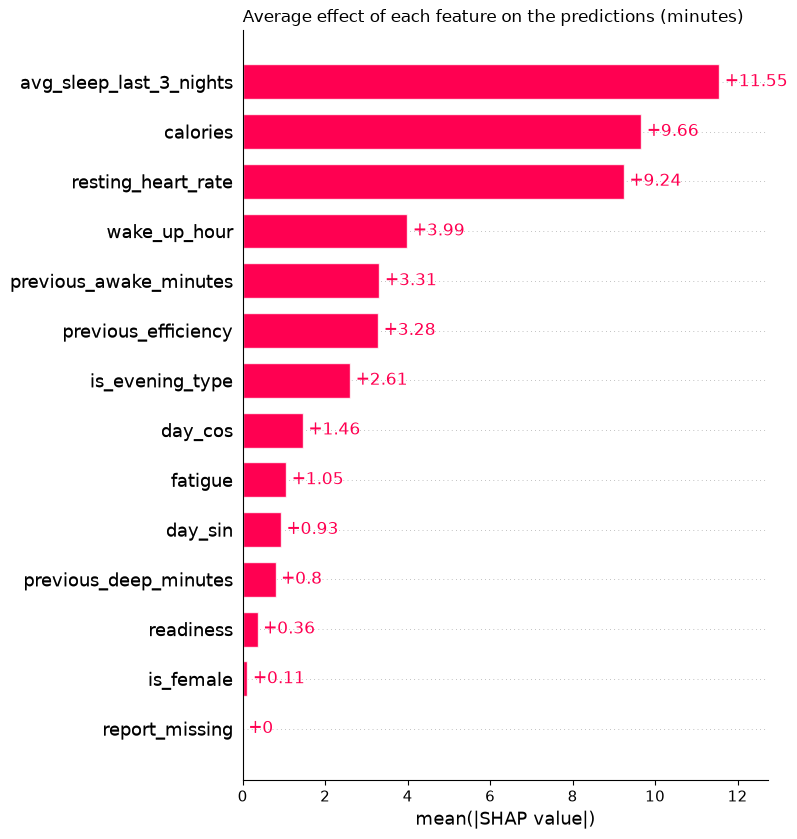

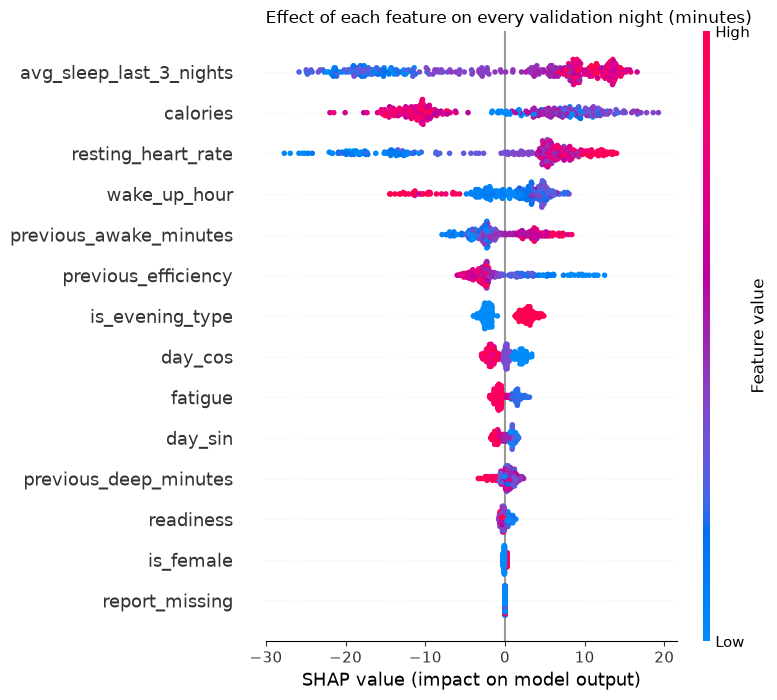

In [30]:
import shap

# The cyclical forest already trained in the weekday test (all chosen features), so nothing is trained again.
shap_inputs = pd.concat([model_data[base_features], weekday_versions["Cyclical (sine + cosine)"]], axis=1)
shap_forest = weekday_forests["Cyclical (sine + cosine)"]

# How much each feature pushes each validation prediction up or down, in minutes of sleep.
explainer = shap.TreeExplainer(shap_forest)
shap_values = explainer(shap_inputs[validation])

shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

Just like before, the three-night average affects the predictions the most: a higher average raises the predicted sleep. Calories and resting heart rate come next: more calories go with less predicted sleep, and a higher resting heart rate with more. Wake-up time, last night's details and the A/B type play a smaller role, and the weekday (sine and cosine together) only a small one. Gender barely matters and `report_missing` not at all, so they may be adding noise instead of information.

I also want to see how this changes for the different weekday encodings, to check whether the weekday gets more weight in any of them.

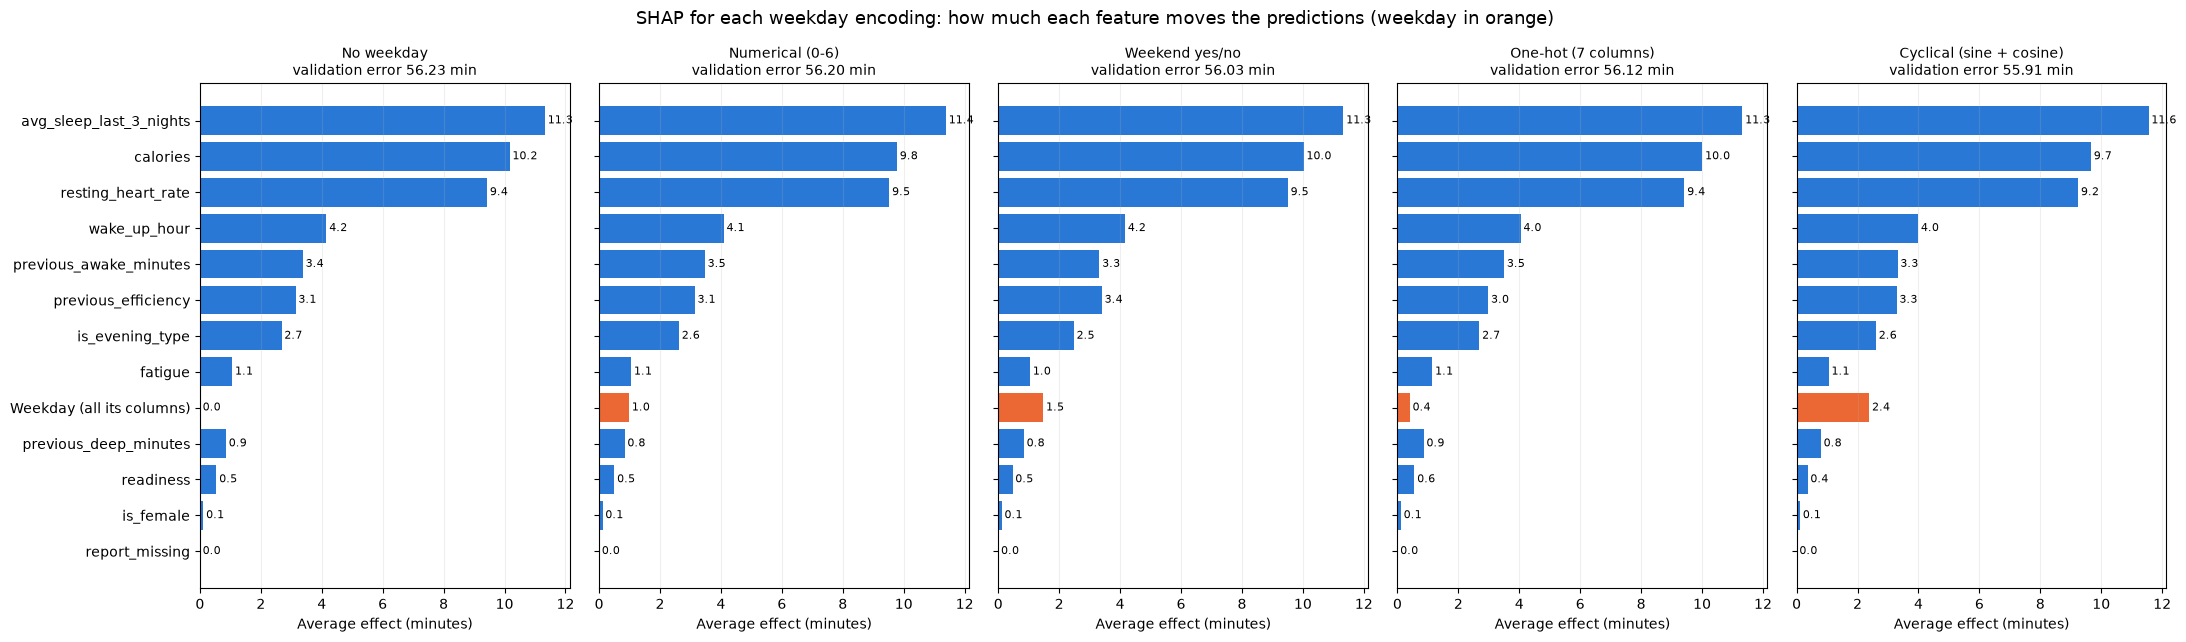

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
No weekday,56.227,75.371,0.060,36.677,63.009
Numerical (0-6),56.200,75.247,0.063,36.364,63.009
Weekend yes/no,56.031,75.144,0.066,36.050,62.696
One-hot (7 columns),56.119,75.284,0.062,36.991,63.009
Cyclical (sine + cosine),55.908,74.849,0.073,35.737,64.263


In [31]:
# SHAP for every weekday version: the average effect of each feature, with all weekday columns added up into one bar.
shap_by_version = {}
for name, weekday_columns in weekday_versions.items():
    # The forests already trained in the weekday test, so nothing is trained again.
    inputs = pd.concat([model_data[base_features], weekday_columns], axis=1)
    forest = weekday_forests[name]
    effect = pd.Series(np.abs(shap.TreeExplainer(forest)(inputs[validation]).values).mean(axis=0), index=inputs.columns)
    shap_by_version[name] = pd.concat([effect[base_features], pd.Series({"Weekday (all its columns)": effect[weekday_columns.columns].sum()})])
shap_by_version = pd.DataFrame(shap_by_version)
order = shap_by_version.mean(axis=1).sort_values().index

fig, axes = plt.subplots(1, len(shap_by_version.columns), figsize=(22, 6.5), sharey=True, sharex=True)
for ax, name in zip(axes, shap_by_version.columns):
    values = shap_by_version.loc[order, name]
    colors = ["#eb6834" if feature == "Weekday (all its columns)" else "#2a78d6" for feature in order]
    bars = ax.barh(order, values, color=colors)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    ax.set_title(f"{name}\nvalidation error {weekday_errors[name]:.2f} min", fontsize=10)
    ax.set_xlabel("Average effect (minutes)")
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("SHAP for each weekday encoding: how much each feature moves the predictions (weekday in orange)", fontsize=13)
plt.tight_layout()
plt.show()
display(weekday_scores.round(3))

The weekday gets the most weight in the cyclical version. Cyclical also has the lowest MAE, the highest R² and the most nights within 60 minutes, so it is the one I keep. Next: how many trees and what leaf size the forest should use.

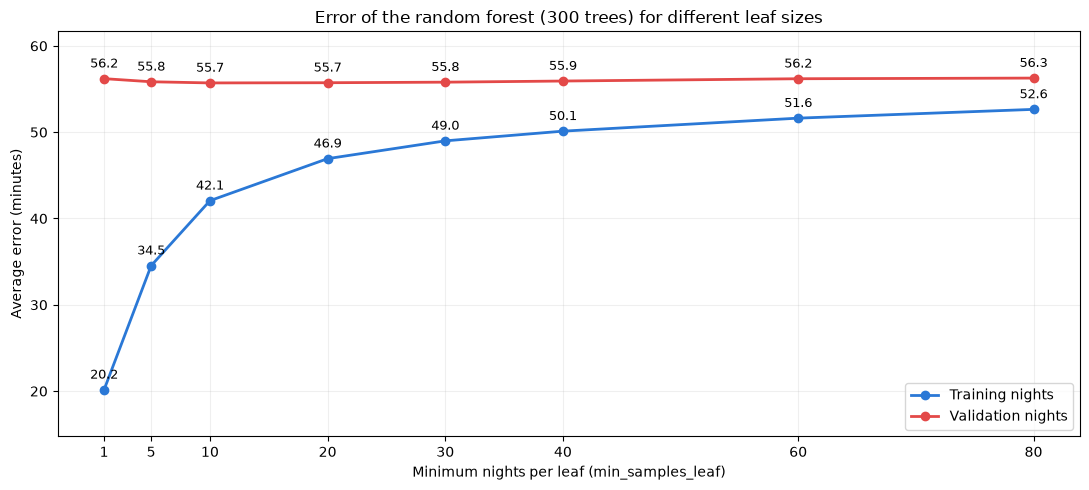

In [32]:
# Leaf size: how many nights every leaf must hold. Smaller = more flexible, larger = more careful.
# The number of trees is kept at 300 here, so only the leaf size changes.
leaf_inputs = pd.concat([model_data[base_features], weekday_versions["Cyclical (sine + cosine)"]], axis=1)
leaf_sizes = [1, 5, 10, 20, 30, 40, 60, 80]
leaf_errors = []
for leaf in leaf_sizes:
    forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1)
    forest.fit(leaf_inputs[train], target[train])
    leaf_errors.append({
        "leaf": leaf,
        "Training nights": mean_absolute_error(target[train], forest.predict(leaf_inputs[train])),
        "Validation nights": mean_absolute_error(target[validation], forest.predict(leaf_inputs[validation])),
    })
leaf_errors = pd.DataFrame(leaf_errors).set_index("leaf")

fig, ax = plt.subplots(figsize=(11, 5))
for column, color in [("Training nights", "#2a78d6"), ("Validation nights", "#e34948")]:
    ax.plot(leaf_errors.index, leaf_errors[column], color=color, marker="o", linewidth=2, label=column)
    for leaf, error in leaf_errors[column].items():
        ax.annotate(f"{error:.1f}", (leaf, error), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(leaf_sizes)
ax.set(title="Error of the random forest (300 trees) for different leaf sizes",
       xlabel="Minimum nights per leaf (min_samples_leaf)", ylabel="Average error (minutes)")
ax.margins(y=0.15)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

With small leaf sizes (1–10), the forest does much better on the training nights, but the validation error stays about the same, so it is overfitting. The validation error hardly changes for any leaf size. A leaf size of 20 seems the best choice: it has about the lowest validation error, with a smaller gap to the training error than the smaller leaves, so it overfits less.

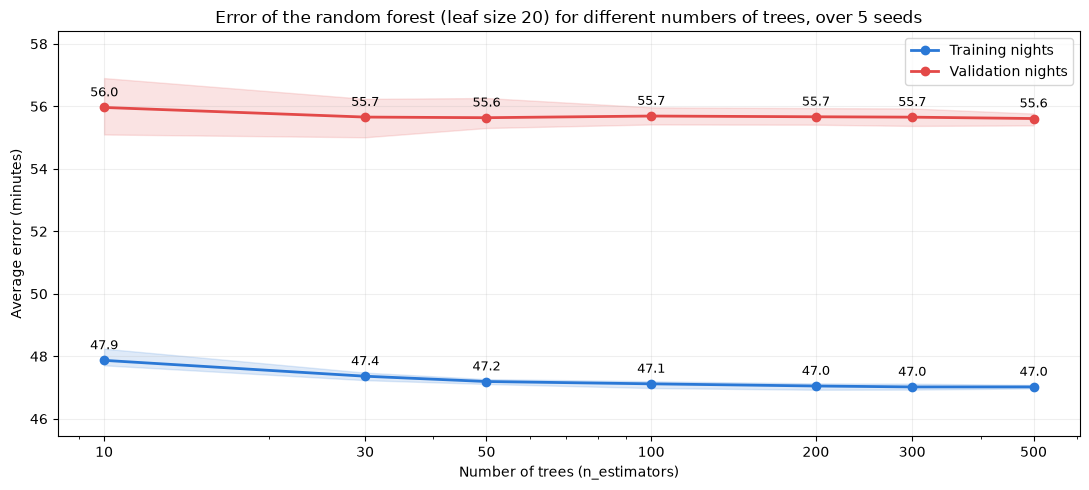

In [33]:
# Number of trees, with the chosen leaf size of 20. Each setting is run with 5 different seeds:
# the line is their average, the shaded band shows how much the result changes between seeds.
tree_counts = [10, 30, 50, 100, 200, 300, 500]
tree_errors = []
for trees in tree_counts:
    for seed in range(SEED, SEED + 5):
        forest = RandomForestRegressor(n_estimators=trees, min_samples_leaf=20, random_state=seed, n_jobs=-1)
        forest.fit(leaf_inputs[train], target[train])
        tree_errors.append({
            "trees": trees,
            "Training nights": mean_absolute_error(target[train], forest.predict(leaf_inputs[train])),
            "Validation nights": mean_absolute_error(target[validation], forest.predict(leaf_inputs[validation])),
        })
tree_errors = pd.DataFrame(tree_errors).groupby("trees").agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(11, 5))
for column, color in [("Training nights", "#2a78d6"), ("Validation nights", "#e34948")]:
    ax.plot(tree_errors.index, tree_errors[(column, "mean")], color=color, marker="o", linewidth=2, label=column)
    ax.fill_between(tree_errors.index, tree_errors[(column, "min")], tree_errors[(column, "max")], color=color, alpha=0.15)
    for trees, error in tree_errors[(column, "mean")].items():
        ax.annotate(f"{error:.1f}", (trees, error), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set_xscale("log")
ax.set_xticks(tree_counts, [str(t) for t in tree_counts])
ax.set(title="Error of the random forest (leaf size 20) for different numbers of trees, over 5 seeds",
       xlabel="Number of trees (n_estimators)", ylabel="Average error (minutes)")
ax.margins(y=0.15)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

Adding more trees barely changes the validation error, and it does not overfit either: the training and validation errors both go down slightly and the gap between them stays the same. What more trees do change is how much the result depends on luck: with few trees the five seeds spread out noticeably, while from about 100–200 trees the result is nearly the same. I will use 200 trees.

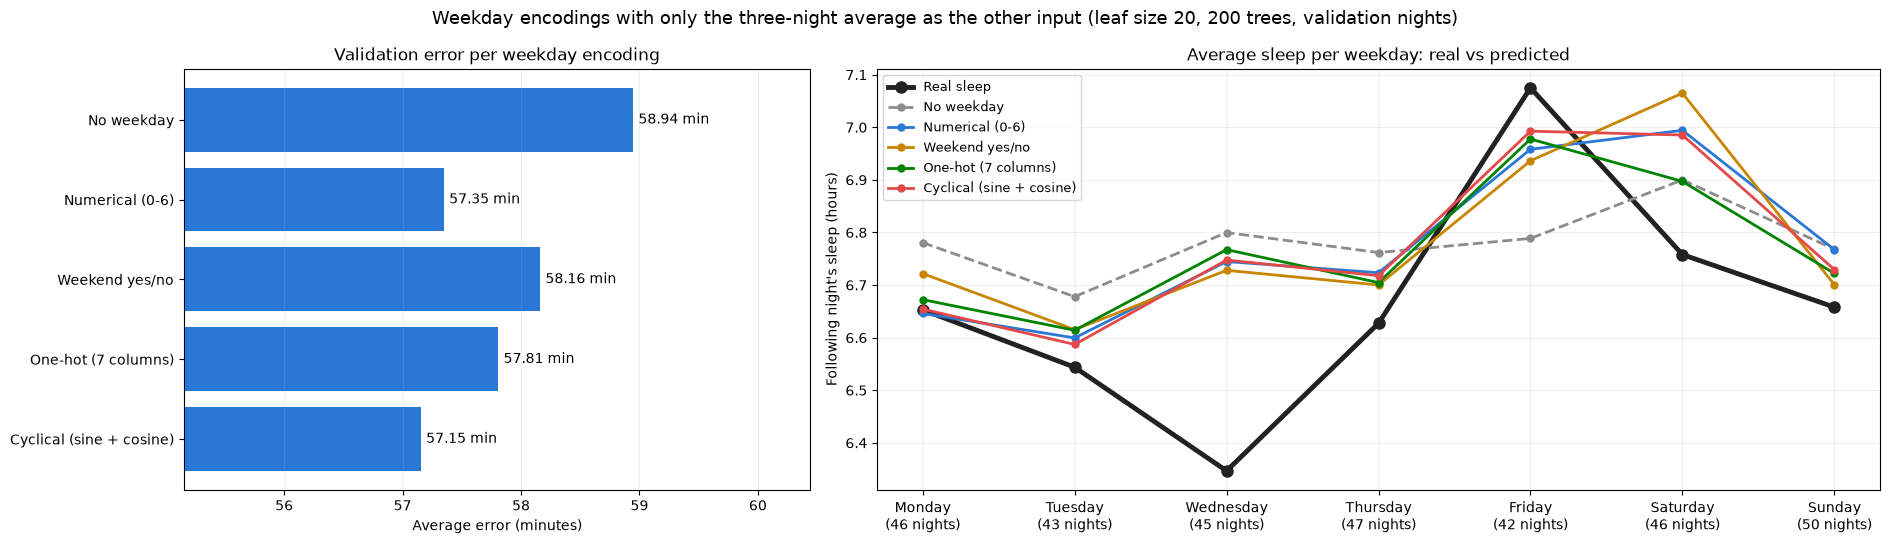

In [34]:
# The weekday test again, with the chosen forest (leaf size 20, 200 trees) and only the
# three-night average next to the weekday, so the weekday has room to show its effect.
weekday_errors_2, weekday_predictions_2, weekday_forests_2 = {}, {}, {}
for name, weekday_columns in weekday_versions.items():
    inputs = pd.concat([model_data[["avg_sleep_last_3_nights"]], weekday_columns], axis=1)
    forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
    forest.fit(inputs[train], target[train])
    weekday_forests_2[name] = forest
    weekday_predictions_2[name] = forest.predict(inputs[validation])
    weekday_errors_2[name] = mean_absolute_error(target[validation], weekday_predictions_2[name])
weekday_errors_2 = pd.Series(weekday_errors_2)

fig, (left, right) = plt.subplots(1, 2, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
bars = left.barh(weekday_errors_2.index[::-1], weekday_errors_2.values[::-1], color="#2a78d6")
left.bar_label(bars, fmt="%.2f min", padding=4)
# The axis does not start at 0, so the differences between the versions are visible.
left.set_xlim(weekday_errors_2.min() - 2, weekday_errors_2.max() + 1.5)
left.set(title="Validation error per weekday encoding", xlabel="Average error (minutes)")
left.grid(axis="x", alpha=0.2)

pattern_2 = pd.DataFrame({"Real sleep": target[validation].to_numpy()} | weekday_predictions_2)
pattern_2 = pattern_2.groupby(validation_days).mean() / 60
right.plot(range(7), pattern_2["Real sleep"], color="#222222", linewidth=3.5, marker="o", markersize=8, label="Real sleep")
for name, style in styles.items():
    right.plot(range(7), pattern_2[name], linewidth=2, marker="o", markersize=5, label=name, **style)
right.set_xticks(range(7), [f"{name}\n({n} nights)" for name, n in zip(weekday_names, nights_per_day)])
right.set(title="Average sleep per weekday: real vs predicted", ylabel="Following night's sleep (hours)")
right.grid(alpha=0.2)
right.legend(loc="upper left", fontsize=9)
fig.suptitle("Weekday encodings with only the three-night average as the other input (leaf size 20, 200 trees, validation nights)", fontsize=13)
plt.tight_layout()
plt.show()

With only the three-night average next to it, cyclical still has the lowest error.

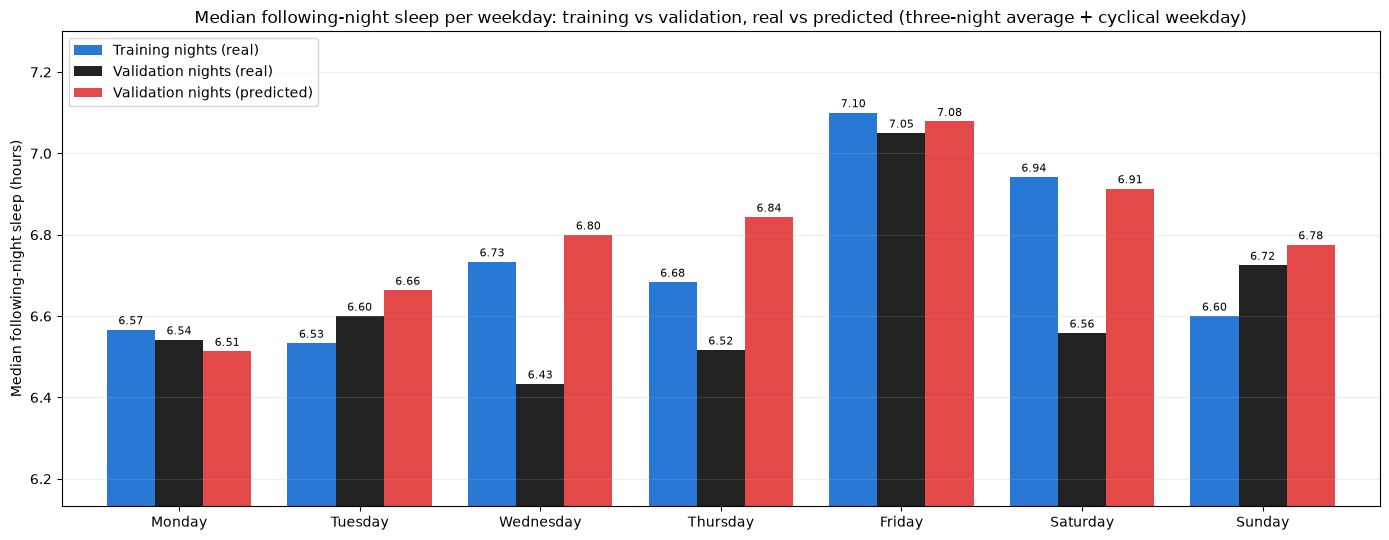

In [35]:
# The same comparison for the forest above (only the three-night average and the cyclical weekday).
weekday_medians_2 = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
    "Validation nights (predicted)": pd.Series(weekday_predictions_2["Cyclical (sine + cosine)"]).groupby(validation_days).median(),
}) / 60
weekday_medians_2.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
weekday_medians_2.plot.bar(color=["#2a78d6", "#222222", "#e34948"], width=0.8, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(weekday_medians_2.min().min() - 0.3, weekday_medians_2.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: training vs validation, real vs predicted (three-night average + cyclical weekday)",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left")
plt.tight_layout()
plt.show()

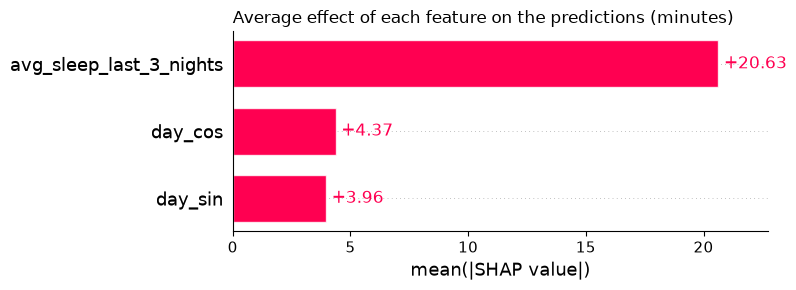

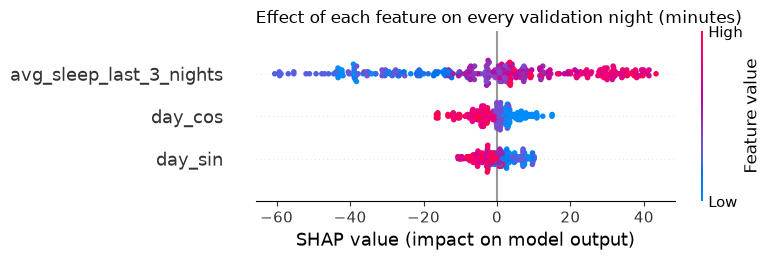

In [36]:
# SHAP for the cyclical forest already trained above (three-night average and cyclical weekday), so nothing is trained again.
shap_inputs_2 = pd.concat([model_data[["avg_sleep_last_3_nights"]], weekday_versions["Cyclical (sine + cosine)"]], axis=1)
shap_values_2 = shap.TreeExplainer(weekday_forests_2["Cyclical (sine + cosine)"])(shap_inputs_2[validation])

shap.plots.bar(shap_values_2, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_2, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

As it would seem, having the last average sleep for the last 3 nights, the day cosines, the day sinus, and the encoding of the weekday or weekend seems to have reduced the margin of error significantly. Now the model tends to see the patterns better. It's able to find out that, relatively, Monday values keep them close. The margin of error has gone down significantly.

However, days that are different due to the dataset validation nights (the real validation nights in some cases, like Thursday, Saturday, and Wednesday) are way shorter than they were in the training nights. The model gets confused and predicts that the night should be longer. Perhaps this has to do with just random luck and the way that the split has been made. 

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
No weekday,58.944,78.696,-0.025,34.796,62.069
Numerical (0-6),57.346,77.845,-0.003,36.677,65.204
Weekend yes/no,58.159,78.047,-0.008,35.110,64.577
One-hot (7 columns),57.806,77.864,-0.003,35.737,64.263
Cyclical (sine + cosine),57.152,77.771,-0.001,36.364,65.517


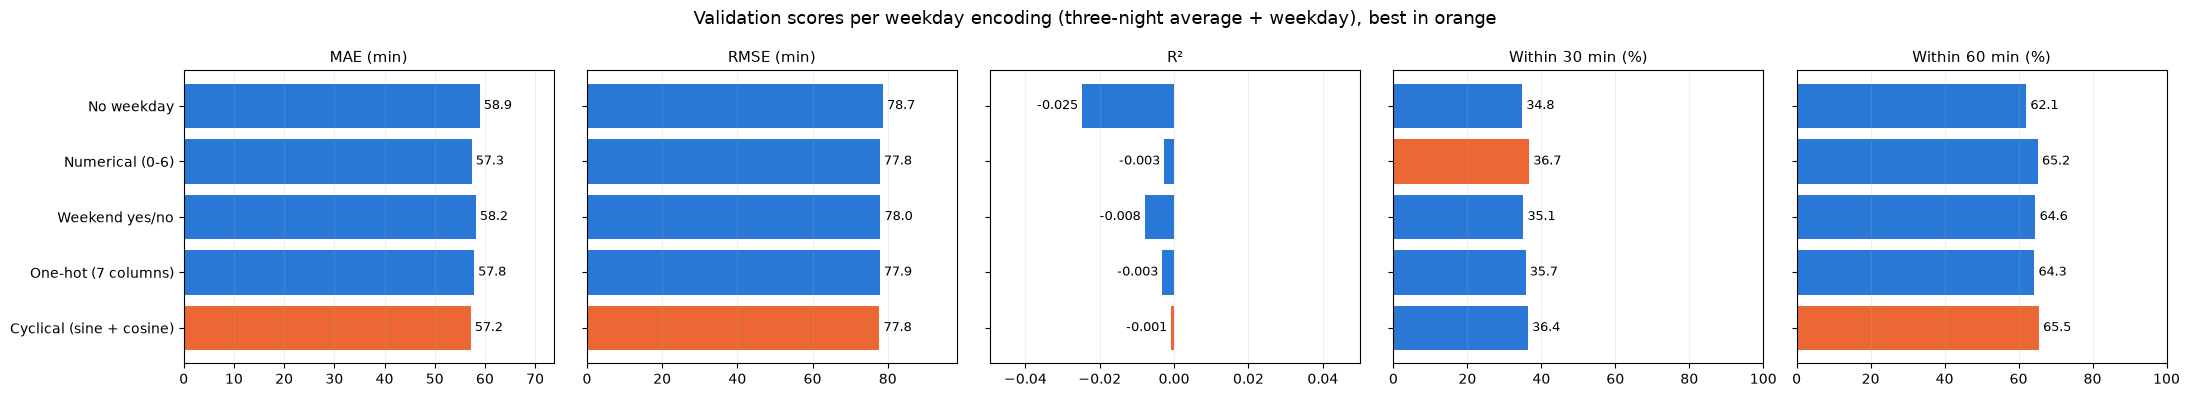

In [37]:
weekday_scores_2 = scores(weekday_predictions_2)
display(weekday_scores_2.round(3))

# One small chart per score, best version in orange.
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, score in zip(axes, weekday_scores_2.columns):
    values = weekday_scores_2[score]
    best = values.min() if score in ["MAE (min)", "RMSE (min)"] else values.max()
    bars = ax.barh(values.index, values, color=["#eb6834" if value == best else "#2a78d6" for value in values])
    ax.bar_label(bars, fmt="%.3f" if score == "R²" else "%.1f", padding=3, fontsize=9)
    if score == "R²":
        ax.set_xlim(min(0, values.min() * 2), max(0, values.max()) + 0.05)
    elif "%" in score:
        ax.set_xlim(0, 100)
    else:
        ax.set_xlim(0, values.max() * 1.25)
    ax.set_title(score, fontsize=11)
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle("Validation scores per weekday encoding (three-night average + weekday), best in orange", fontsize=13)
plt.tight_layout()
plt.show()

Even though the model has less error, it still fails to explain. Just the average of the last three nights and the weekday is not enough for a model to actually make an educated prediction.

In [38]:
# Cyclical won both weekday tests, so from here on every model uses only the sine and cosine of the day.
model_data["day_sin"] = np.sin(2 * np.pi * model_data["weekday_number"] / 7)
model_data["day_cos"] = np.cos(2 * np.pi * model_data["weekday_number"] / 7)
model_data = model_data.drop(columns=["weekend_night", "weekday_number"])

model_data.head()

,participant_id,date,split,avg_sleep_last_3_nights,previous_awake_minutes,previous_efficiency,previous_deep_minutes,resting_heart_rate,wake_up_hour,calories,fatigue,readiness,report_missing,next_sleep_minutes,is_female,is_evening_type,day_sin,day_cos
0,p01,2019-11-02,train,378.000000,52.0,97.0,36.0,53.0,7.316667,2541.18,2.0,6.0,0,378.0,0,0,-0.974928,-0.222521
1,p01,2019-11-03,train,378.000000,44.0,96.0,38.0,52.0,7.566667,2588.02,3.0,8.0,0,361.0,0,0,-0.781831,0.623490
2,p01,2019-11-04,train,372.333333,38.0,96.0,37.0,53.0,6.583333,2291.62,3.0,8.0,0,326.0,0,0,0.000000,1.000000
3,p01,2019-11-05,train,355.000000,36.0,99.0,27.0,54.0,6.416667,2495.25,3.0,8.0,0,341.0,0,0,0.781831,0.623490
4,p01,2019-11-06,train,342.666667,23.0,99.0,66.0,52.0,6.483333,1978.05,3.0,5.0,0,312.0,0,0,0.974928,-0.222521


## Feature selection
I add the features in groups on top of the three-night average and the cyclical weekday, using the chosen forest (leaf size 20, 200 trees). A group stays only if it improves the scores on the validation nights. First group: last night's details (minutes awake, efficiency and deep sleep).

In [39]:
# The starting point is the cyclical forest from the second weekday test, so it is not trained again.
start_features = ["avg_sleep_last_3_nights", "day_sin", "day_cos"]
group_forests = {"Three-night average + weekday": weekday_forests_2["Cyclical (sine + cosine)"]}
group_predictions = {"Three-night average + weekday": weekday_predictions_2["Cyclical (sine + cosine)"]}

last_night = ["previous_awake_minutes", "previous_efficiency", "previous_deep_minutes"]
inputs = model_data[start_features + last_night]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(inputs[train], target[train])
group_forests["+ last night's details"] = forest
group_predictions["+ last night's details"] = forest.predict(inputs[validation])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831


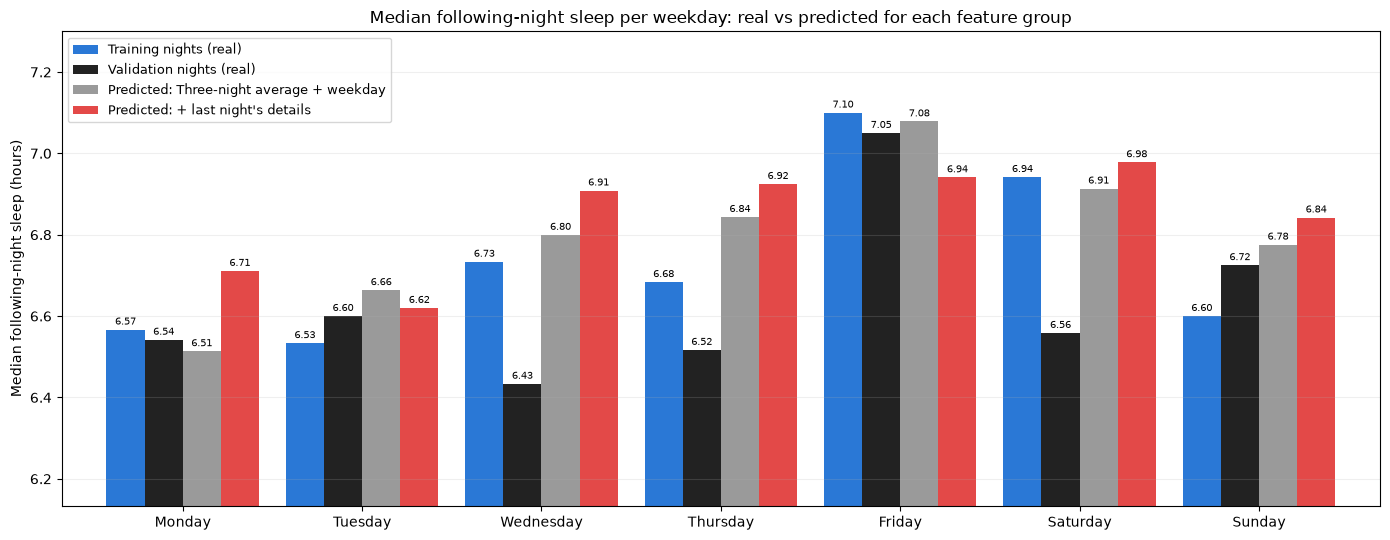

In [40]:
# Median sleep per weekday: the real nights, and the predictions of every feature group tested so far.
group_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
} | {
    f"Predicted: {name}": pd.Series(predicted).groupby(validation_days).median()
    for name, predicted in group_predictions.items()
}) / 60
group_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
group_medians.plot.bar(color=["#2a78d6", "#222222", "#9a9a9a", "#e34948", "#2ca02c", "#9467bd", "#eb6834"][:len(group_medians.columns)], width=0.85, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(group_medians.min().min() - 0.3, group_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: real vs predicted for each feature group",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

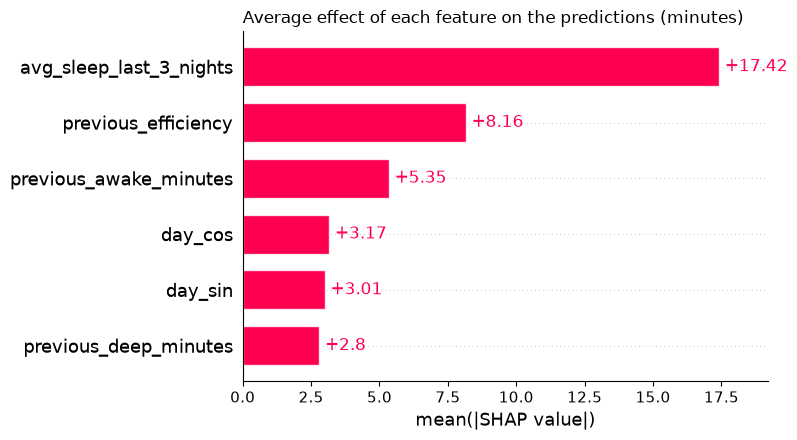

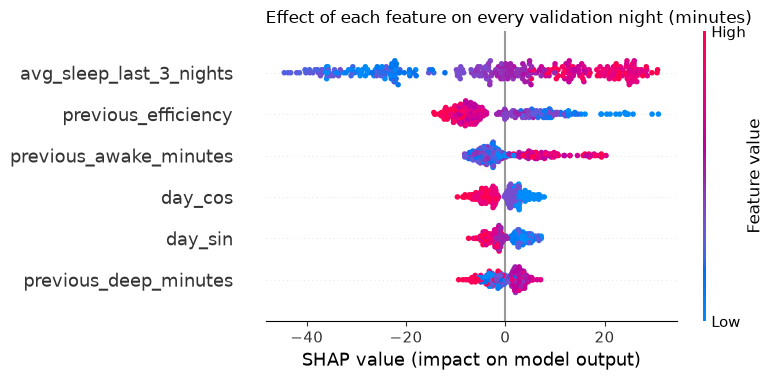

In [41]:
# SHAP for the forest with last night's details, already trained above.
shap_values_group = shap.TreeExplainer(group_forests["+ last night's details"])(model_data.loc[validation, start_features + last_night])

shap.plots.bar(shap_values_group, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_group, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

Adding last night's details made the predictions slightly less accurate, and fewer nights were within 30 minutes. R² improved a little, but that is nothing impressive. The beeswarm shows the same thing every time: the three-night average is spread out the most, which might be the reason for the low R². So next I try a model without it: only previous efficiency, previous awake minutes and the cyclical weekday.

In [42]:
# The same forest without the three-night average (and without deep sleep).
no_average = ["previous_efficiency", "previous_awake_minutes", "day_sin", "day_cos"]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(model_data.loc[train, no_average], target[train])
group_forests["Efficiency + awake + weekday (no average)"] = forest
group_predictions["Efficiency + awake + weekday (no average)"] = forest.predict(model_data.loc[validation, no_average])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442


But unfortunately, there is no luck. It seems that it's gotten even worse, so I still need to keep it. Perhaps in a later iteration, maybe if I remove it, it's going to influence the choice less, and it's going to be a better R2 value without it.

Next group: the body and profile features (resting heart rate, gender and A/B type). Like last night's details, they are added on top of the three-night average and the cyclical weekday, so every group is compared with the same starting point.

In [43]:
profile = ["resting_heart_rate", "is_female", "is_evening_type"]
inputs = model_data[start_features + profile]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(inputs[train], target[train])
group_forests["+ body and profile"] = forest
group_predictions["+ body and profile"] = forest.predict(inputs[validation])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442
+ body and profile,54.205,74.244,0.088,37.931,69.592


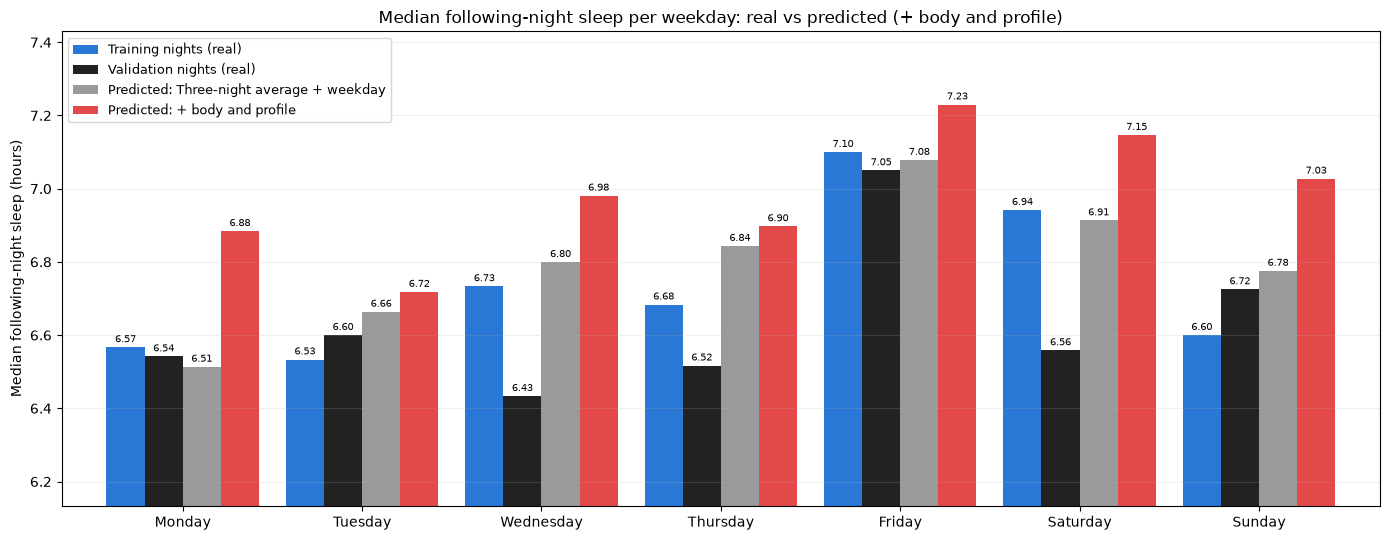

In [44]:
# Median sleep per weekday: the real nights, the starting point and this group.
shown = ["Three-night average + weekday", "+ body and profile"]
profile_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
} | {
    f"Predicted: {name}": pd.Series(group_predictions[name]).groupby(validation_days).median() for name in shown
}) / 60
profile_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
profile_medians.plot.bar(color=["#2a78d6", "#222222", "#9a9a9a", "#e34948"], width=0.85, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(profile_medians.min().min() - 0.3, profile_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: real vs predicted (+ body and profile)",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

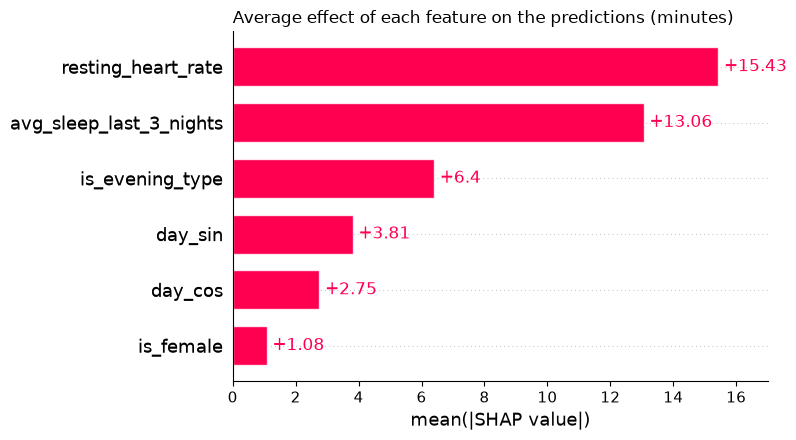

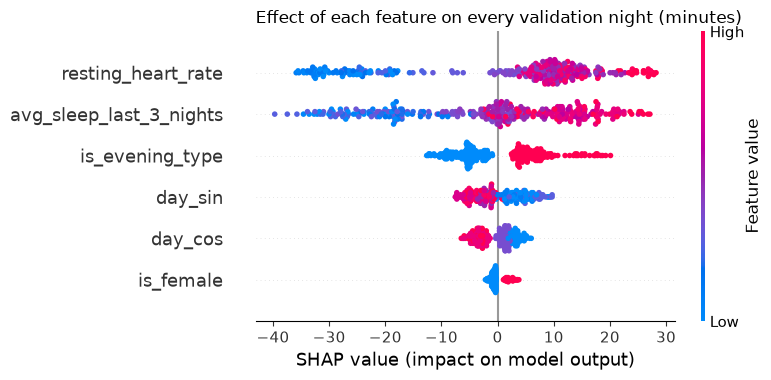

In [45]:
# SHAP for the forest with the body and profile features, already trained above.
shap_values_profile = shap.TreeExplainer(group_forests["+ body and profile"])(model_data.loc[validation, start_features + profile])

shap.plots.bar(shap_values_profile, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_profile, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

Adding the body and profile features is the biggest improvement so far: every score gets better, and the R² is clearly above 0 for the first time. Resting heart rate now moves the predictions about as much as the three-night average, and the A/B type (evening person or not) also plays a big role, while gender barely matters. The three-night average is still spread out a lot, so I want to test once more without it, now that the body and profile features are in.

In [46]:
# The body and profile group again, but without the three-night average.
profile_no_average = profile + ["day_sin", "day_cos"]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(model_data.loc[train, profile_no_average], target[train])
group_forests["Body and profile + weekday (no average)"] = forest
group_predictions["Body and profile + weekday (no average)"] = forest.predict(model_data.loc[validation, profile_no_average])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442
+ body and profile,54.205,74.244,0.088,37.931,69.592
Body and profile + weekday (no average),54.898,73.831,0.098,40.125,65.517


Without the three-night average, the R² improved slightly, so noisy features like the average sleep may be part of the reason the R² stays low. The MAE went up a little, but more guesses landed within 30 minutes, which I count as an improvement, although fewer landed within an hour. That is worth keeping in mind for the final feature choice.

Next group: the wake-up hour. In the EDA, waking up earlier than usual came before a slightly shorter night, and it may also carry part of the weekend pattern. It is added on top of the same starting point.

In [47]:
wake_up = ["wake_up_hour"]
inputs = model_data[start_features + wake_up]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(inputs[train], target[train])
group_forests["+ wake-up hour"] = forest
group_predictions["+ wake-up hour"] = forest.predict(inputs[validation])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442
+ body and profile,54.205,74.244,0.088,37.931,69.592
Body and profile + weekday (no average),54.898,73.831,0.098,40.125,65.517
+ wake-up hour,56.213,77.022,0.018,38.558,63.950


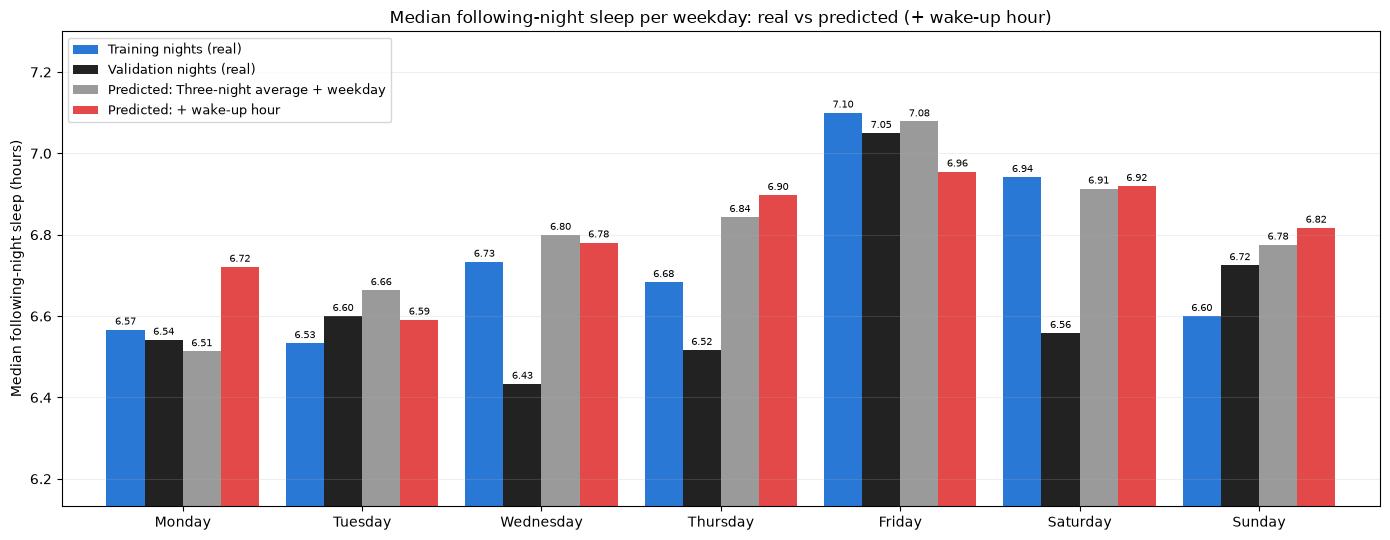

In [48]:
# Median sleep per weekday: the real nights, the starting point and this group.
shown = ["Three-night average + weekday", "+ wake-up hour"]
wake_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
} | {
    f"Predicted: {name}": pd.Series(group_predictions[name]).groupby(validation_days).median() for name in shown
}) / 60
wake_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
wake_medians.plot.bar(color=["#2a78d6", "#222222", "#9a9a9a", "#e34948"], width=0.85, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(wake_medians.min().min() - 0.3, wake_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: real vs predicted (+ wake-up hour)",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

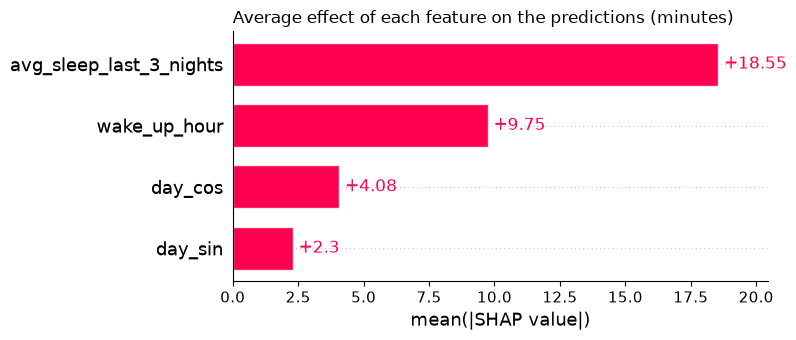

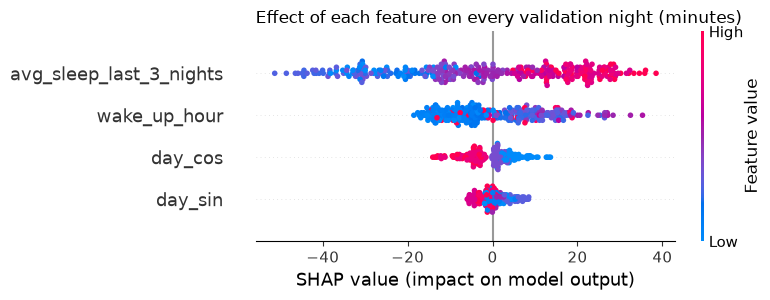

In [49]:
# SHAP for the forest with the wake-up hour, already trained above.
shap_values_wake = shap.TreeExplainer(group_forests["+ wake-up hour"])(model_data.loc[validation, start_features + wake_up])

shap.plots.bar(shap_values_wake, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_wake, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

This group adds little. In the beeswarm, an early wake-up mostly goes with a shorter predicted night and a later wake-up with a longer one, which makes sense, although the colours are quite mixed. A few scores improved slightly, so it is worth seeing how it does together with the other groups later. I wonder if there will be any difference if I get rid of the average once again.

In [50]:
# The wake-up hour again, but without the three-night average.
wake_no_average = wake_up + ["day_sin", "day_cos"]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(model_data.loc[train, wake_no_average], target[train])
group_forests["Wake-up hour + weekday (no average)"] = forest
group_predictions["Wake-up hour + weekday (no average)"] = forest.predict(model_data.loc[validation, wake_no_average])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442
+ body and profile,54.205,74.244,0.088,37.931,69.592
Body and profile + weekday (no average),54.898,73.831,0.098,40.125,65.517
+ wake-up hour,56.213,77.022,0.018,38.558,63.950
Wake-up hour + weekday (no average),59.359,78.162,-0.011,32.288,62.069


In this case, the wake-up hour on its own doesn't seem to be helping all that much. It even increases the median errors.

Next group: the morning reports (fatigue, readiness and `report_missing`). The gaps in fatigue and readiness were filled with KNN, and `report_missing` marks the nights that had no report. They are added on top of the same starting point.

In [51]:
reports = ["fatigue", "readiness", "report_missing"]
inputs = model_data[start_features + reports]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(inputs[train], target[train])
group_forests["+ reports"] = forest
group_predictions["+ reports"] = forest.predict(inputs[validation])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442
+ body and profile,54.205,74.244,0.088,37.931,69.592
Body and profile + weekday (no average),54.898,73.831,0.098,40.125,65.517
+ wake-up hour,56.213,77.022,0.018,38.558,63.950
Wake-up hour + weekday (no average),59.359,78.162,-0.011,32.288,62.069
+ reports,55.507,75.755,0.050,37.618,66.144


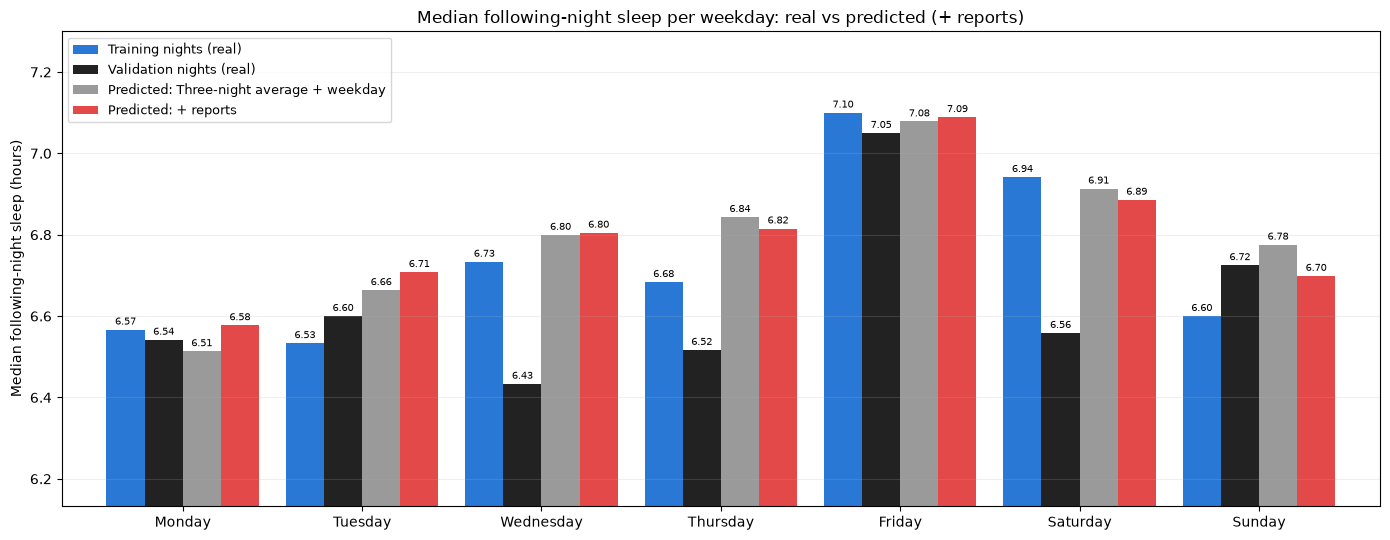

In [52]:
# Median sleep per weekday: the real nights, the starting point and this group.
shown = ["Three-night average + weekday", "+ reports"]
reports_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
} | {
    f"Predicted: {name}": pd.Series(group_predictions[name]).groupby(validation_days).median() for name in shown
}) / 60
reports_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
reports_medians.plot.bar(color=["#2a78d6", "#222222", "#9a9a9a", "#e34948"], width=0.85, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(reports_medians.min().min() - 0.3, reports_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: real vs predicted (+ reports)",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

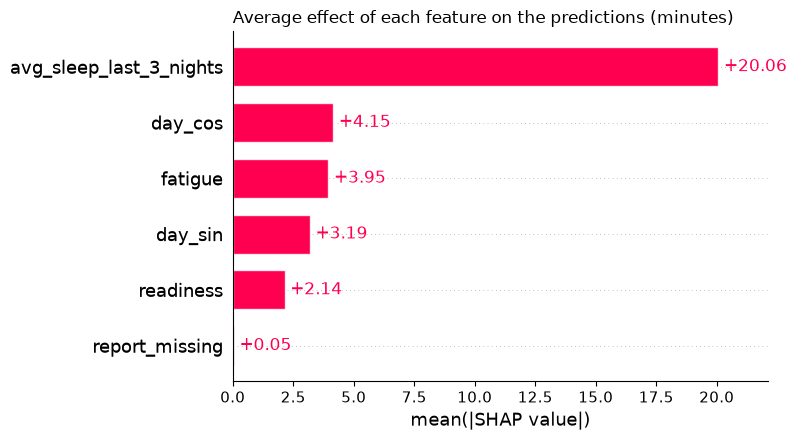

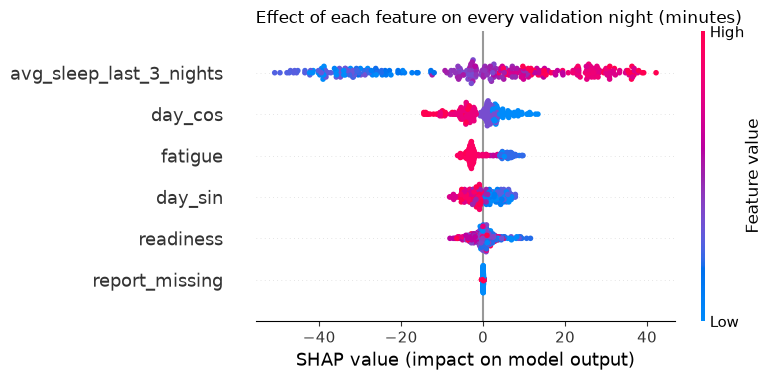

In [53]:
# SHAP for the forest with the reports, already trained above.
shap_values_reports = shap.TreeExplainer(group_forests["+ reports"])(model_data.loc[validation, start_features + reports])

shap.plots.bar(shap_values_reports, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_reports, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

This model basically gives us no information. These features give us little to basically no information. Maybe fatigue gives us something, but readiness, for example, and report missing almost give us nothing. Average sleep plus tonight's sleep is the highest. 

In [54]:
# The reports again, but without the three-night average.
reports_no_average = reports + ["day_sin", "day_cos"]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(model_data.loc[train, reports_no_average], target[train])
group_forests["Reports + weekday (no average)"] = forest
group_predictions["Reports + weekday (no average)"] = forest.predict(model_data.loc[validation, reports_no_average])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442
+ body and profile,54.205,74.244,0.088,37.931,69.592
Body and profile + weekday (no average),54.898,73.831,0.098,40.125,65.517
+ wake-up hour,56.213,77.022,0.018,38.558,63.950
Wake-up hour + weekday (no average),59.359,78.162,-0.011,32.288,62.069
+ reports,55.507,75.755,0.050,37.618,66.144
Reports + weekday (no average),57.406,74.853,0.073,32.915,63.323


The average seems to be, again, creating more noise and seems to be decreasing the R² value, but it helps us get more of the nights within proximity and decreases the average error.

Last group: calories burned during the day. It is added on top of the same starting point, and like the other groups also tested without the three-night average.

In [55]:
calories = ["calories"]
inputs = model_data[start_features + calories]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(inputs[train], target[train])
group_forests["+ calories"] = forest
group_predictions["+ calories"] = forest.predict(inputs[validation])

# Calories without the three-night average.
calories_no_average = calories + ["day_sin", "day_cos"]
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
forest.fit(model_data.loc[train, calories_no_average], target[train])
group_forests["Calories + weekday (no average)"] = forest
group_predictions["Calories + weekday (no average)"] = forest.predict(model_data.loc[validation, calories_no_average])

display(scores(group_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
+ last night's details,57.648,77.338,0.010,34.483,65.831
Efficiency + awake + weekday (no average),60.373,78.755,-0.026,32.915,61.442
+ body and profile,54.205,74.244,0.088,37.931,69.592
Body and profile + weekday (no average),54.898,73.831,0.098,40.125,65.517
+ wake-up hour,56.213,77.022,0.018,38.558,63.950
Wake-up hour + weekday (no average),59.359,78.162,-0.011,32.288,62.069
+ reports,55.507,75.755,0.050,37.618,66.144
Reports + weekday (no average),57.406,74.853,0.073,32.915,63.323
+ calories,56.386,76.557,0.030,37.931,64.577


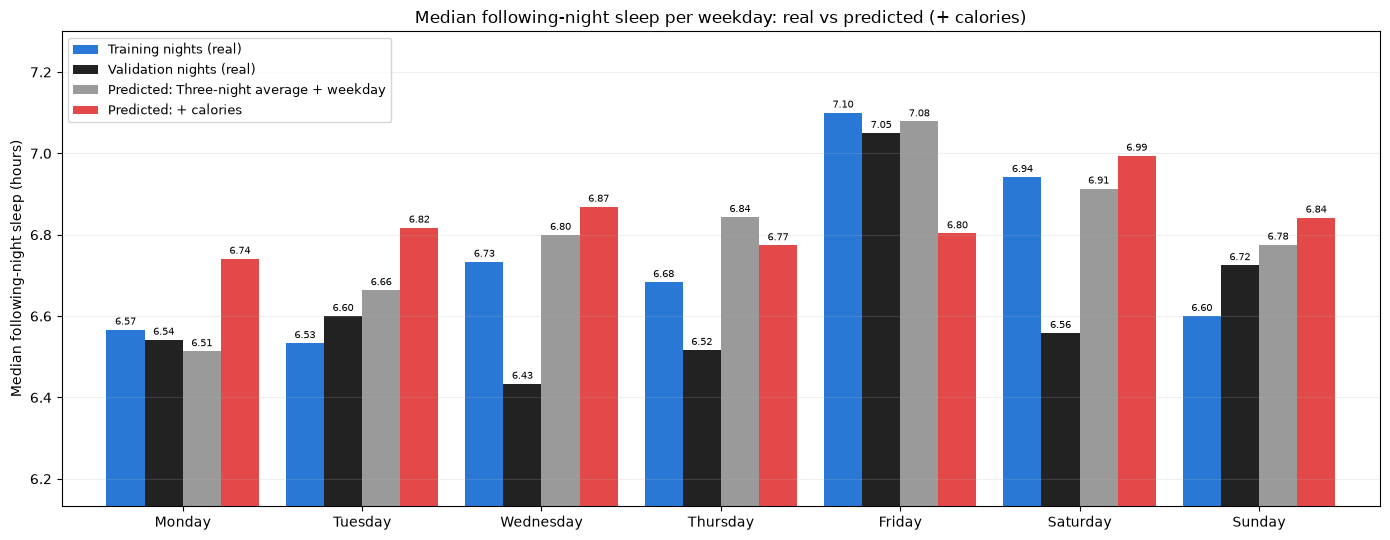

In [56]:
# Median sleep per weekday: the real nights, the starting point and this group.
shown = ["Three-night average + weekday", "+ calories"]
calories_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
} | {
    f"Predicted: {name}": pd.Series(group_predictions[name]).groupby(validation_days).median() for name in shown
}) / 60
calories_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
calories_medians.plot.bar(color=["#2a78d6", "#222222", "#9a9a9a", "#e34948"], width=0.85, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(calories_medians.min().min() - 0.3, calories_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: real vs predicted (+ calories)",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

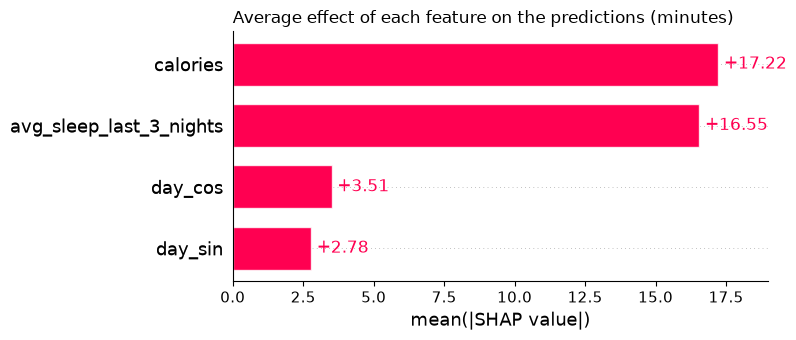

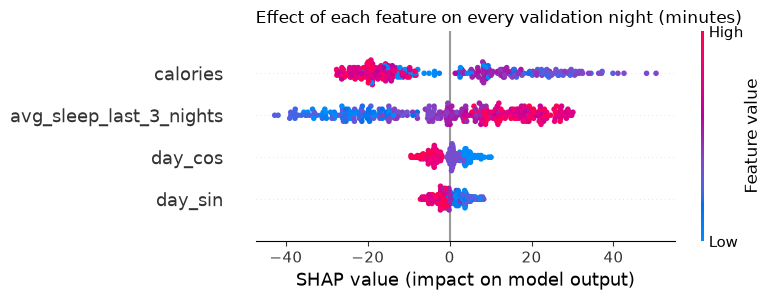

In [57]:
# SHAP for the forest with calories, already trained above.
shap_values_calories = shap.TreeExplainer(group_forests["+ calories"])(model_data.loc[validation, start_features + calories])

shap.plots.bar(shap_values_calories, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_calories, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

Calories play quite a big role in the SHAP charts, but the scores barely improve and the R² only goes up a little. This time, dropping the three-night average does not raise the R², because calories alone say little about the following night's sleep. They might help more when combined with the other profile features.

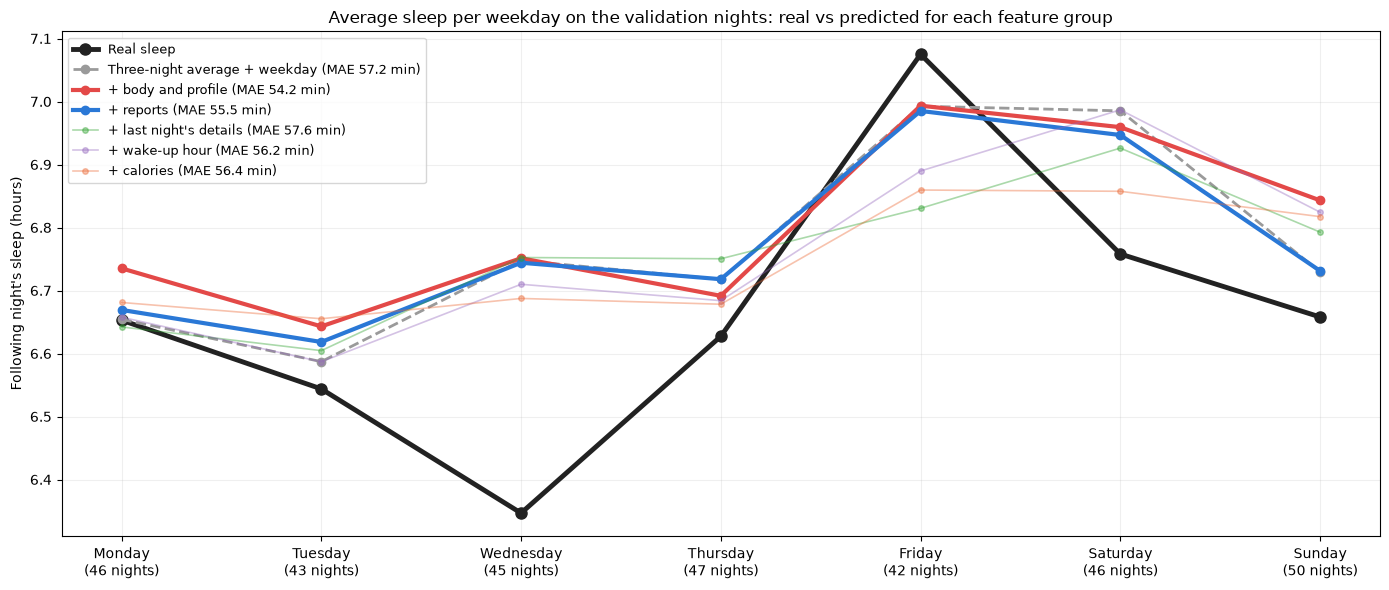

In [58]:
# Average sleep per weekday on the validation nights: the real nights, the starting point and every group added to it.
# The two groups with the best scores are drawn strong; the others are faded.
group_lines = pd.DataFrame({"Real sleep": target[validation].to_numpy()} | {
    name: group_predictions[name] for name in [
        "Three-night average + weekday", "+ body and profile", "+ reports",
        "+ last night's details", "+ wake-up hour", "+ calories",
    ]
}).groupby(validation_days).mean() / 60
line_styles = {
    "Real sleep": dict(color="#222222", linewidth=3.5, marker="o", markersize=8),
    "Three-night average + weekday": dict(color="#9a9a9a", linewidth=2, linestyle="--", marker="o"),
    "+ body and profile": dict(color="#e34948", linewidth=3, marker="o"),
    "+ reports": dict(color="#2a78d6", linewidth=3, marker="o"),
    "+ last night's details": dict(color="#2ca02c", linewidth=1.2, alpha=0.4, marker="o", markersize=4),
    "+ wake-up hour": dict(color="#9467bd", linewidth=1.2, alpha=0.4, marker="o", markersize=4),
    "+ calories": dict(color="#eb6834", linewidth=1.2, alpha=0.4, marker="o", markersize=4),
}

fig, ax = plt.subplots(figsize=(14, 6))
for name, style in line_styles.items():
    label = name if name == "Real sleep" else f"{name} (MAE {scores({name: group_predictions[name]}).loc[name, 'MAE (min)']:.1f} min)"
    ax.plot(range(7), group_lines[name], label=label, **style)
ax.set_xticks(range(7), [f"{name}\n({n} nights)" for name, n in zip(weekday_names, nights_per_day)])
ax.set(title="Average sleep per weekday on the validation nights: real vs predicted for each feature group",
       ylabel="Following night's sleep (hours)")
ax.grid(alpha=0.2)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

As the table and the chart show, body and profile and the reports are the two best groups, so I combine them first and then check whether adding the other groups on top improves the result further.

In [59]:
# The group sets, from the best two groups up to all of them.
group_sets = {
    "Body and profile + reports": profile + reports,
    "Body and profile + reports + wake-up hour": profile + reports + wake_up,
    "Body and profile + reports + calories": profile + reports + calories,
    "Body and profile + reports + calories + wake-up hour": profile + reports + calories + wake_up,
    "All groups": profile + reports + calories + wake_up + last_night,
}


def train_forest(features):
    """The chosen forest (leaf size 20, 200 trees), trained on the training nights; returns it with its validation predictions."""
    forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
    forest.fit(model_data.loc[train, features], target[train])
    return forest, forest.predict(model_data.loc[validation, features])


# Going up: the starting point and body and profile are already trained, then each set with the three-night average.
combo_forests = {
    "Three-night average + weekday": group_forests["Three-night average + weekday"],
    "Body and profile": group_forests["+ body and profile"],
}
combo_predictions = {
    "Three-night average + weekday": group_predictions["Three-night average + weekday"],
    "Body and profile": group_predictions["+ body and profile"],
}
for name, features in group_sets.items():
    combo_forests[name], combo_predictions[name] = train_forest(start_features + features)

# Going down: the same sets without the three-night average, ending with body and profile alone (already trained).
for name, features in reversed(group_sets.items()):
    combo_forests[f"{name} (no average)"], combo_predictions[f"{name} (no average)"] = train_forest(["day_sin", "day_cos"] + features)
combo_forests["Body and profile (no average)"] = group_forests["Body and profile + weekday (no average)"]
combo_predictions["Body and profile (no average)"] = group_predictions["Body and profile + weekday (no average)"]

display(scores(combo_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Three-night average + weekday,57.152,77.771,-0.001,36.364,65.517
Body and profile,54.205,74.244,0.088,37.931,69.592
Body and profile + reports,53.733,73.304,0.111,39.185,68.966
Body and profile + reports + wake-up hour,54.095,73.722,0.101,39.185,68.025
Body and profile + reports + calories,54.615,73.988,0.094,38.245,67.085
Body and profile + reports + calories + wake-up hour,54.746,74.146,0.090,36.991,68.025
All groups,55.782,75.046,0.068,37.304,66.458
All groups (no average),55.817,74.868,0.073,36.991,65.204
Body and profile + reports + calories + wake-up hour (no average),55.302,74.134,0.091,37.931,66.458
Body and profile + reports + calories (no average),54.690,73.646,0.103,38.558,65.204


Even with proper feature selection, the R² is still low. The best R² comes from body and profile + reports without the average, which is not much better than the first iteration, while the version with the average has the lower MAE. Most combinations score almost the same, so the differences between them are too small to matter much.

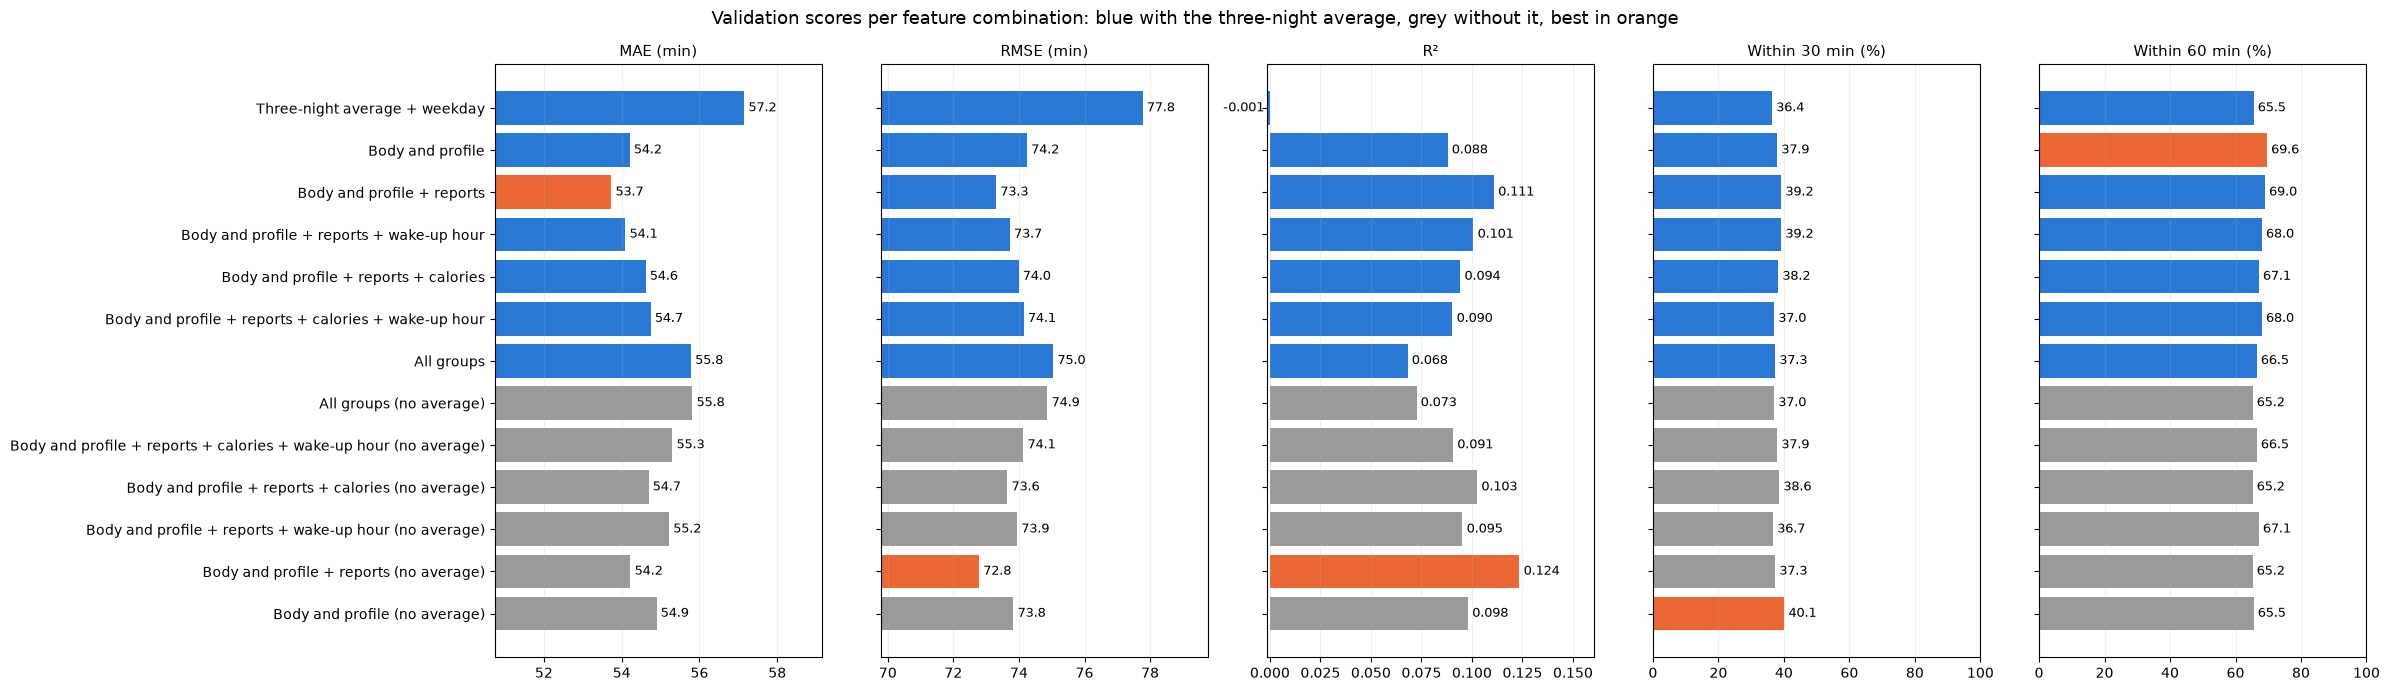

In [60]:
# One small chart per score, in the order of the table: up with the three-night average, then down without it.
combo_scores = scores(combo_predictions)
fig, axes = plt.subplots(1, 5, figsize=(24, 7), sharey=True)
for ax, score in zip(axes, combo_scores.columns):
    values = combo_scores[score]
    best = values.min() if score in ["MAE (min)", "RMSE (min)"] else values.max()
    colors = ["#eb6834" if value == best else "#9a9a9a" if "no average" in name else "#2a78d6" for name, value in values.items()]
    bars = ax.barh(values.index, values, color=colors)
    ax.bar_label(bars, fmt="%.3f" if score == "R²" else "%.1f", padding=3, fontsize=9)
    if score == "R²":
        ax.set_xlim(min(0, values.min() * 2), values.max() * 1.3)
    elif "%" in score:
        ax.set_xlim(0, 100)
    else:
        # The axis does not start at 0, so the differences between the combinations are visible.
        ax.set_xlim(values.min() - 3, values.max() + 2)
    ax.set_title(score, fontsize=11)
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle("Validation scores per feature combination: blue with the three-night average, grey without it, best in orange", fontsize=13)
plt.tight_layout()
plt.show()

I want to explore and see how dropping certain features that are low impact would affect the overall R2 value and the MAE. 

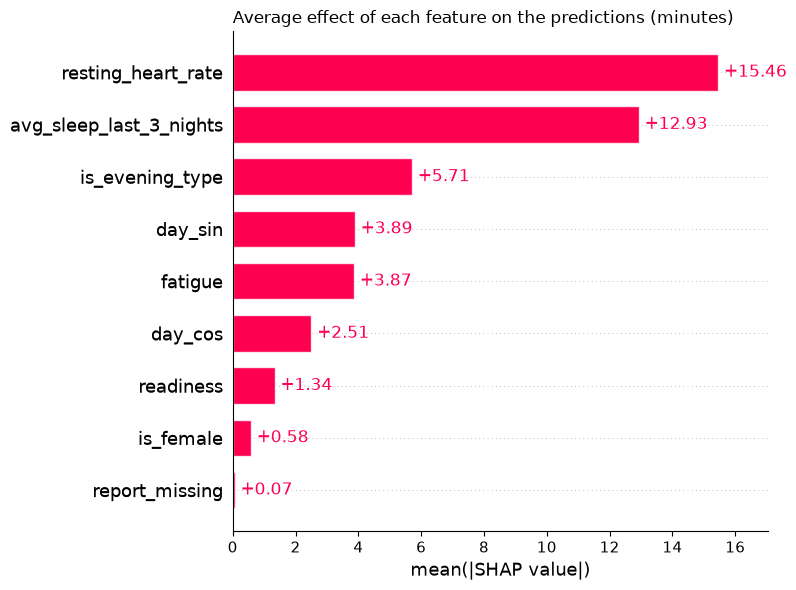

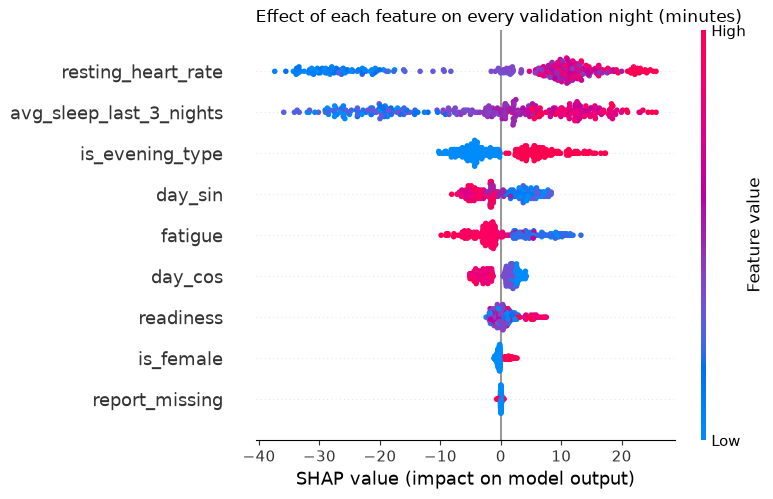

In [61]:
# SHAP for the best combination (body and profile + reports, with the three-night average), already trained above.
best_features = start_features + profile + reports
shap_values_best = shap.TreeExplainer(combo_forests["Body and profile + reports"])(model_data.loc[validation, best_features])

shap.plots.bar(shap_values_best, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_best, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

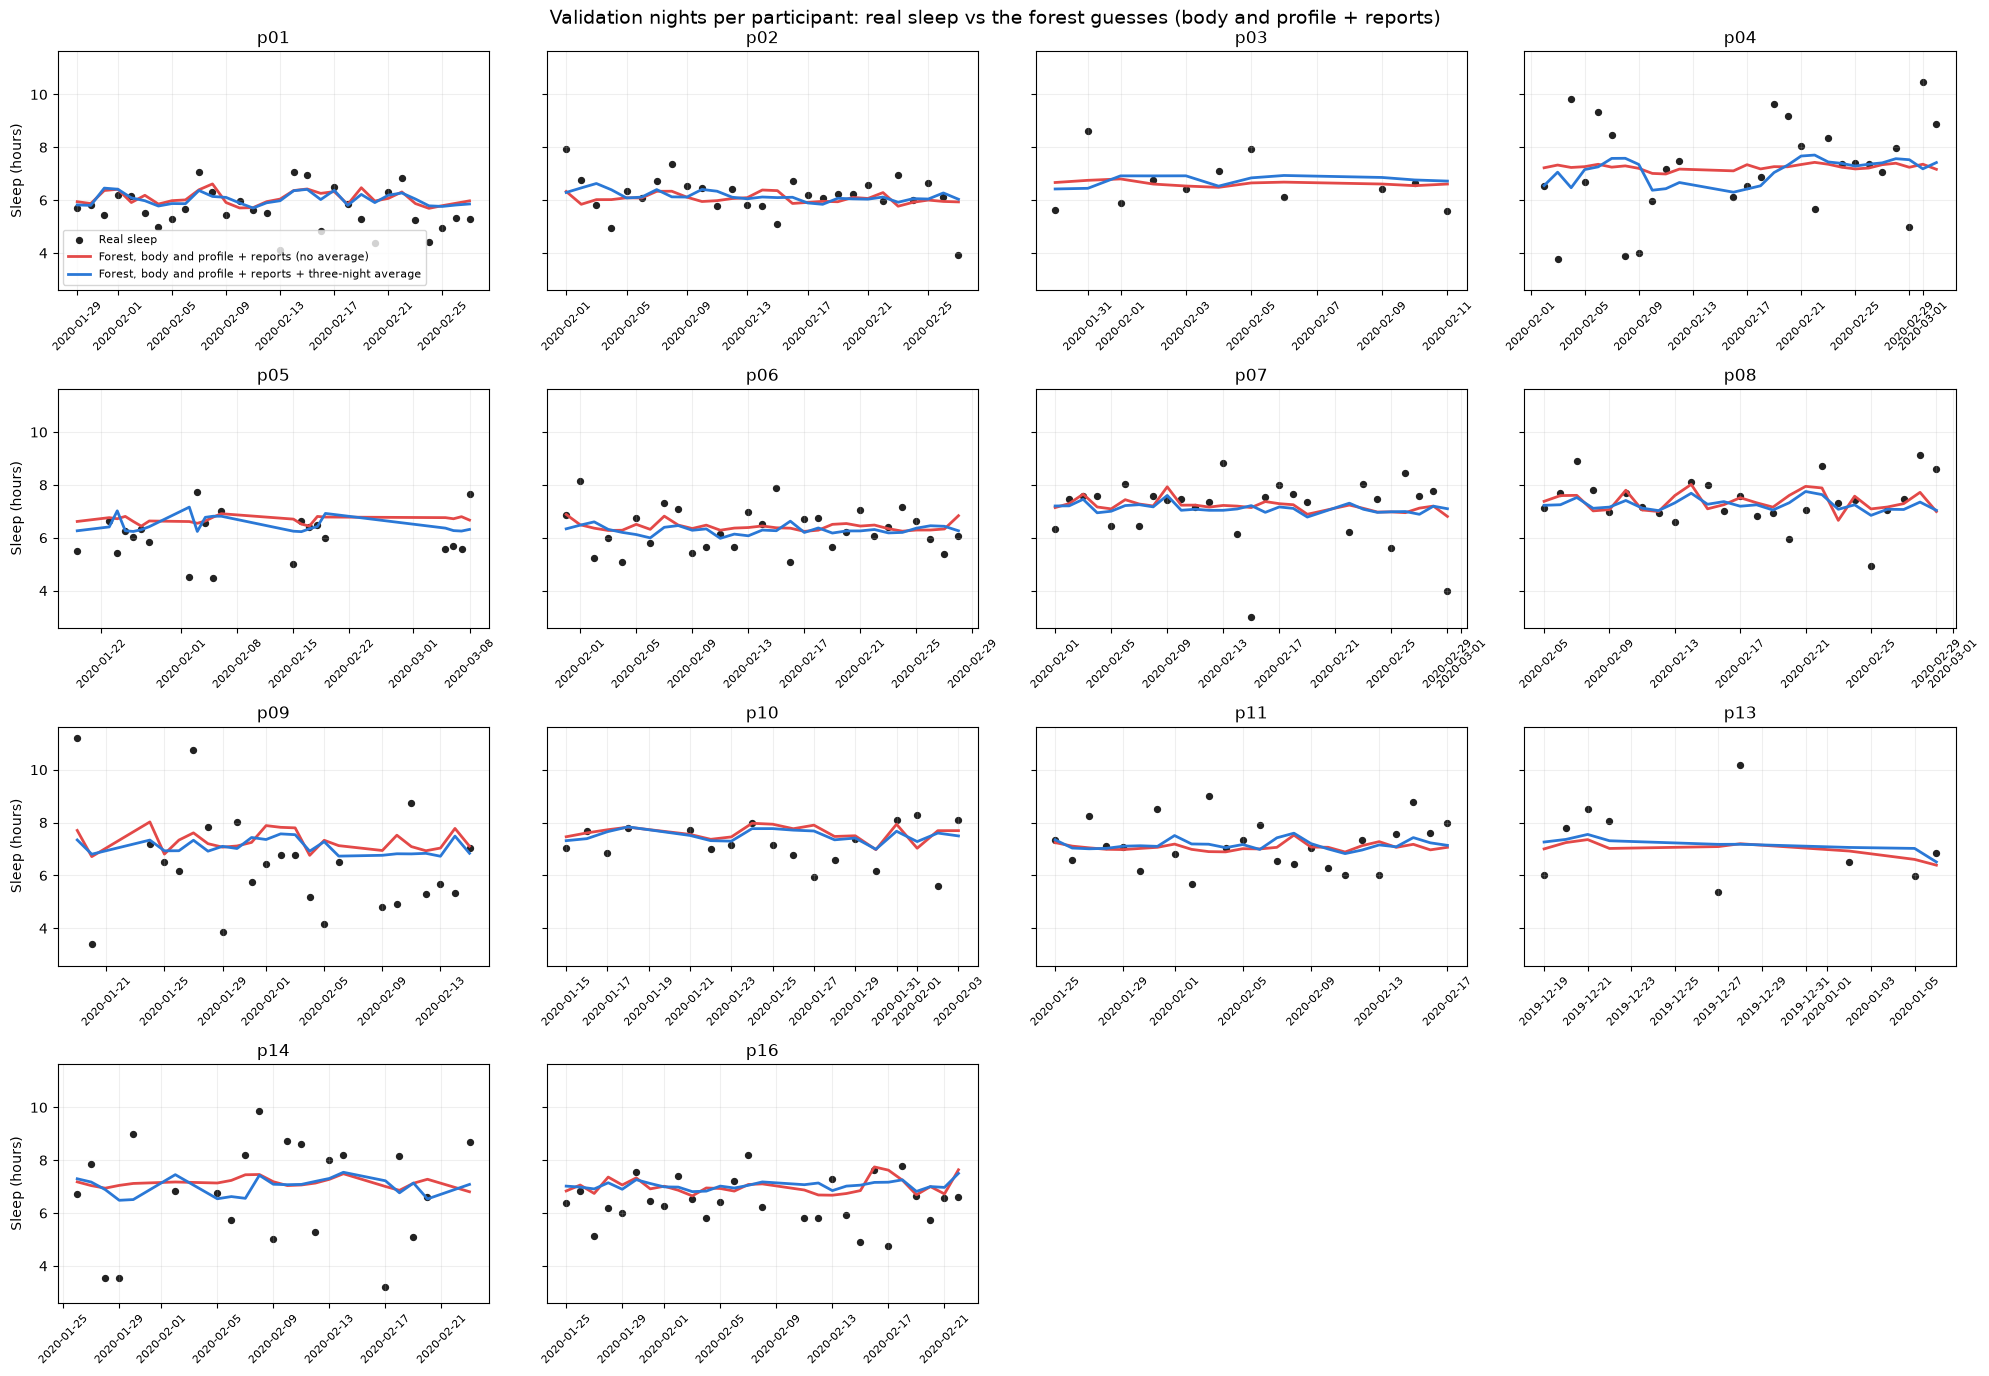

In [62]:
def plot_nights(lines, title, nights=validation):
    """Every night of one split per participant: the real sleep as dots and each model's guesses as a line."""
    night_view = model_data.loc[nights, ["participant_id", "date"]].assign(real=target[nights].to_numpy() / 60)
    people = night_view["participant_id"].unique()
    fig, axes = plt.subplots(4, 4, figsize=(20, 14), sharey=True)
    for ax, person in zip(axes.flat, people):
        rows = night_view["participant_id"].eq(person).to_numpy()
        ax.scatter(night_view.loc[rows, "date"], night_view.loc[rows, "real"], color="#222222", s=18, label="Real sleep")
        for (name, predicted), color in zip(lines.items(), ["#e34948", "#2a78d6"]):
            ax.plot(night_view.loc[rows, "date"], predicted[rows] / 60, color=color, linewidth=2, label=name)
        # Once the seven-night average exists (models section), it is always drawn as the baseline to beat.
        if "past_7_sleep_minutes" in model_data:
            baseline = model_data.loc[nights, "past_7_sleep_minutes"].to_numpy()[rows] / 60
            ax.plot(night_view.loc[rows, "date"], baseline, color="#9a9a9a", linewidth=1.5, linestyle="--",
                    label="Previous 7 recorded nights (baseline)")
        ax.set_title(person)
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        ax.grid(alpha=0.2)
    for ax in axes.flat[len(people):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("Sleep (hours)")
    axes.flat[0].legend(loc="lower left", fontsize=8)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


plot_nights({
    "Forest, body and profile + reports (no average)": combo_predictions["Body and profile + reports (no average)"],
    "Forest, body and profile + reports + three-night average": combo_predictions["Body and profile + reports"],
}, "Validation nights per participant: real sleep vs the forest guesses (body and profile + reports)")

Testing: heart rate seems to have the biggest impact, so I'll just drop "report is missing", "is female", and "readiness", and see how it changes stuff.

In [63]:
# The best combination without its three lowest-impact features, with and without the three-night average.
low_impact = ["report_missing", "is_female", "readiness"]
trimmed = [feature for feature in profile + reports if feature not in low_impact]

trim_predictions = {name: combo_predictions[name] for name in ["Body and profile + reports", "Body and profile + reports (no average)"]}
trim_forests = {name: combo_forests[name] for name in trim_predictions}
trim_forests["Trimmed"], trim_predictions["Trimmed"] = train_forest(start_features + trimmed)
trim_forests["Trimmed (no average)"], trim_predictions["Trimmed (no average)"] = train_forest(["day_sin", "day_cos"] + trimmed)

display(scores(trim_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Body and profile + reports,53.733,73.304,0.111,39.185,68.966
Body and profile + reports (no average),54.225,72.782,0.124,37.304,65.204
Trimmed,54.047,73.723,0.101,38.558,68.966
Trimmed (no average),55.769,74.211,0.089,37.304,65.204


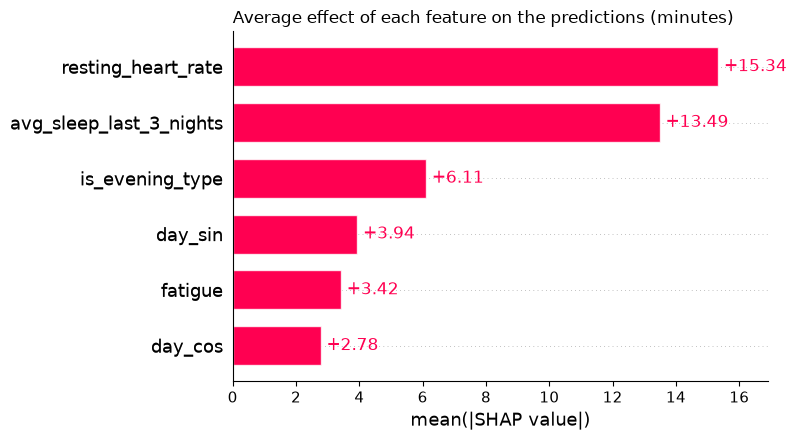

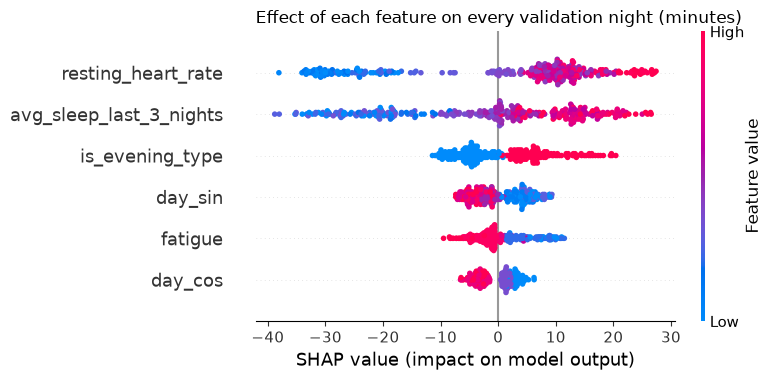

In [64]:
# SHAP for the trimmed forest (with the three-night average), already trained above.
shap_values_trimmed = shap.TreeExplainer(trim_forests["Trimmed"])(model_data.loc[validation, start_features + trimmed])

shap.plots.bar(shap_values_trimmed, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_trimmed, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

The SHAP charts barely change after trimming, and the scores get slightly worse, so removing readiness, gender and `report_missing` does not help. I keep the full body and profile + reports set.

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Trimmed,54.047,73.723,0.101,38.558,68.966
Trimmed (no average),55.769,74.211,0.089,37.304,65.204
This list,55.857,75.105,0.067,36.050,65.517
This list (no average),55.920,75.018,0.069,35.737,64.577


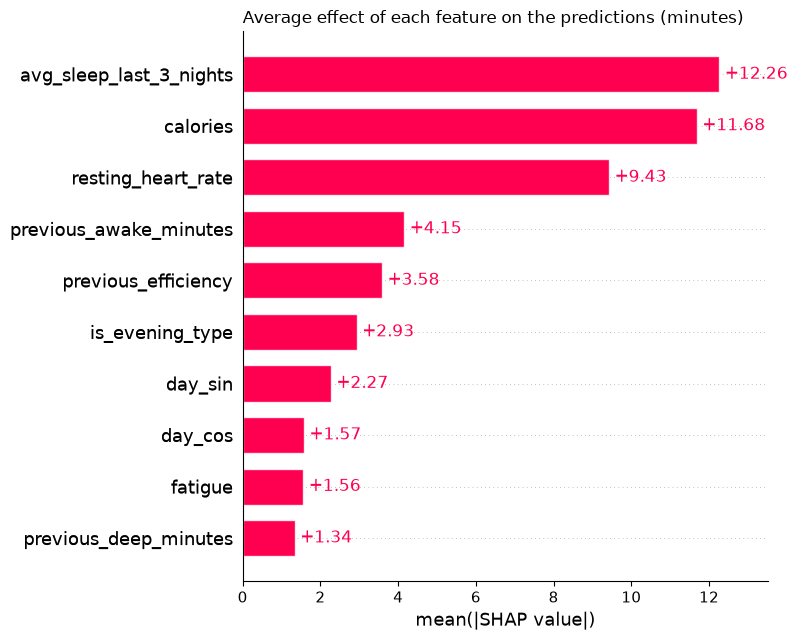

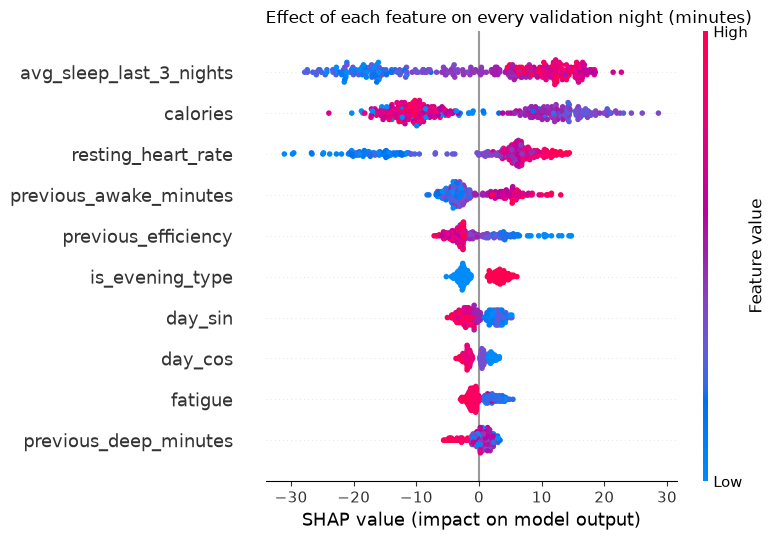

In [65]:
# The trimmed set plus calories and last night's details. Remove a feature from this list and run the cell again to see the effect.
manual_features = [
    "avg_sleep_last_3_nights", "day_sin", "day_cos",
    "resting_heart_rate", "is_evening_type", "fatigue",
    "calories",
    "previous_awake_minutes", "previous_efficiency", "previous_deep_minutes",
]
manual_forest, manual_predictions = train_forest(manual_features)
# The same list without the three-night average.
manual_no_average = [feature for feature in manual_features if feature != "avg_sleep_last_3_nights"]
_, manual_no_average_predictions = train_forest(manual_no_average)
display(scores({
    "Trimmed": trim_predictions["Trimmed"],
    "Trimmed (no average)": trim_predictions["Trimmed (no average)"],
    "This list": manual_predictions,
    "This list (no average)": manual_no_average_predictions,
}).round(3))

shap_values_manual = shap.TreeExplainer(manual_forest)(model_data.loc[validation, manual_features])
shap.plots.bar(shap_values_manual, max_display=len(manual_features), show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_manual, max_display=len(manual_features), show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

To see every feature in one chart without testing combinations, I use permutation importance on the forest with all groups: each feature is shuffled on the validation nights, one at a time, and the drop in R² shows how much the model relies on it. A bar below 0 means the model did better with that feature shuffled.

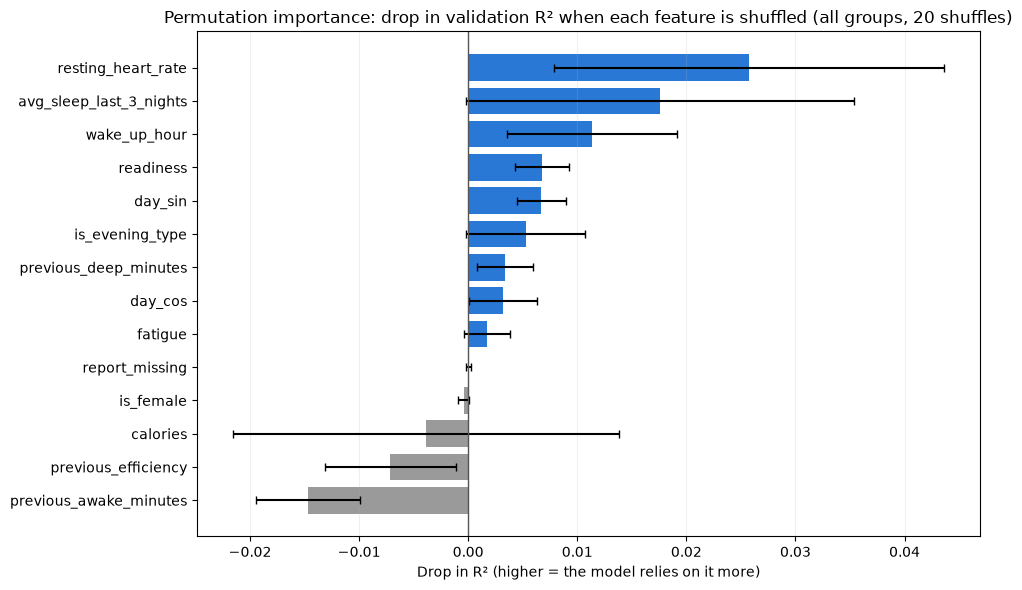

In [66]:
from sklearn.inspection import permutation_importance

# The forest with all groups, already trained in the combinations above.
all_features = start_features + group_sets["All groups"]
shuffled = permutation_importance(
    combo_forests["All groups"], model_data.loc[validation, all_features], target[validation],
    scoring="r2", n_repeats=20, random_state=SEED, n_jobs=-1,
)
importance = pd.DataFrame({"drop": shuffled.importances_mean, "spread": shuffled.importances_std}, index=all_features).sort_values("drop")

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#2a78d6" if value > 0 else "#9a9a9a" for value in importance["drop"]]
ax.barh(importance.index, importance["drop"], xerr=importance["spread"], color=colors, capsize=3)
ax.axvline(0, color="#555555", linewidth=1)
ax.set(title="Permutation importance: drop in validation R² when each feature is shuffled (all groups, 20 shuffles)",
       xlabel="Drop in R² (higher = the model relies on it more)")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Minutes awake stands out the most on the negative side: the model does clearly better with it shuffled, so it adds noise rather than information, and efficiency does the same. Calories are so spread out that they are not reliable. Resting heart rate is also spread out, but it clearly helps, and the three-night average helps too, although less certainly. The wake-up hour scores well here, but adding it in the combinations made the results worse, so it does not do much for us.

In [67]:
# The final candidates: body and profile + reports, with and without report_missing, with and without the three-night average.
without_missing = [feature for feature in profile + reports if feature != "report_missing"]

final_forests = {name: combo_forests[name] for name in ["Body and profile + reports", "Body and profile + reports (no average)"]}
final_predictions = {name: combo_predictions[name] for name in final_forests}
final_forests["Without report_missing"], final_predictions["Without report_missing"] = train_forest(start_features + without_missing)
final_forests["Without report_missing (no average)"], final_predictions["Without report_missing (no average)"] = train_forest(["day_sin", "day_cos"] + without_missing)

display(scores(final_predictions).round(3))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Body and profile + reports,53.733,73.304,0.111,39.185,68.966
Body and profile + reports (no average),54.225,72.782,0.124,37.304,65.204
Without report_missing,53.711,73.239,0.112,39.185,68.966
Without report_missing (no average),54.189,72.780,0.124,37.304,64.890


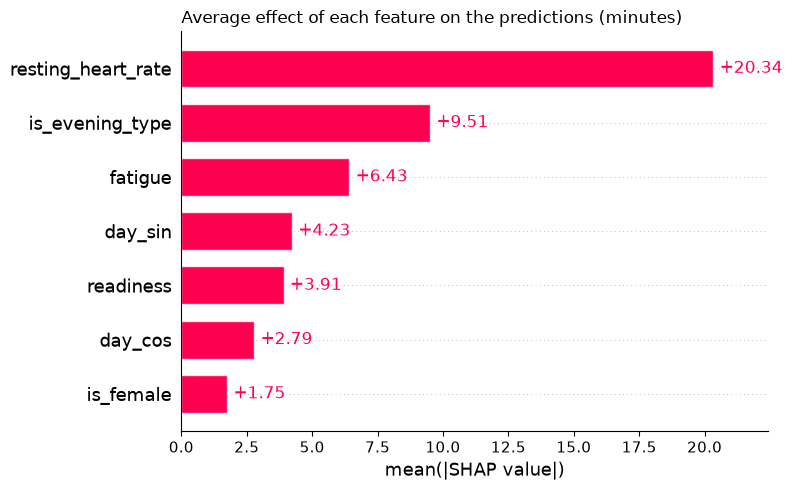

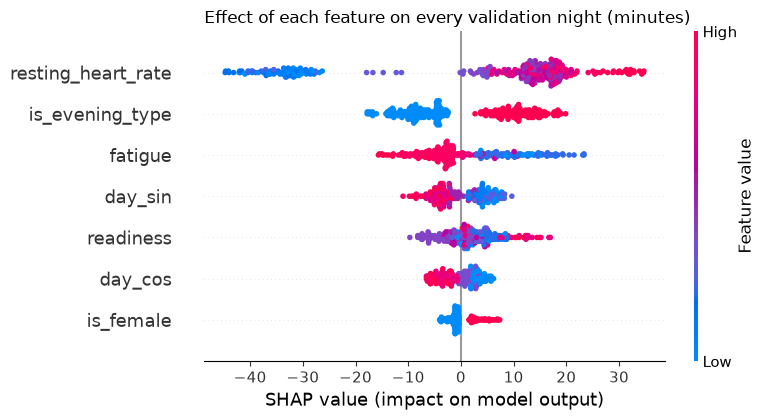

In [68]:
# SHAP for the version without report_missing and without the three-night average, already trained above.
shap_values_final = shap.TreeExplainer(final_forests["Without report_missing (no average)"])(model_data.loc[validation, ["day_sin", "day_cos"] + without_missing])

shap.plots.bar(shap_values_final, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_final, show=False)
plt.title("Effect of each feature on every validation night (minutes)", loc="left")
plt.tight_layout()
plt.show()

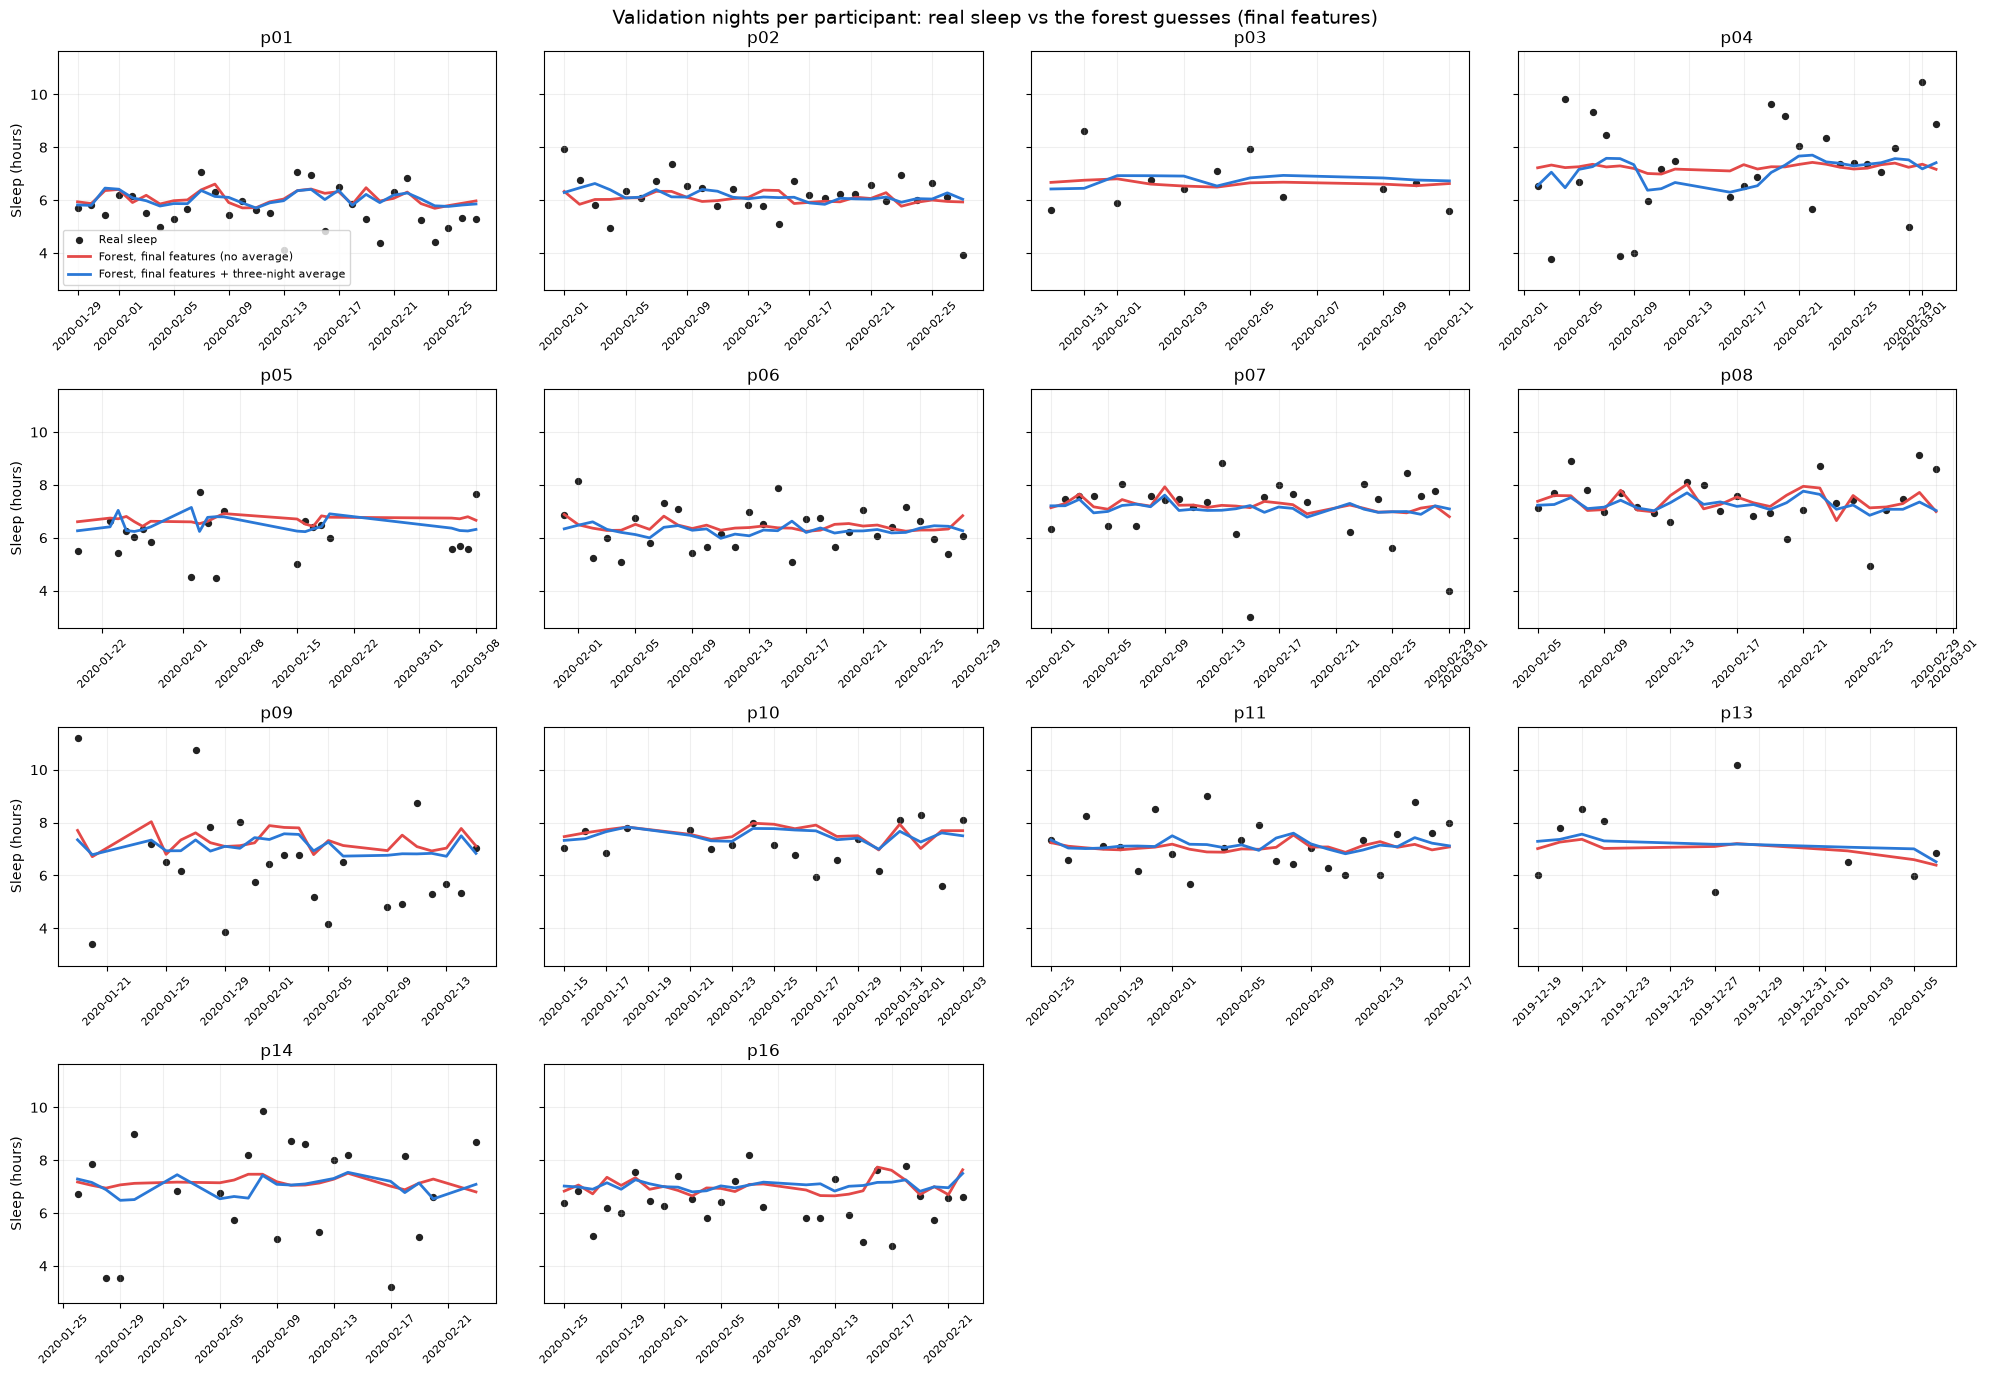

In [69]:
# The same chart for the final features, with and without the three-night average.
plot_nights({
    "Forest, final features (no average)": final_predictions["Without report_missing (no average)"],
    "Forest, final features + three-night average": final_predictions["Without report_missing"],
}, "Validation nights per participant: real sleep vs the forest guesses (final features)")

Removing `report_missing` barely changes the scores, so it adds no real value and is dropped. These are the final features: resting heart rate, gender, A/B type, fatigue, readiness and the cyclical weekday (sine and cosine), without the three-night average, as this version has the best R² and RMSE.

## Models
First I fix the final features, so every model uses the same inputs. Then I check the simple guess from the first iteration, the average of the previous seven recorded nights, on the validation nights: every model has to beat it to be worth using.

In [70]:
final_features = ["resting_heart_rate", "is_female", "is_evening_type", "fatigue", "readiness", "day_sin", "day_cos"]
model_data[final_features].describe().round(2)

,resting_heart_rate,is_female,is_evening_type,fatigue,readiness,day_sin,day_cos
count,1594.00,1594.00,1594.00,1594.00,1594.00,1594.00,1594.00
mean,58.90,0.22,0.47,2.71,4.80,0.01,0.00
std,7.27,0.41,0.50,0.61,1.72,0.71,0.71
min,44.00,0.00,0.00,1.00,0.00,-0.97,-0.90
25%,53.00,0.00,0.00,2.00,4.00,-0.78,-0.90
50%,59.00,0.00,0.00,3.00,5.00,0.00,-0.22
75%,65.00,0.00,1.00,3.00,6.00,0.78,0.62
max,76.00,1.00,1.00,5.00,10.00,0.97,1.00


In [71]:
# The average of the previous seven recorded nights, up to and including the night that ended this morning (as in the first iteration).
# It uses the sleep after the short-night correction, the same nights as the target.
seven_nights = corrected_sleep.copy()
seven_nights["past_7_sleep_minutes"] = seven_nights.groupby("participant_id")["minutes_asleep"].transform(
    lambda nights: nights.rolling(7, min_periods=1).mean()
)
model_data["past_7_sleep_minutes"] = seven_nights.set_index(["participant_id", "sleep_date"])["past_7_sleep_minutes"].reindex(
    pd.MultiIndex.from_frame(model_data[["participant_id", "date"]])
).to_numpy()

model_predictions = {"Previous 7 recorded nights": model_data.loc[validation, "past_7_sleep_minutes"].to_numpy()}
display(scores(model_predictions).round(3))

# The final models are trained on 80% of the nights (training + validation) and scored once on the test nights.
train_and_validation = train | validation
test = model_data["split"].eq("test")
test_predictions = {"Previous 7 recorded nights": model_data.loc[test, "past_7_sleep_minutes"].to_numpy()}

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Previous 7 recorded nights,54.995,76.173,0.04,40.439,67.712


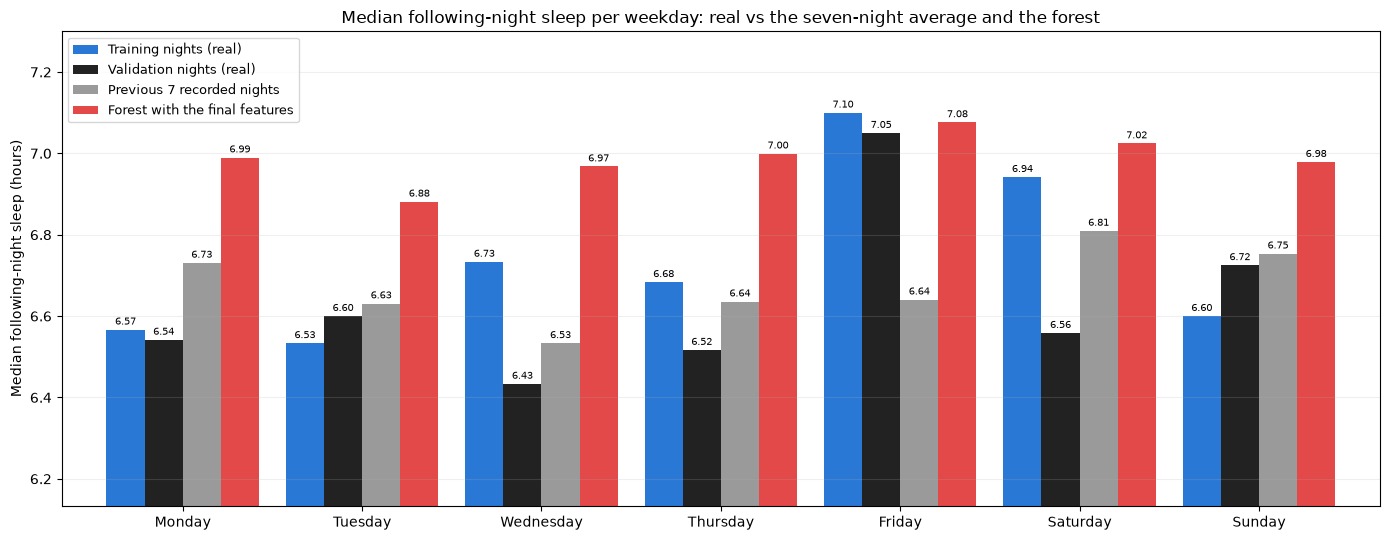

In [72]:
# Median sleep per weekday: the real nights, the seven-night average and the forest with the final features.
baseline_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
    "Previous 7 recorded nights": pd.Series(model_predictions["Previous 7 recorded nights"]).groupby(validation_days).median(),
    "Forest with the final features": pd.Series(final_predictions["Without report_missing (no average)"]).groupby(validation_days).median(),
}) / 60
baseline_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
baseline_medians.plot.bar(color=["#2a78d6", "#222222", "#9a9a9a", "#e34948"], width=0.85, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(baseline_medians.min().min() - 0.3, baseline_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: real vs the seven-night average and the forest",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

The forest with the final features overshoots on most days, while the seven-night average stays close to the real nights, because it follows each person's recent sleep. Adding the seven-night average as a feature might therefore improve the R² and the other scores.

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Previous 7 recorded nights (no model),54.995,76.173,0.040,40.439,67.712
Final features,54.189,72.780,0.124,37.304,64.890
Final features + three-night average,53.711,73.239,0.112,39.185,68.966
Final features + seven-night average,52.196,71.756,0.148,42.947,70.219


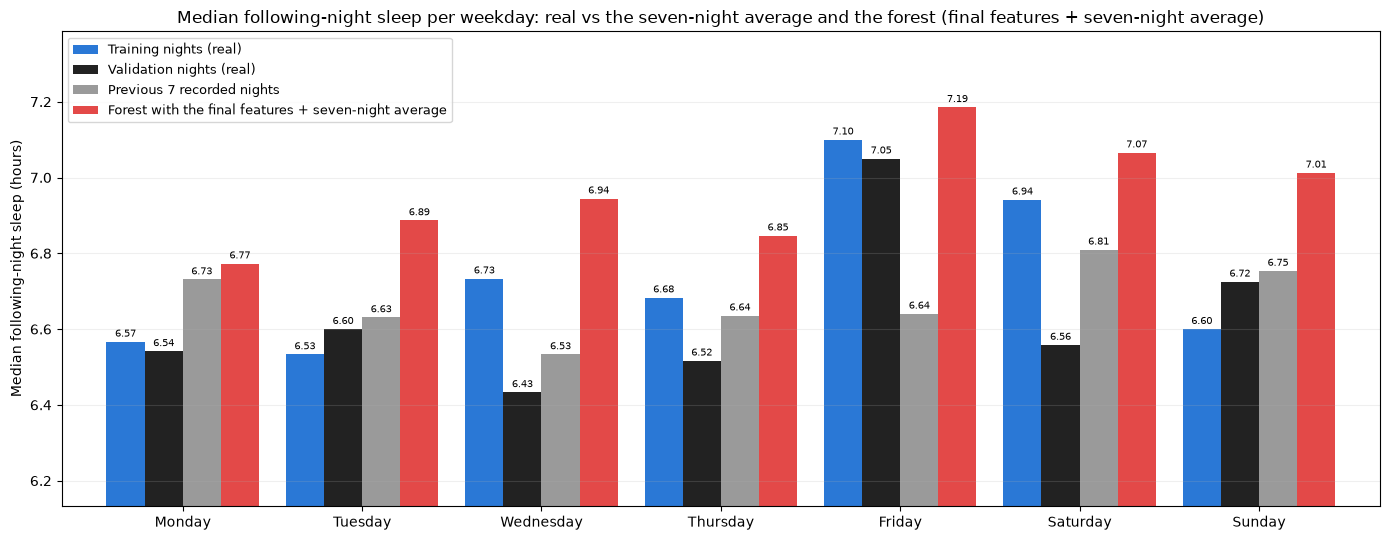

In [73]:
# The final features with the seven-night average as an input instead of the three-night average.
seven_forest, seven_predictions = train_forest(final_features + ["past_7_sleep_minutes"])
display(scores({
    "Previous 7 recorded nights (no model)": model_predictions["Previous 7 recorded nights"],
    "Final features": final_predictions["Without report_missing (no average)"],
    "Final features + three-night average": final_predictions["Without report_missing"],
    "Final features + seven-night average": seven_predictions,
}).round(3))

seven_medians = pd.DataFrame({
    "Training nights (real)": target[train].groupby(day[train]).median(),
    "Validation nights (real)": target[validation].groupby(day[validation]).median(),
    "Previous 7 recorded nights": pd.Series(model_predictions["Previous 7 recorded nights"]).groupby(validation_days).median(),
    "Forest with the final features + seven-night average": pd.Series(seven_predictions).groupby(validation_days).median(),
}) / 60
seven_medians.index = weekday_names

fig, ax = plt.subplots(figsize=(14, 5.5))
seven_medians.plot.bar(color=["#2a78d6", "#222222", "#9a9a9a", "#e34948"], width=0.85, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
# The axis does not start at 0, so the differences between the bars are visible.
ax.set_ylim(seven_medians.min().min() - 0.3, seven_medians.max().max() + 0.2)
ax.set(title="Median following-night sleep per weekday: real vs the seven-night average and the forest (final features + seven-night average)",
       xlabel="", ylabel="Median following-night sleep (hours)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

Adding the seven-night average as a feature, instead of the three-night average, improves every score: the R² goes up and the MAE goes down, which is what I am aiming for. It becomes part of the final features.

### Linear regression
The simplest model: one straight-line effect per feature. It shows how much a more flexible model like the forest actually adds.

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Previous 7 recorded nights,54.995,76.173,0.040,40.439,67.712
Random forest,52.196,71.756,0.148,42.947,70.219
Linear regression,54.929,73.464,0.107,36.677,68.339


,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Previous 7 recorded nights,51.989,67.506,0.090,36.196,68.405
Linear regression,50.987,66.235,0.124,38.344,68.098


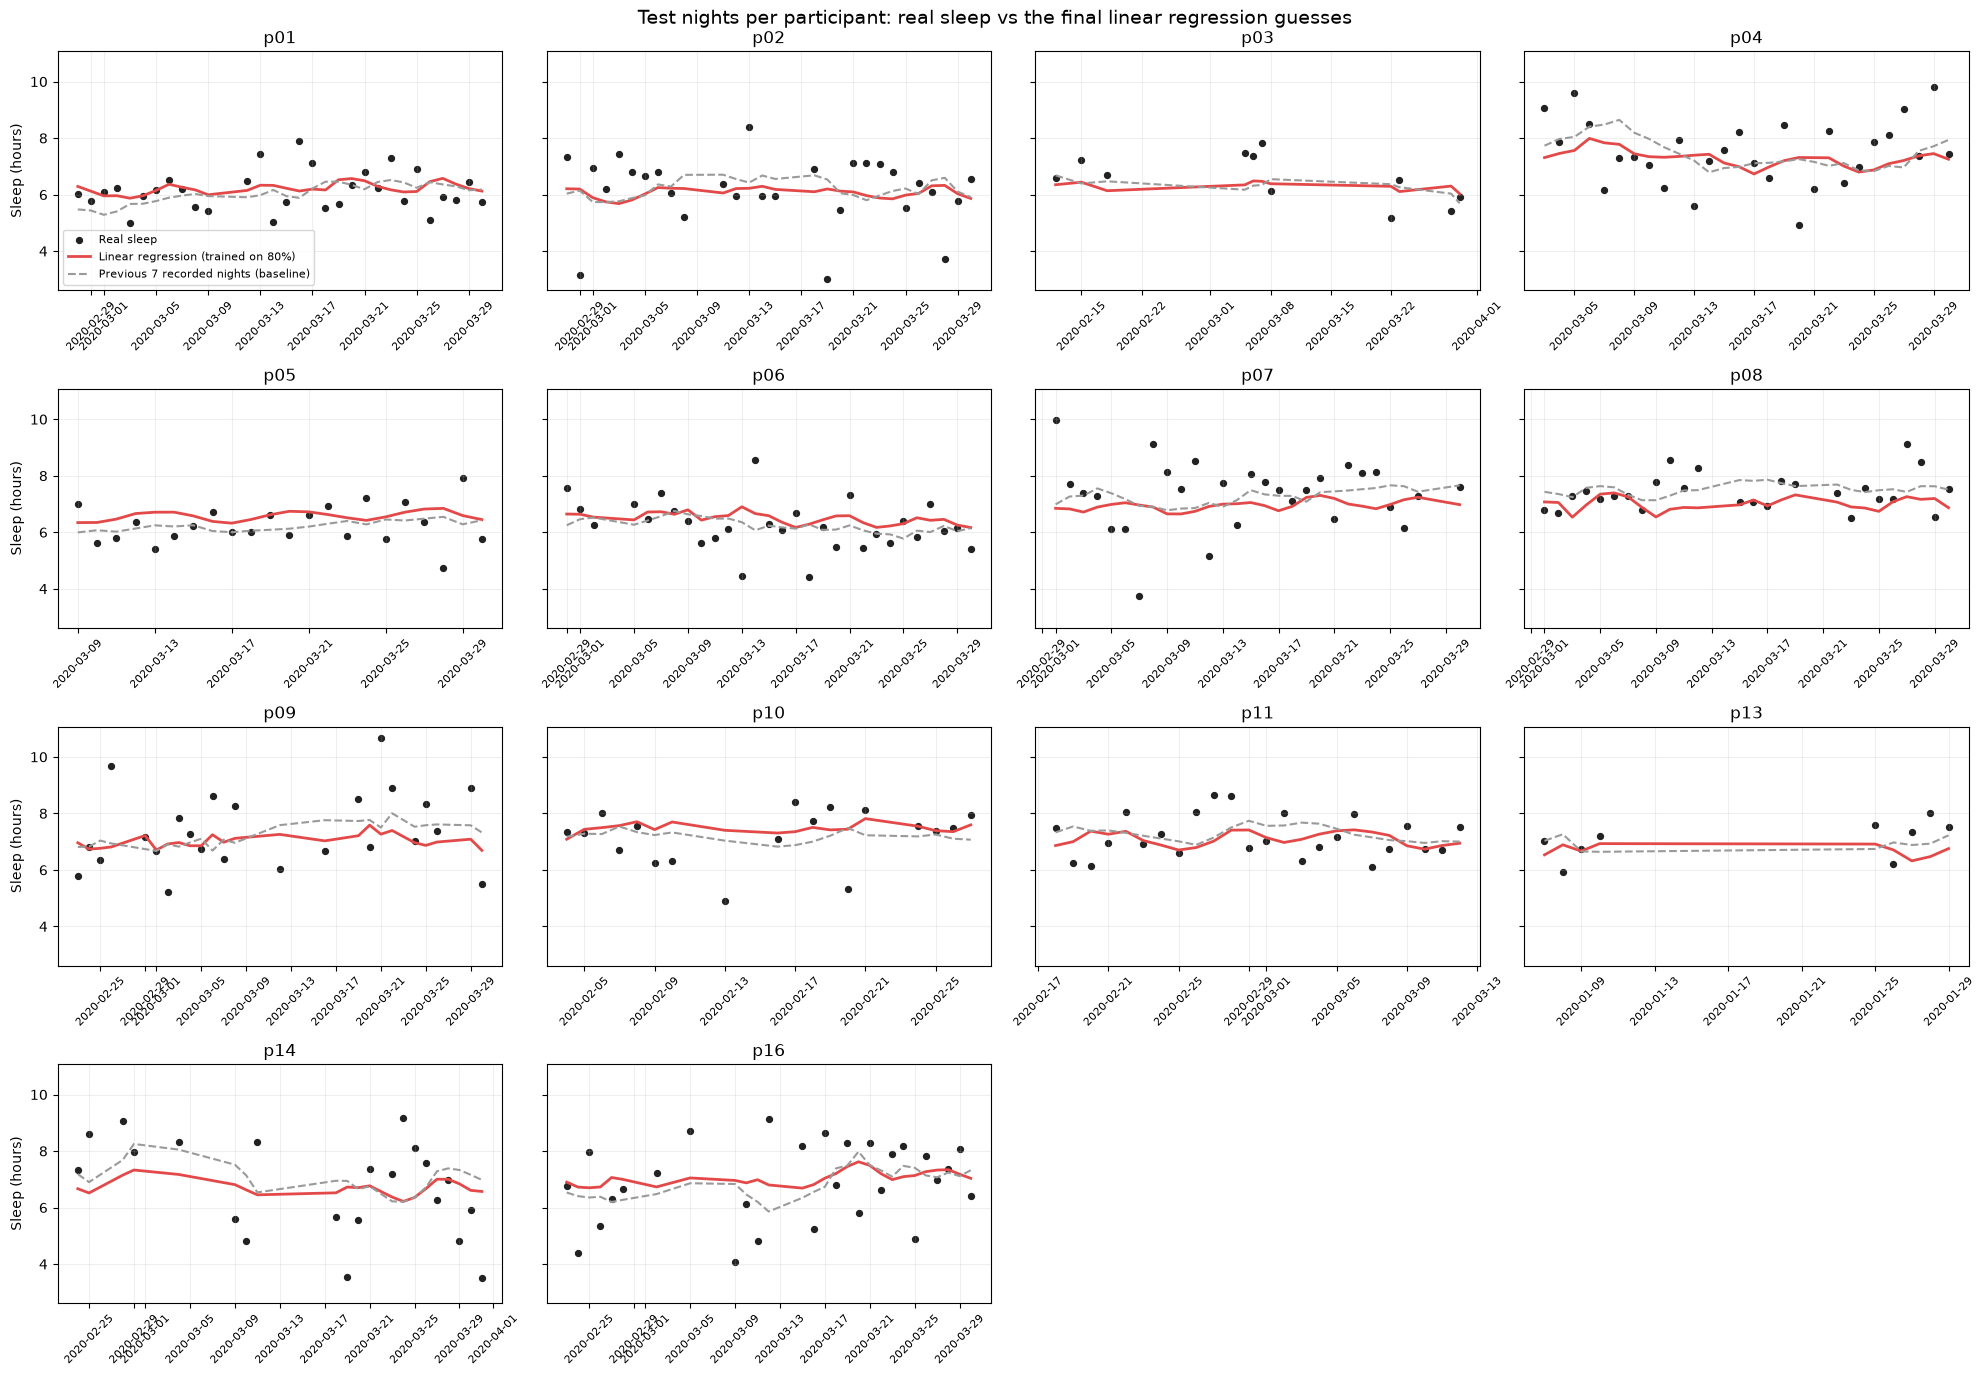

Background dataset has 1268 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1268 when initializing the masker.


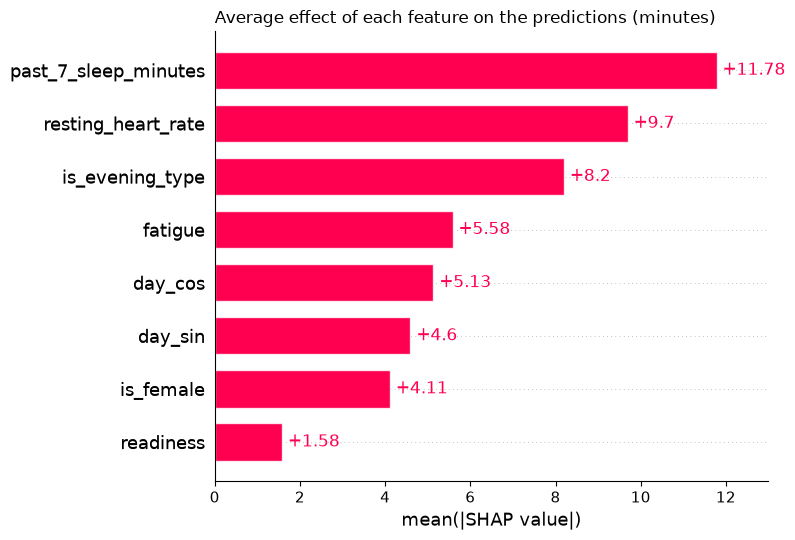

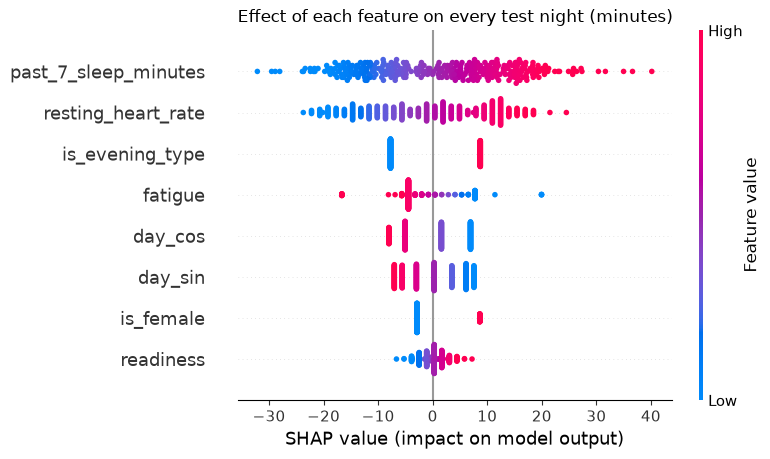

In [74]:
from sklearn.linear_model import LinearRegression

# The seven-night average joins the final features (see the test above).
final_features = final_features + ["past_7_sleep_minutes"]
model_predictions["Random forest"] = seven_predictions

linear = LinearRegression().fit(model_data.loc[train, final_features], target[train])
model_predictions["Linear regression"] = linear.predict(model_data.loc[validation, final_features])

display(scores(model_predictions).round(3))


# Final fit on 80% of the nights, scored once on the test nights.
final_linear = LinearRegression().fit(model_data.loc[train_and_validation, final_features], target[train_and_validation])
test_predictions["Linear regression"] = final_linear.predict(model_data.loc[test, final_features])
display(scores(test_predictions, nights=test).round(3))

plot_nights({"Linear regression (trained on 80%)": test_predictions["Linear regression"]},
            "Test nights per participant: real sleep vs the final linear regression guesses", nights=test)

# SHAP for the final linear regression on the test nights, with the 80% training nights as the reference.
shap_values_linear = shap.LinearExplainer(final_linear, model_data.loc[train_and_validation, final_features])(model_data.loc[test, final_features])

shap.plots.bar(shap_values_linear, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_linear, show=False)
plt.title("Effect of each feature on every test night (minutes)", loc="left")
plt.tight_layout()
plt.show()

Linear regression beats the seven-night guess on most scores, but stays behind the random forest. Its predictions follow the seven-night average closely, which SHAP confirms as its biggest feature.

### Random forest
The settings were chosen earlier (leaf size 20, 200 trees), so the forest is retrained on the training and validation nights together and scored once on the test nights.

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Previous 7 recorded nights,51.989,67.506,0.090,36.196,68.405
Linear regression,50.987,66.235,0.124,38.344,68.098
Random forest,50.296,65.150,0.152,39.264,67.178


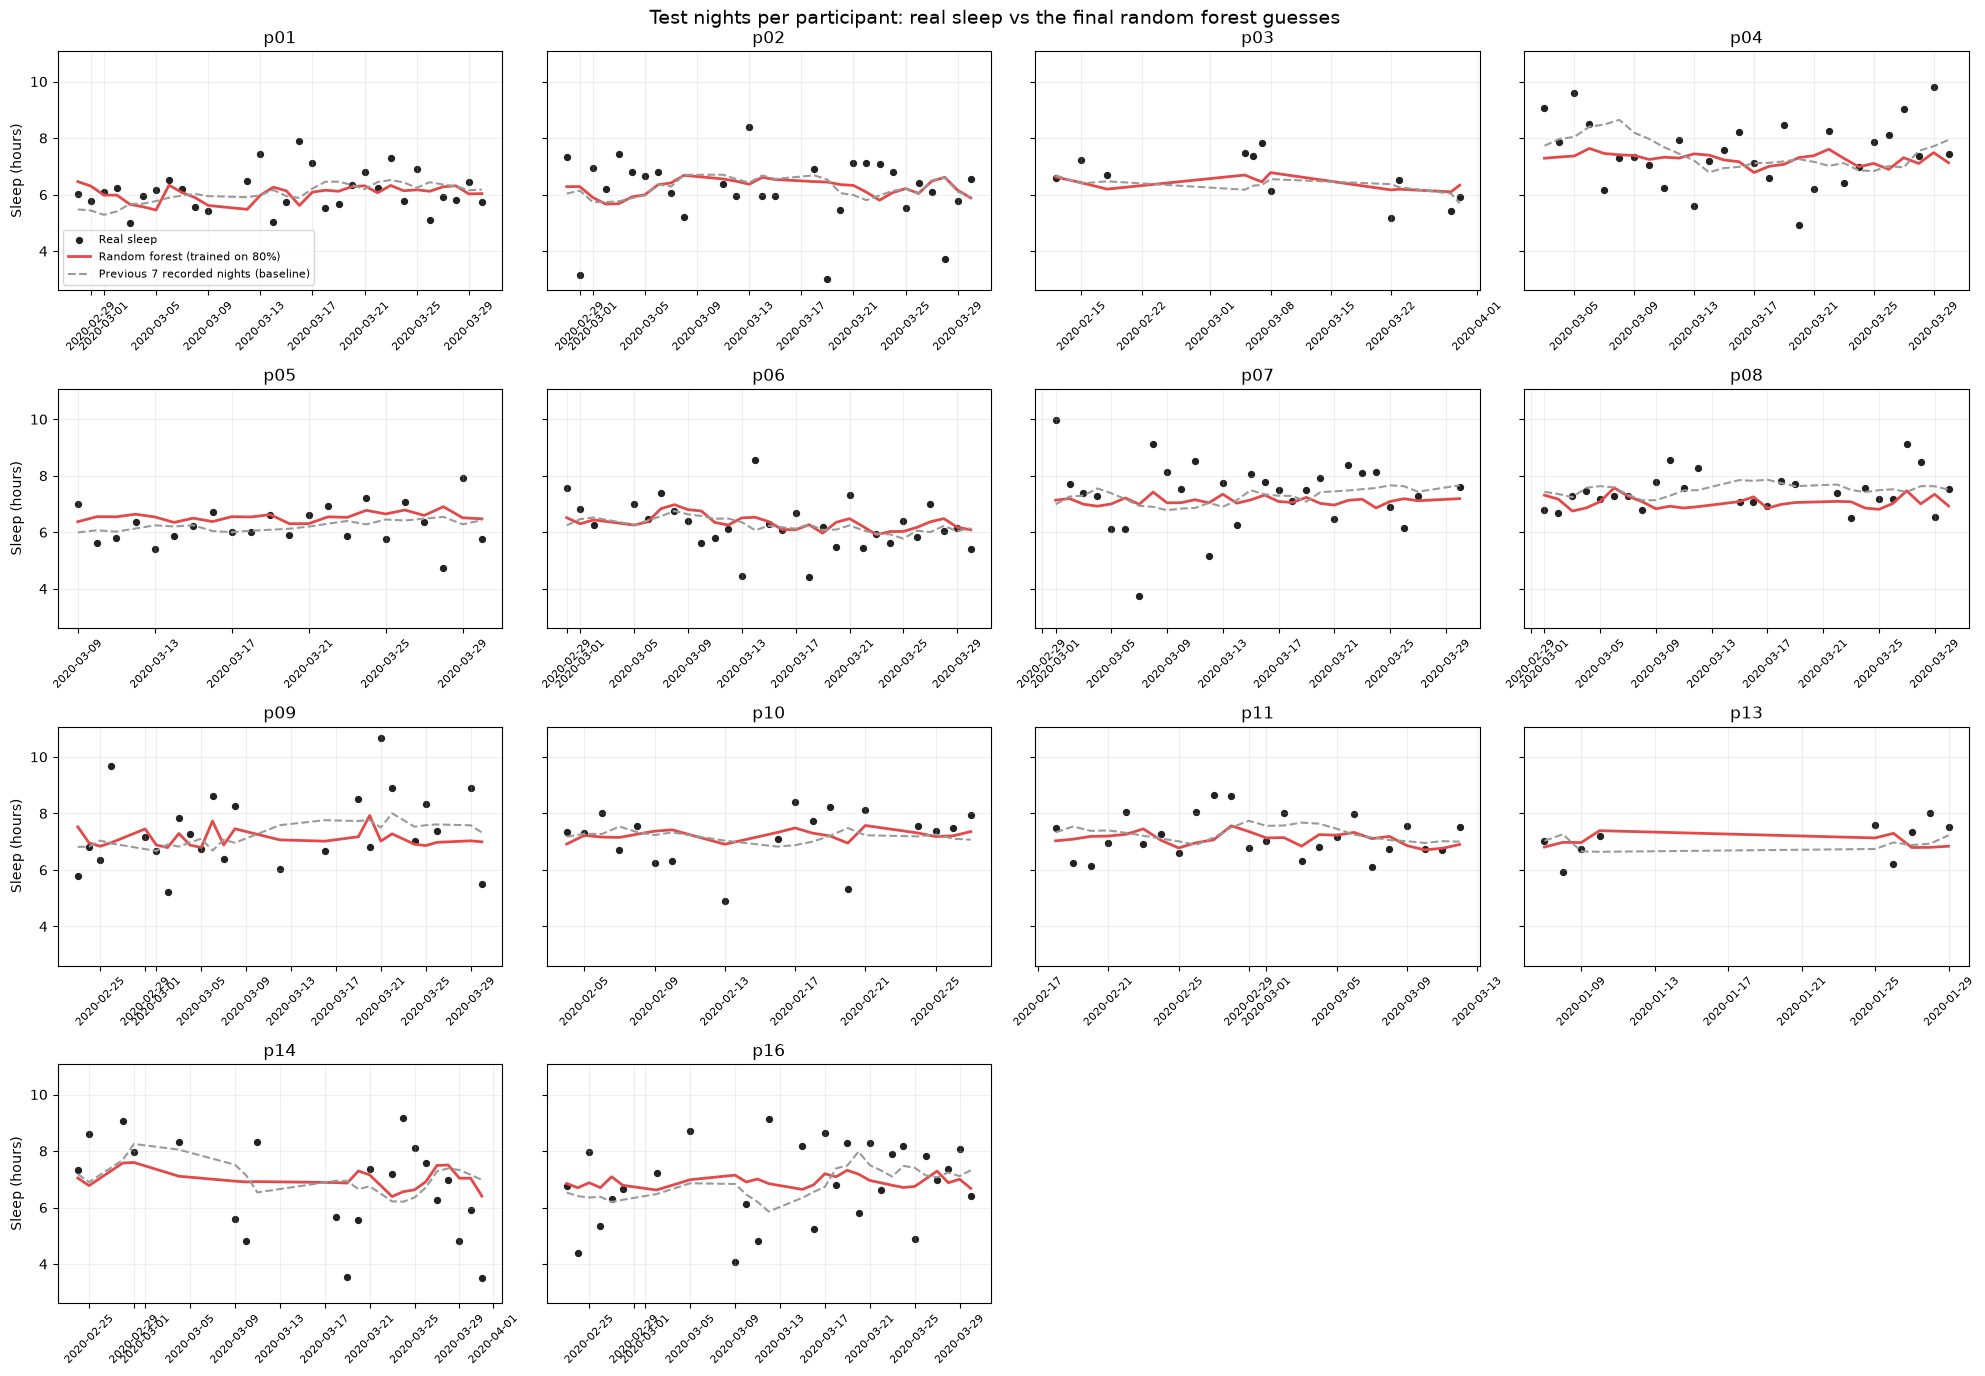

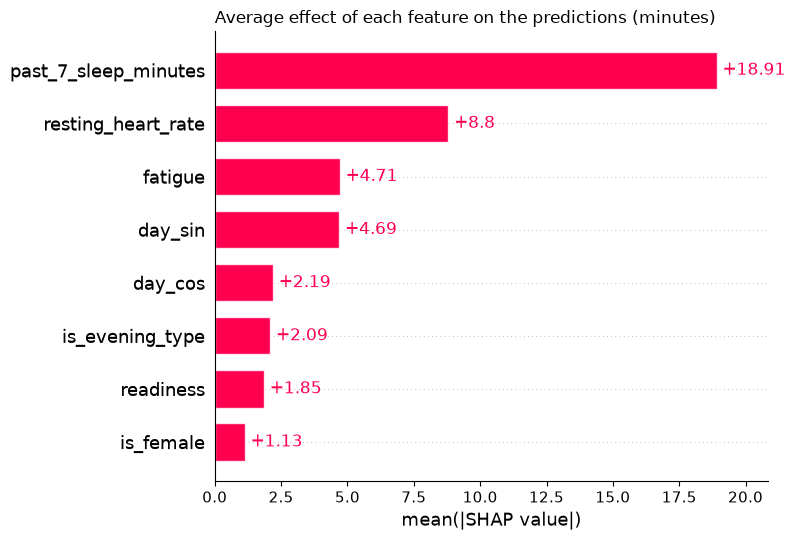

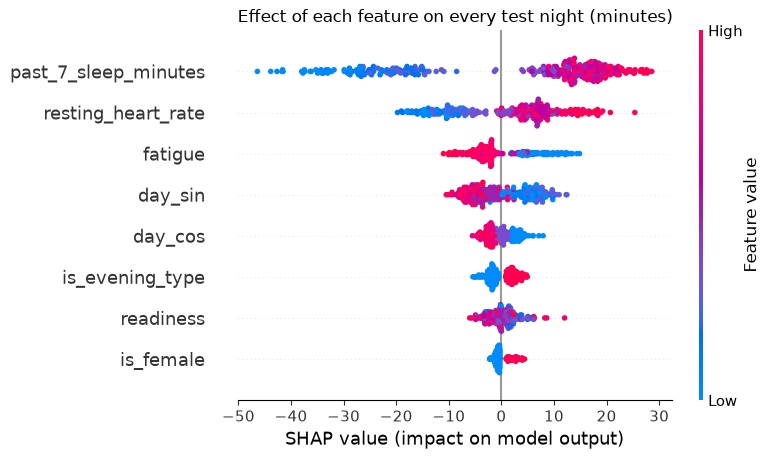

In [75]:
# Final fit on 80% of the nights (training + validation), scored once on the test nights.
final_forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
final_forest.fit(model_data.loc[train_and_validation, final_features], target[train_and_validation])
test_predictions["Random forest"] = final_forest.predict(model_data.loc[test, final_features])
display(scores(test_predictions, nights=test).round(3))

plot_nights({"Random forest (trained on 80%)": test_predictions["Random forest"]},
            "Test nights per participant: real sleep vs the final random forest guesses", nights=test)

# SHAP for the final forest on the test nights.
shap_values_forest = shap.TreeExplainer(final_forest)(model_data.loc[test, final_features])

shap.plots.bar(shap_values_forest, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_forest, show=False)
plt.title("Effect of each feature on every test night (minutes)", loc="left")
plt.tight_layout()
plt.show()

The run first, by far, seems like the best candidate. Let's see how it compares to the other models. It might be because I use it to decide the features, which might make it biased, but as long as it brings me better results, I will be happy with it. 

### Neural network
The network learns on the training nights (60%) and uses the validation nights (20%) to decide when to stop, so it does not get the 80% final fit like the other models. Its inputs and the target are scaled with the training nights only, and it is scored once on the same test nights.

/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: 

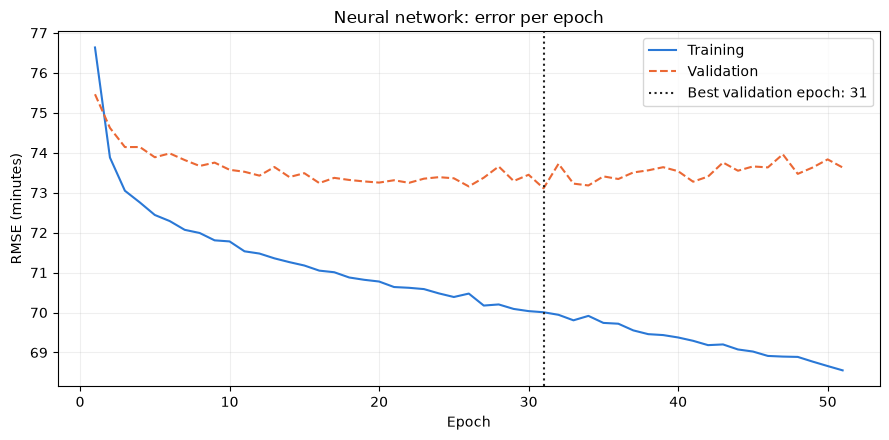

/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Previous 7 recorded nights,51.989,67.506,0.090,36.196,68.405
Linear regression,50.987,66.235,0.124,38.344,68.098
Random forest,50.296,65.150,0.152,39.264,67.178
Neural network,52.103,68.025,0.076,37.423,66.564


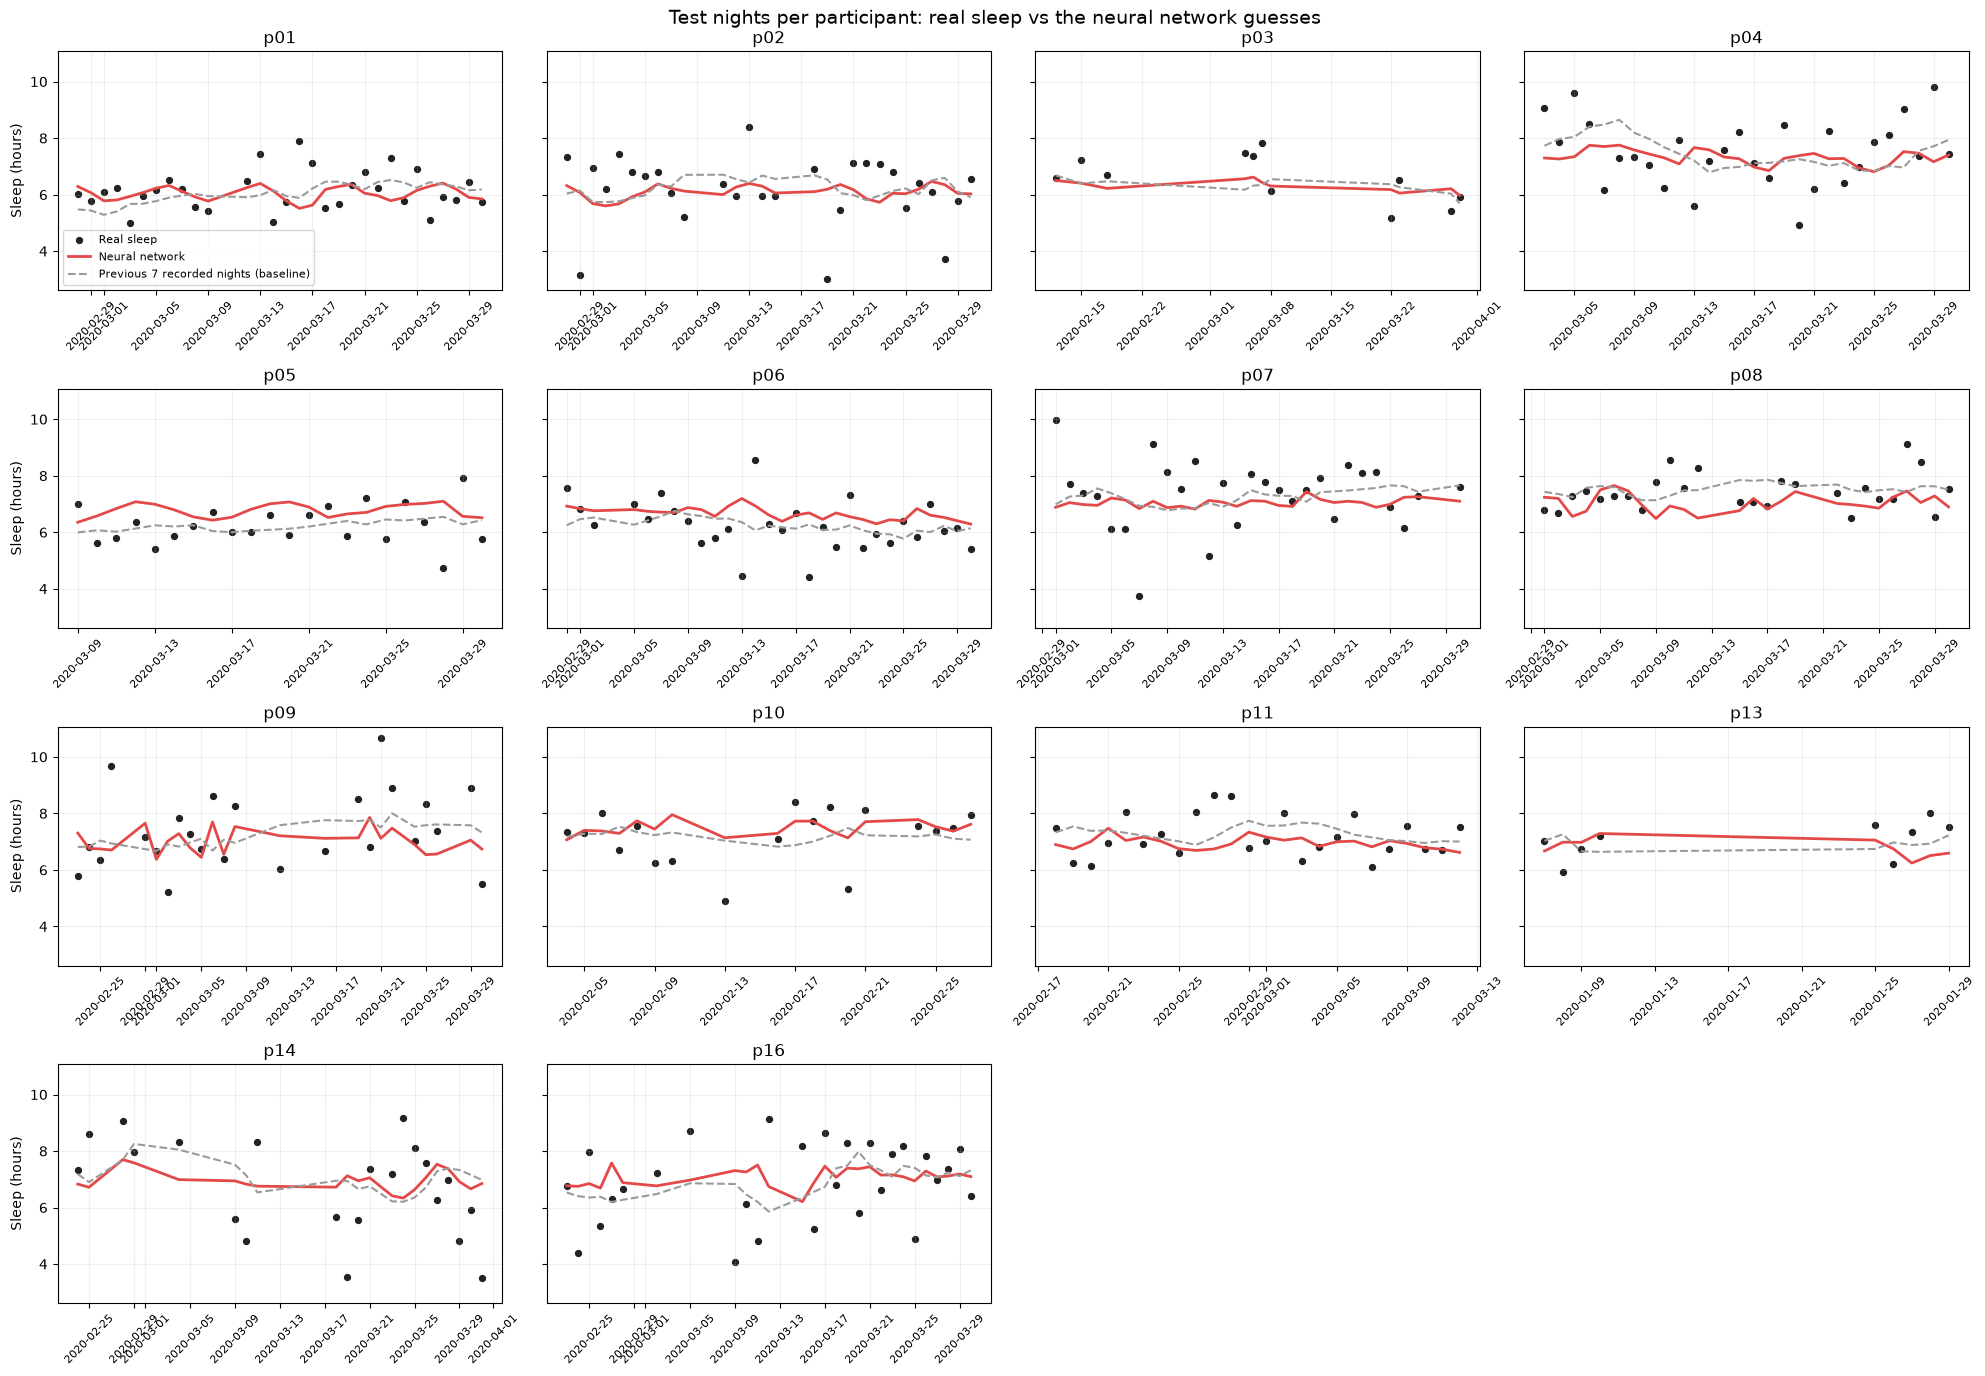

In [76]:
import logging

import lightning
import torch
from lightning import LightningDataModule, LightningModule, Trainer
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from torch import nn
from torch.utils.data import TensorDataset

logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)
lightning.seed_everything(SEED, verbose=False)
torch.set_num_threads(1)

# Scaling learned from the training nights only.
input_scaler = StandardScaler().fit(model_data.loc[train, final_features])
target_scaler = StandardScaler().fit(target[train].to_numpy().reshape(-1, 1))


def network_dataset(nights):
    """Scaled inputs and target of one split as tensors."""
    inputs = input_scaler.transform(model_data.loc[nights, final_features])
    targets = target_scaler.transform(target[nights].to_numpy().reshape(-1, 1)).ravel()
    return TensorDataset(torch.tensor(inputs, dtype=torch.float32), torch.tensor(targets, dtype=torch.float32))


datamodule = LightningDataModule.from_datasets(
    network_dataset(train), network_dataset(validation), network_dataset(test), batch_size=32, num_workers=0
)


class SleepNetwork(LightningModule):
    """One hidden layer of 64 units, as in the first iteration."""

    def __init__(self, num_features):
        super().__init__()
        self.model = nn.Sequential(nn.Linear(num_features, 64), nn.ReLU(), nn.Linear(64, 1))
        self.criterion = nn.MSELoss()

    def forward(self, features):
        return self.model(features).view(-1)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=0.001)

    def training_step(self, batch):
        features, targets = batch
        loss = self.criterion(self(features), targets)
        self.log("train_loss", loss, on_step=False, on_epoch=True, batch_size=len(targets))
        return loss

    def validation_step(self, batch):
        features, targets = batch
        self.log("val_loss", self.criterion(self(features), targets), on_step=False, on_epoch=True, batch_size=len(targets))

    def predict_step(self, batch):
        features, _ = batch
        return self(features)


network = SleepNetwork(len(final_features))
logger = CSVLogger(save_dir="lightning_logs", name="sleep_network_iteration_2")
trainer = Trainer(
    logger=logger, max_epochs=200, accelerator="cpu", deterministic=True,
    callbacks=[EarlyStopping(monitor="val_loss", mode="min", patience=20), ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1)],
    log_every_n_steps=10, enable_progress_bar=False, enable_model_summary=False,
)
trainer.fit(network, datamodule=datamodule)

# Training and validation error per epoch, in minutes.
losses = pd.read_csv(f"{logger.log_dir}/metrics.csv").groupby("epoch")[["train_loss", "val_loss"]].mean().dropna()
best_epoch = int(losses["val_loss"].idxmin()) + 1
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(losses.index + 1, np.sqrt(losses["train_loss"]) * target_scaler.scale_[0], color="#2a78d6", label="Training")
ax.plot(losses.index + 1, np.sqrt(losses["val_loss"]) * target_scaler.scale_[0], color="#eb6834", linestyle="--", label="Validation")
ax.axvline(best_epoch, color="#222222", linestyle=":", label=f"Best validation epoch: {best_epoch}")
ax.set(title="Neural network: error per epoch", xlabel="Epoch", ylabel="RMSE (minutes)")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

# The best network (by validation), scored once on the test nights.
scaled = torch.cat(trainer.predict(network, dataloaders=datamodule.test_dataloader(), ckpt_path="best")).numpy()
test_predictions["Neural network"] = target_scaler.inverse_transform(scaled.reshape(-1, 1)).ravel()
display(scores(test_predictions, nights=test).round(3))

plot_nights({"Neural network": test_predictions["Neural network"]},
            "Test nights per participant: real sleep vs the neural network guesses", nights=test)

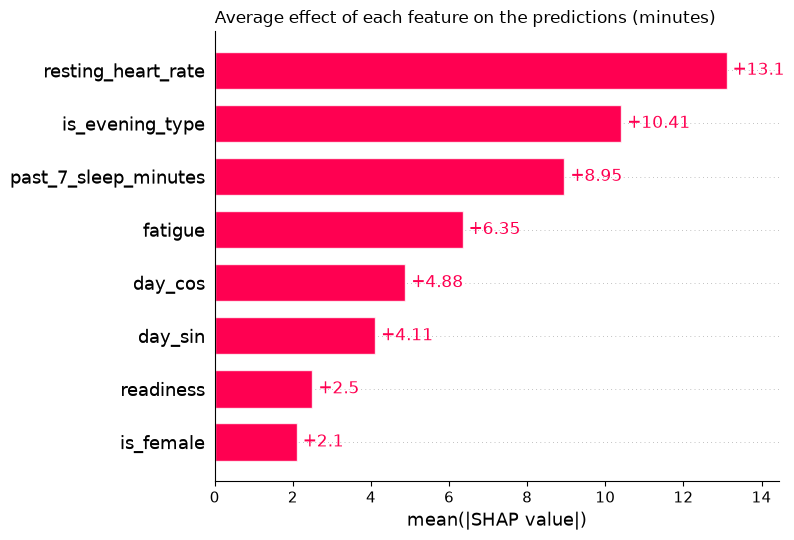

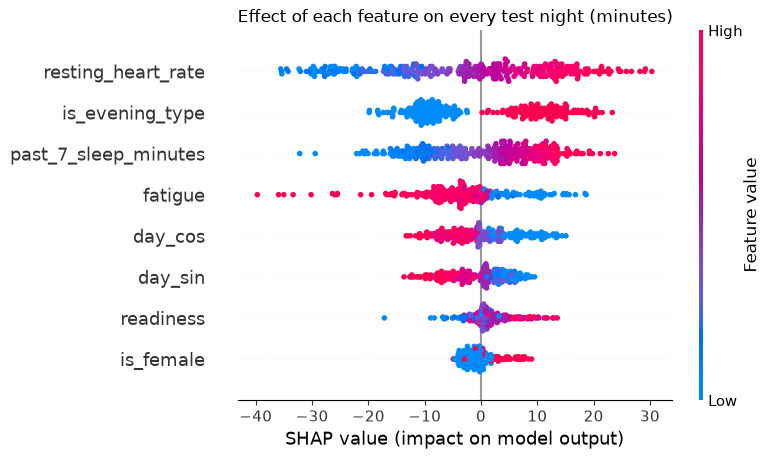

In [77]:
# SHAP for the network on the test nights, with 100 training nights as the reference.
network = SleepNetwork.load_from_checkpoint(trainer.checkpoint_callback.best_model_path, num_features=len(final_features))
network.eval()


def network_minutes(inputs):
    """The network's prediction in minutes for unscaled inputs."""
    with torch.no_grad():
        scaled = network(torch.tensor(input_scaler.transform(pd.DataFrame(inputs, columns=final_features)), dtype=torch.float32))
    return target_scaler.inverse_transform(scaled.numpy().reshape(-1, 1)).ravel()


reference = model_data.loc[train, final_features].sample(100, random_state=SEED)
shap_values_network = shap.Explainer(network_minutes, reference, seed=SEED)(model_data.loc[test, final_features], silent=True)

shap.plots.bar(shap_values_network, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_network, show=False)
plt.title("Effect of each feature on every test night (minutes)", loc="left")
plt.tight_layout()
plt.show()

The neural network does worse than in the first iteration and barely matches the seven-night guess. The error chart shows why: after the best epoch, the training error keeps falling while the validation error stays flat, so it starts memorising the training nights instead of learning patterns that carry over. More neurons or layers would likely make that worse.

### Gradient boosting
Gradient boosting builds small trees one after another, each fixing the mistakes of the ones before. First I choose its settings on the validation nights: the tree depth, the learning rate and the number of trees. Then it is retrained on 80% of the nights and scored once on the test nights.

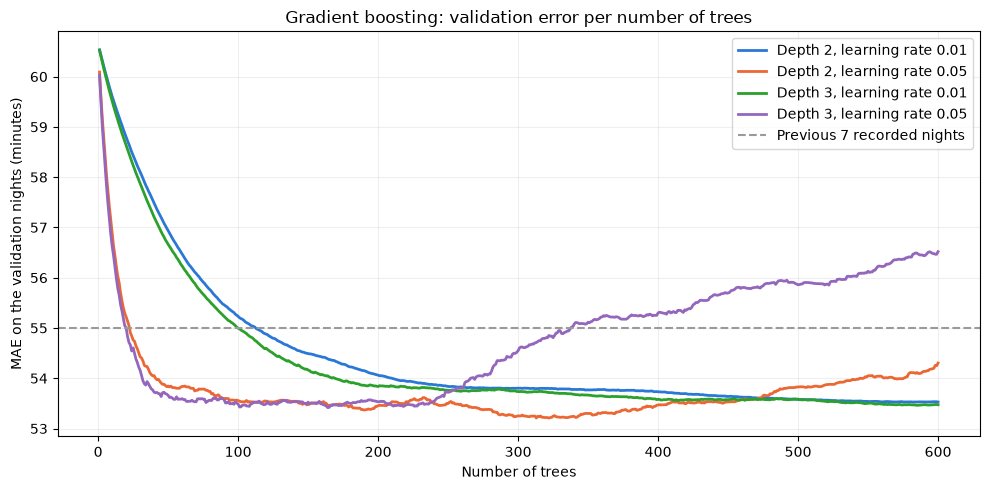

,max_depth,learning_rate,n_estimators,MAE (min)
1,2,0.05,322,53.21
3,3,0.05,164,53.42
2,3,0.01,585,53.46
0,2,0.01,583,53.53


In [78]:
from sklearn.ensemble import GradientBoostingRegressor

# Validation error after every added tree, for each depth and learning rate.
fig, ax = plt.subplots(figsize=(10, 5))
boosting_settings = []
for (depth, rate), color in zip([(2, 0.01), (2, 0.05), (3, 0.01), (3, 0.05)], ["#2a78d6", "#eb6834", "#2ca02c", "#9467bd"]):
    boosting = GradientBoostingRegressor(n_estimators=600, max_depth=depth, learning_rate=rate, random_state=SEED)
    boosting.fit(model_data.loc[train, final_features], target[train])
    errors = [np.abs(target[validation].to_numpy() - guess).mean()
              for guess in boosting.staged_predict(model_data.loc[validation, final_features])]
    ax.plot(range(1, len(errors) + 1), errors, color=color, linewidth=2, label=f"Depth {depth}, learning rate {rate}")
    boosting_settings.append({"max_depth": depth, "learning_rate": rate, "n_estimators": int(np.argmin(errors)) + 1, "MAE (min)": min(errors)})
ax.axhline(scores(model_predictions).loc["Previous 7 recorded nights", "MAE (min)"], color="#9a9a9a", linestyle="--", label="Previous 7 recorded nights")
ax.set(title="Gradient boosting: validation error per number of trees", xlabel="Number of trees", ylabel="MAE on the validation nights (minutes)")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

boosting_settings = pd.DataFrame(boosting_settings).sort_values("MAE (min)")
display(boosting_settings.round(2))

,MAE (min),RMSE (min),R²,Within 30 min (%),Within 60 min (%)
Previous 7 recorded nights,51.989,67.506,0.090,36.196,68.405
Linear regression,50.987,66.235,0.124,38.344,68.098
Random forest,50.296,65.150,0.152,39.264,67.178
Neural network,52.103,68.025,0.076,37.423,66.564
Gradient boosting,52.224,67.409,0.093,36.810,64.724


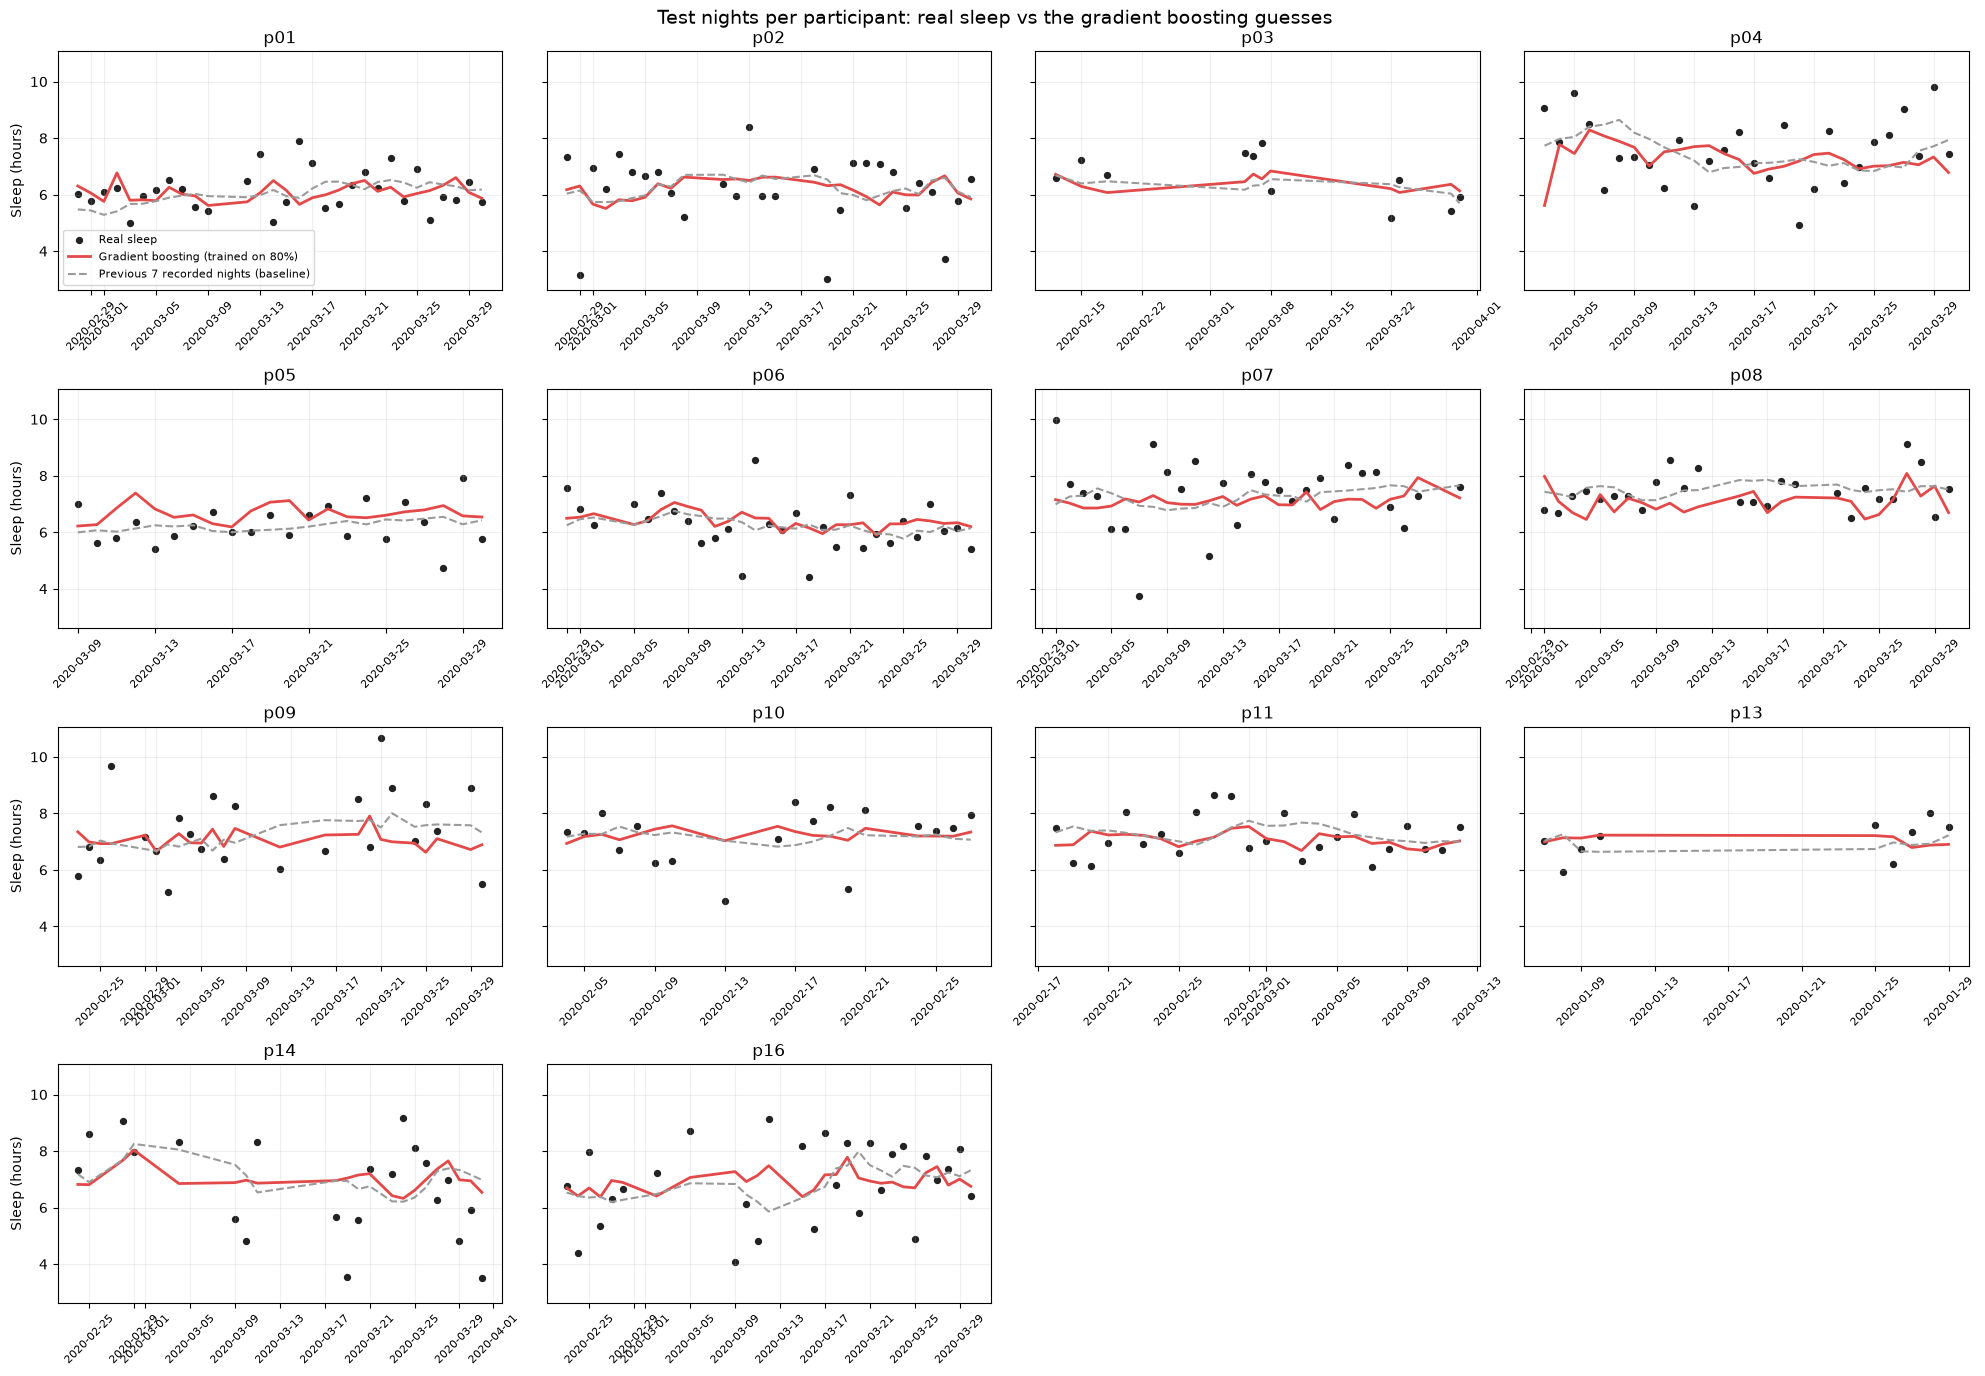

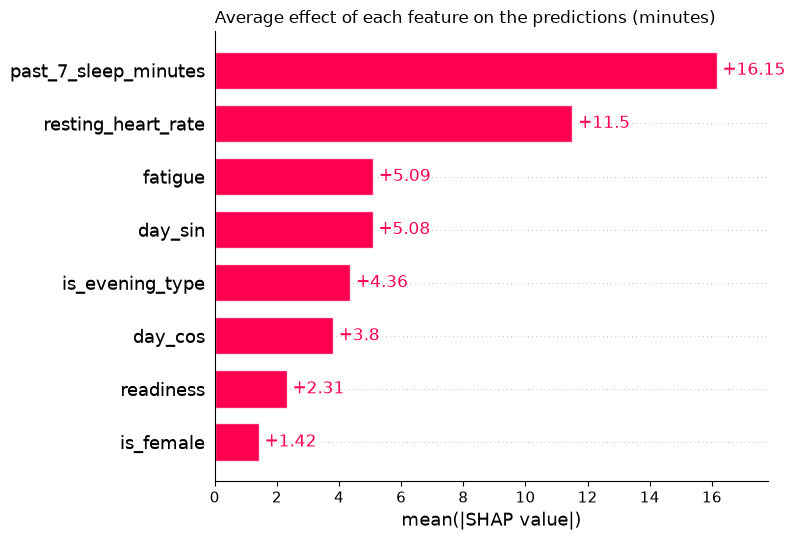

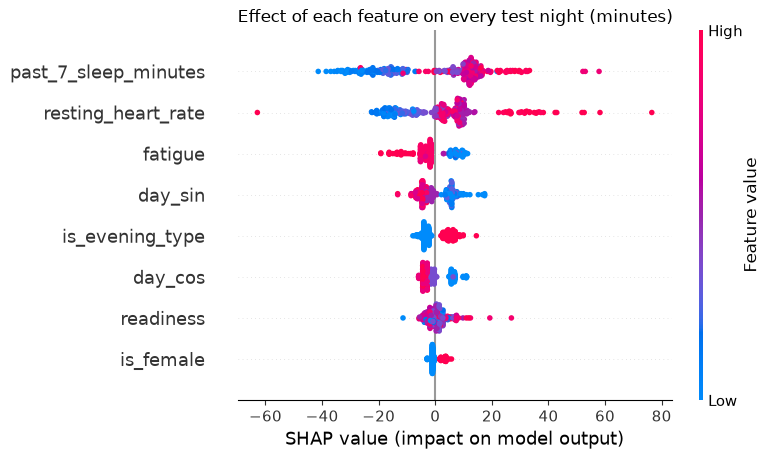

In [79]:
# The settings with the lowest validation error, retrained on 80% of the nights and scored once on the test nights.
best_boosting = boosting_settings.iloc[0]
final_boosting = GradientBoostingRegressor(
    n_estimators=int(best_boosting["n_estimators"]), max_depth=int(best_boosting["max_depth"]),
    learning_rate=best_boosting["learning_rate"], random_state=SEED,
)
final_boosting.fit(model_data.loc[train_and_validation, final_features], target[train_and_validation])
test_predictions["Gradient boosting"] = final_boosting.predict(model_data.loc[test, final_features])
display(scores(test_predictions, nights=test).round(3))

plot_nights({"Gradient boosting (trained on 80%)": test_predictions["Gradient boosting"]},
            "Test nights per participant: real sleep vs the gradient boosting guesses", nights=test)

shap_values_boosting = shap.TreeExplainer(final_boosting)(model_data.loc[test, final_features])

shap.plots.bar(shap_values_boosting, show=False)
plt.title("Average effect of each feature on the predictions (minutes)", loc="left")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_values_boosting, show=False)
plt.title("Effect of each feature on every test night (minutes)", loc="left")
plt.tight_layout()
plt.show()

The gradient network seems to be kind of underperforming, unfortunately. It doesn't seem to be doing much better than just simply averaging. It is slightly better, but it doesn't really do anything too good of a job. It starts to overfit when its trees get deeper or the learning rate is higher, and even with the best settings it ends up close to the seven-night guess. Like the network, its extra flexibility does not help on new nights.

### Final comparison
All models and the seven-night guess on the same test nights.

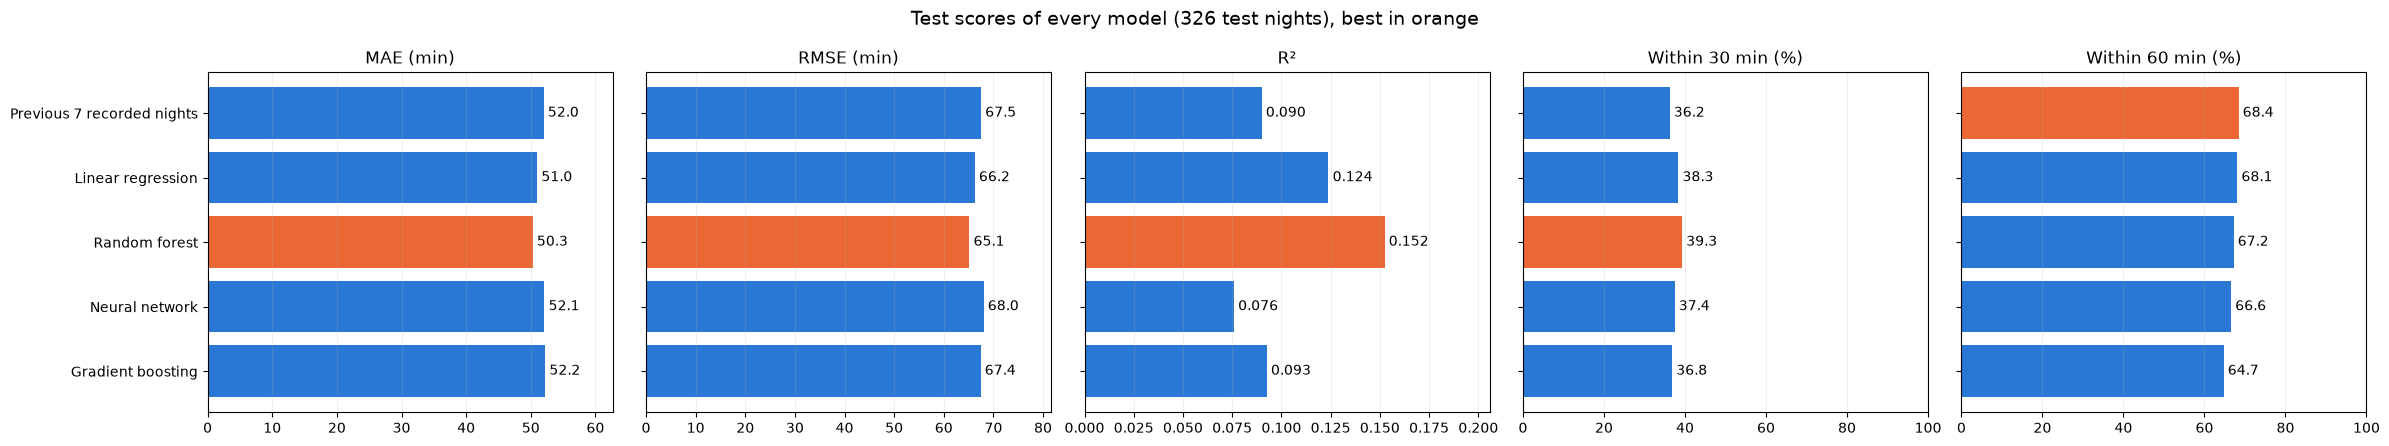

In [80]:
test_scores = scores(test_predictions, nights=test)

fig, axes = plt.subplots(1, 5, figsize=(24, 4.5), sharey=True)
for ax, score in zip(axes, test_scores.columns):
    values = test_scores[score]
    best = values.min() if score in ["MAE (min)", "RMSE (min)"] else values.max()
    bars = ax.barh(values.index, values, color=["#eb6834" if value == best else "#2a78d6" for value in values])
    ax.bar_label(bars, fmt="%.3f" if score == "R²" else "%.1f", padding=3, fontsize=10)
    if score == "R²":
        ax.set_xlim(min(0, values.min() * 1.4), values.max() * 1.35)
    elif "%" in score:
        ax.set_xlim(0, 100)
    else:
        ax.set_xlim(0, values.max() * 1.2)
    ax.set_title(score, fontsize=12)
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle(f"Test scores of every model ({test.sum()} test nights), best in orange", fontsize=14)
plt.tight_layout()
plt.show()

## Conclusion
The random forest is the best model of this iteration: on the test nights it beats the other models on most scores. Its R² is roughly 30% higher than that of the best model in the first iteration, with fewer and better-justified features.

Still, the model is not accurate enough to be useful on its own: it mostly predicts each person's usual sleep and misses the night-to-night swings. That is a limit of the dataset rather than of the models, since more flexible models did not do better. The wearable and the daily reports describe who a person is and how they feel, but not what decides a single night, such as alarms, plans or going out, so there is little room left to improve with this kind of data alone.

## Export the best model
The final random forest (trained on 80% of the nights) is saved with joblib, together with the list of features in the order it expects, so an application can load it and predict without training again.

In [81]:
import joblib
import sklearn

Path("../models").mkdir(exist_ok=True)
joblib.dump(final_forest, "../models/sleep_random_forest.joblib")
model_info = {
    "features": final_features,
    "target": "next_sleep_minutes (minutes of sleep the following night)",
    "scikit_learn_version": sklearn.__version__,
    "feature_notes": {
        "resting_heart_rate": "beats per minute, from Fitbit",
        "is_female": "1 = female, 0 = male",
        "is_evening_type": "1 = B person (evening type), 0 = A person",
        "fatigue": "morning report score 1-5 (higher = fresher)",
        "readiness": "morning report score 0-10",
        "day_sin": "sin(2 * pi * weekday / 7), weekday 0 = Monday",
        "day_cos": "cos(2 * pi * weekday / 7), weekday 0 = Monday",
        "past_7_sleep_minutes": "average sleep of the previous seven recorded nights, including the night that ended this morning",
    },
}
Path("../models/sleep_random_forest.json").write_text(json.dumps(model_info, indent=2))

# Check: the saved model gives exactly the same test predictions as the one in memory.
loaded_forest = joblib.load("../models/sleep_random_forest.joblib")
print("Same predictions after loading:", np.allclose(loaded_forest.predict(model_data.loc[test, final_features]), test_predictions["Random forest"]))
print(f"Model file size: {Path('../models/sleep_random_forest.joblib').stat().st_size / 1e6:.1f} MB")

Same predictions after loading: True
Model file size: 0.9 MB
